# Imports & Shared

In [1]:
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import lightning.pytorch as pl
from tqdm.notebook import tqdm
from matplotlib.ticker import FuncFormatter
from functools import partial
from pathlib import Path
from glob import glob
from collections import defaultdict

sys.modules['pytorch_lightning'] = pl

import redundant_feature_helpers
from redundant_features import SCALES
import terratorch_slimable
import geobench

In [ ]:
# ── Global plot style ──────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', context='talk')
sns.set_palette("bright")

# ── Paths ──────────────────────────────────────────────────────────────────
FEATURE_BASE = "./_features"
FIGURE_BASE = "./figures"
ACTIVE_SLIM = "SlimAttn+SlimFFN"   # SlimAttn+SlimFFN | SlimAttn | SlimFFN
ACTIVE_FLOPS = {
    "SlimAttn+SlimFFN": "SASF",
    "SlimAttn": "SA",
    "SlimFFN": "SF",
}

# ── Axis formatters ────────────────────────────────────────────────────────
def percent_formatter(x, pos):
    if x >= 0.01:
        return f"{x*100:3.0f}%"
    return f" {x*100:3.0f}%"

# ── Helper: apply common x-axis styling ───────────────────────────────────
def style_flop_axis(ax, mark_labels=True, xlabel='Rel. Compute Requirements'):
    ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
    ax.xaxis.minorticks_off()
    ax.tick_params(axis='both', which='both', labelsize=10)
    ax.tick_params(axis='x', which='both', labelrotation=-90)
    ax.set_xlim(left=-0.05, right=1.05)
    if mark_labels:
        ax.set_xlabel(xlabel)
    else:
        ax.set_xlabel('')

# ── mappings ────────────────────────────────────────────────────
MODEL_SHORT_TO_LABEL = {
    'dofa':             'DOFA (base)',
    'dofa_large':       'DOFA (large)',
    'prithvi2_300':     'Prithvi-EO-2.0 (300M)',
    'prithvi2_600':     'Prithvi-EO-2.0 (600M)',
    'terramind':        'TerraMind-1.0 (base)',
    'terramind_large':  'TerraMind-1.0 (large)',
    'ssl4eo_dino':      'SSL4EO ViT-S (Dino)',
    'ssl4eo_moco':      'SSL4EO ViT-S (MoCo)',
    'panopticon':       'Panopticon (base)',
    'copernicusFM':     'CopernicusFM (base)',
    'timm_mae_base':    'CV MAE',
    'timm_dinoV2_base': 'CV DinoV2',
}
METRIC_ASSIGNMENT = {
    'm-brick-kiln':   'accuracy',
    'm-eurosat':      'accuracy',
    'm-so2sat':       'accuracy',
    'm-bigearthnet':  'mAP',
    'm-cashew-plant': 'mIoU',
    'm-SA-crop-type': 'mIoU',
    #'oscd':           'macro_f1',
    'oscd':           'mIoU',
    # ---------------------------
    'CIFAR10':        'accuracy',
    'ImageNet010':    'accuracy',
    'ImageNet020':    'accuracy',
    'ImageNet050':    'accuracy',
    'ImageNet100':    'accuracy',
    'ImageNet-10':    'accuracy',
    'ImageNet-20':    'accuracy',
    'ImageNet-50':    'accuracy',
    'ImageNet-100':    'accuracy',
}
METRIC_STR = {
    'accuracy': 'Accuracy',
    'mAP': 'mAP$_\\text{macro}$',
    'mIoU': 'Mean IoU',
    'macro_f1': 'F1$_\\text{macro}$',
}

def model_name_for_plot(name):
    ret_name = MODEL_SHORT_TO_LABEL.get(name, name)
    # edge case implicit order
    if 'implicit_order' in name:
        ret_name = MODEL_SHORT_TO_LABEL.get('terramind', name)
    if ret_name == name:
        if 'MAE ViT base 1.00' in name:
            ret_name = 'MAE: regular training'
        elif 'MAE ViT base slimable' in name:
            ret_name = 'MAE: slimmable training'
        elif 'MoCo ViT base 1.00' in name:
            ret_name = 'MoCo: regular training'
        elif 'MoCo ViT base slimable' in name:
            ret_name = 'MoCo: slimmable training'
        else:
            ret_name = name
    return ret_name

# Selected "large" models for focused plots
LARGE_MODELS  = ["DOFA (large)", "TerraMind-1.0 (large)", "Prithvi-EO-2.0 (600M)"]
SMALL_MODELS  = ["DOFA (base)", "TerraMind-1.0 (base)", "Prithvi-EO-2.0 (300M)"]
PAIRED_COLORS = {m: sns.color_palette("Paired", 12)[i] for m, i in zip(LARGE_MODELS, [1, 3, 5])}
PAIRED_COLORS_SMALL = {m: sns.color_palette("Paired", 12)[i] for m, i in zip(SMALL_MODELS, [0, 2, 4])}

errorbar_setting = ('sd', 2)
legend_fontsize = 12

# for coloring of paried graphs
pairs = [
    ('dofa', 'dofa_large'),
    ('terramind', 'terramind_large'),
    ('prithvi2_300', 'prithvi2_600'),
    ('ssl4eo_moco', 'ssl4eo_dino'),
]
singles = ['panopticon', 'copernicusFM']

paired = sns.color_palette('Paired', 12)  # (light, dark) x 6 hues
model_colors = {}
for i, (a, b) in enumerate(pairs):
    model_colors[a] = paired[2 * i]
    model_colors[b] = paired[2 * i + 1]
# unpaired models get the remaining hue, distinct from each other
model_colors['panopticon'] = paired[8]    # light orange
model_colors['copernicusFM'] = paired[11] # light yellow/brown
for n,c in list(model_colors.items()):
    model_colors[MODEL_SHORT_TO_LABEL[n]] = c
# (or use gray/black via sns.color_palette('dark')[7] etc.)

hue_order = [m for p in pairs for m in p] + singles

In [ ]:
def get_legends(handles, base, fname, ncol=None, width=10):
    from matplotlib.lines import Line2D
    if ncol is None:
        ncol = len(handles)
    nrow = -(-len(handles) // ncol)  # ceiling division
    
    fig_leg, ax_leg = plt.subplots(figsize=(width, 0.5 * nrow))
    
    ax_leg.legend(
        handles=handles,
        loc='center',
        ncol=ncol,
        frameon=False,
        columnspacing=1.5,
        handletextpad=0.5,
        prop={'size': legend_fontsize},
    )
    ax_leg.axis('off')
    plt.tight_layout()
    Path(f"{base}").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{base}/{fname}", bbox_inches='tight', pad_inches=0.02)
    plt.show()

In [4]:
model_flops = pd.read_csv(f'{FEATURE_BASE}/model_flops.csv')

def read_results(model_name, dataset_name, task_name, slim=ACTIVE_SLIM, fraction_for_flop_rounding = 10, avg = False):
    path = Path(FEATURE_BASE)
    if model_name in MODEL_SHORT_TO_LABEL.keys() and not 'timm' in model_name:
        path = path / slim / model_name
    else:
        path = path / model_name
    if task_name in ['knn', 'linear']:
        filename = f'{task_name}_scores_5way_{dataset_name}.csv'
    elif task_name == 'finetune':
        filename = f'{task_name}_scores_3way_{dataset_name}.csv'
    elif task_name == 'segmentation':
        filename = f'segmentation_scores_probe_{dataset_name}.csv'
    else:
        filename = f'change-detection_scores_probe_{dataset_name}.csv'
    path = path / filename
    path = path.resolve(strict=True)

    df = pd.read_csv(path)
    if 'dim' in df.columns:
        max_dim = max(df.dim)
        df = df[df.dim == max_dim]
    if avg:
        df = df.groupby(['scale']).mean(numeric_only=True)
    df['task'] = task_name
    df['slim_style'] = slim
    df['model'] = model_name_for_plot(model_name)
    df['original_model_name'] = model_name
    df['model_style'] = 'vit_base' if model_name in ['timm_mae_base', 'timm_dinoV2_base'] or 'ViT base' in model_name else \
                        'terramind' if 'implicit_order' in model_name else model_name
    df['dataset'] = dataset_name
    # the '100%' score for Rel. Retention Rate
    reference_metric = METRIC_ASSIGNMENT[dataset_name]
    rel_reference = max(df[reference_metric])
    df['metric'] = df[reference_metric]
    df['Rel. Retention Rate'] = df[reference_metric] / rel_reference
    if avg:
        rel_reference_100 = df[reference_metric][1.0]
    else:
        rel_reference_100 = df[np.isclose(df.scale, 1.0)][reference_metric].iloc[0]
    df['Rel. Retention Rate of 100%'] = df[reference_metric] / rel_reference_100

    flop_col = f'flops_{ACTIVE_FLOPS[slim]}'  # e.g. 'flops_SASF'

    df = df.merge(
        model_flops[['model', 'scale', flop_col]].rename(columns={'model': 'model_style'}),
        on=['model_style', 'scale'],
        how='left'
    ).rename(columns={flop_col: 'flops'})
    rel_reference = max(df.flops)  # If the max flops are not at 100% model, everything is shifted!
    df['Exact Rel. Compute Requirement'] = df.flops / rel_reference
    df['Rounded Rel. Compute Requirement'] = (df['Exact Rel. Compute Requirement'] * fraction_for_flop_rounding).astype(int) / fraction_for_flop_rounding

    df = df.reset_index(drop=True).drop(columns=['Unnamed: 0', 'dim', 'seed', 'model_style'], errors='ignore')
    return df

# read_results('terramind_large', 'm-SA-crop-type', 'segmentation', avg=True)

# Main Paper

## 1. RS vs CV

### General
not in paper

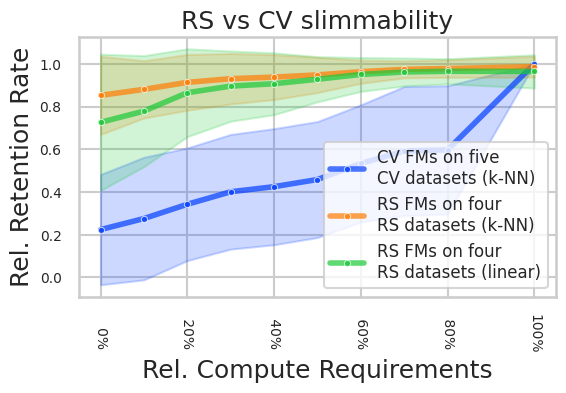

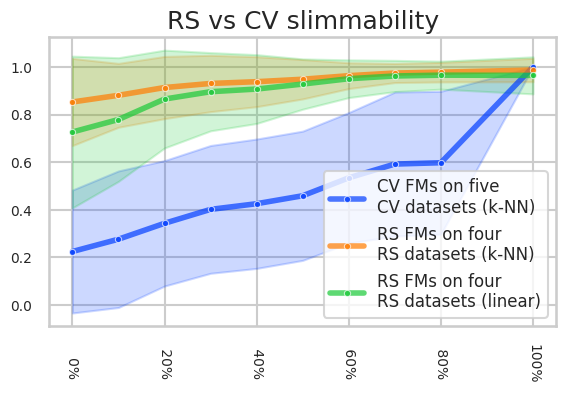

In [8]:
domain_args = [['CV', (model, dataset, 'knn')] 
               for model in ['timm_mae_base', 'timm_dinoV2_base'] 
               for dataset in ['ImageNet010', 'ImageNet020', 'ImageNet050', 'ImageNet100', 'CIFAR10']]
domain_args +=[[f'RS {task}', (model, dataset, task)] 
               for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'copernicusFM'] 
               for dataset in ['m-brick-kiln', 'm-eurosat', 'm-so2sat', 'm-bigearthnet']
               for task in ['knn', 'linear']]
dfs = []
for domain, args in domain_args:
    part_df = read_results(*args, fraction_for_flop_rounding=10)
    part_df['domain'] = domain
    dfs.append(part_df)

df = pd.concat(dfs).reset_index(drop=True)
df = pd.concat(dfs).sort_values(['domain', 'model','scale']).reset_index(drop=True)

for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))
    
    #ax.set_xscale('log')
    sns.lineplot(
        data=df,
        # if axes is log scale, use 'rel_flops_log_round', else 'rel_flops_round'
        x='Rounded Rel. Compute Requirement',
        y="Rel. Retention Rate",
        marker='.', hue="domain",
        ax=ax,
        alpha=0.7, errorbar=errorbar_setting,
        linewidth=4
    )
    
    handles, labels = ax.get_legend_handles_labels()
    labels[0] = 'CV FMs on five\nCV datasets (k-NN)'
    labels[1] = 'RS FMs on four\nRS datasets (k-NN)'
    labels[2] = 'RS FMs on four\nRS datasets (linear)'
    
    ax.legend(handles, labels, loc='lower right', fontsize=legend_fontsize)
    ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
    ax.xaxis.minorticks_off()
    if mark_axis_legend:
        ax.set_xlabel('Rel. Compute Requirements')
        ax.set_ylabel('Rel. Retention Rate')
    else:
        ax.set_xlabel('')
        ax.set_ylabel('')
    ax.tick_params(axis='both', which='both', labelsize=10)
    ax.tick_params(axis='x', which='both', labelrotation=-90)
    ax.set_xlim(left=-0.05, right=1.05)
    plt.tight_layout()
    Path(f"{FIGURE_BASE}/post_hoc").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{FIGURE_BASE}/post_hoc/post_hoc_slimming_existing_fms_average{'' if mark_axis_legend else '_nolegend'}.pdf")
    plt.title("RS vs CV slimmability")
    plt.show()

### More specific

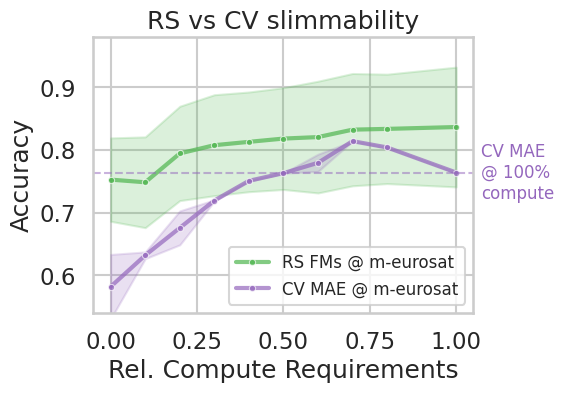

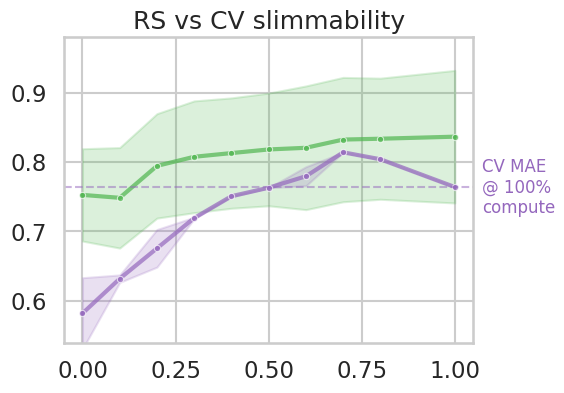

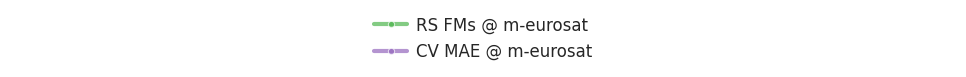

In [25]:
# ── 1. RS FMs on RS classification datasets ───────────────────────────────
rs_dfs = []
for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large',
              'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'copernicusFM']:
    for dataset in ['m-eurosat']:
        part_df = read_results(model, dataset, 'knn', fraction_for_flop_rounding=10)
        part_df['condition'] = 'RS FMs @ m-eurosat'
        rs_dfs.append(part_df)
rs_df = pd.concat(rs_dfs)

# ── 2. CV baselines – one line per condition ──────────────────────────────
cv_specs = [
    ('timm_mae_base',    'm-eurosat',    'knn', 'CV MAE @ m-eurosat'),
    #('timm_dinoV2_base',    'm-eurosat',    'knn', 'CV DINOv2 @ m-eurosat'),
]

cv_dfs = []
for model, dataset, task, label in cv_specs:
    part_df = read_results(model, dataset, task, fraction_for_flop_rounding=10)
    part_df['condition'] = label
    cv_dfs.append(part_df)
cv_df = pd.concat(cv_dfs)

# ── 3. Combine ────────────────────────────────────────────────────────────
df = pd.concat([rs_df, cv_df]).reset_index(drop=True)

# ── 4. Plot order & colours ───────────────────────────────────────────────
CONDITION_ORDER = [
    'RS FMs @ m-eurosat',
    'CV MAE @ m-eurosat',
    #'CV DINOv2 @ m-eurosat',
]

CONDITION_COLORS = {
    'RS FMs @ m-eurosat':    '#4eb54e',  # green
    'CV MAE @ m-eurosat':    '#9467bd',  # purple
    #'CV DINOv2 @ m-eurosat': '#c736c4',  # pink
}

# ── 5. Draw ───────────────────────────────────────────────────────────────
for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))

    sns.lineplot(
        data=df,
        x='Rounded Rel. Compute Requirement',
        y='metric',
        hue='condition',
        hue_order=CONDITION_ORDER,
        palette=CONDITION_COLORS,
        marker='.',
        ax=ax,
        alpha=0.7,
        linewidth=3,
        errorbar=errorbar_setting,
    )

    # Horizontal dashed line at CV MAE full-scale accuracy
    cv_full_acc = df[(df.condition == 'CV MAE @ m-eurosat') & 
                     (df.scale == 1.0)]['metric'].mean()
    ax.axhline(
        y=cv_full_acc,
        color='#9467bd',      # match CV MAE line colour
        linestyle='--',
        linewidth=1.5,
        alpha=0.5,
    )
    ax.text(
        1.02, cv_full_acc,
        'CV MAE\n@ 100%\ncompute',
        transform=ax.get_yaxis_transform(),
        va='center', ha='left',
        fontsize=legend_fontsize,
        color='#9467bd',
    )

    # Horizontal dashed line at CV MAE full-scale accuracy
    cv_full_acc = df[(df.condition == 'CV DINOv2 @ m-eurosat') & 
                     (df.scale == 1.0)]['metric'].mean()
    ax.axhline(
        y=cv_full_acc,
        color='#c736c4',      # match CV DinoV2 line colour
        linestyle='--',
        linewidth=1.5,
        alpha=0.5,
    )
    ax.text(
        1.02, cv_full_acc,
        'CV DINOv2\n@ 100%\ncompute',
        transform=ax.get_yaxis_transform(),
        va='center', ha='left',
        fontsize=legend_fontsize,
        color='#c736c4',
    )
    shared_handles_1, shared_labels = ax.get_legend_handles_labels()

    if mark_axis_legend:
        ax.set_xlabel('Rel. Compute Requirements')
        ax.set_ylabel('Accuracy')
        ax.legend(loc='lower right', fontsize=legend_fontsize)
    else:
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.legend([],[], frameon=False)
    ax.set_ylim(bottom=0.54, top=0.98)

    plt.tight_layout()
    Path(f"{FIGURE_BASE}/post_hoc").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{FIGURE_BASE}/post_hoc/CV_vs_RS_m-eurosat{'' if mark_axis_legend else '_nolegend'}.pdf", bbox_inches='tight')
    plt.title("RS vs CV slimmability")
    plt.show()

get_legends(shared_handles_1, f"{FIGURE_BASE}/legends", 'CV_vs_RS_retention_eurosat_legend_only.pdf', ncol=1)
#print(df[df.dataset.isin(['m-eurosat', 'ImageNet010', 'ImageNet100'])].groupby(['Rounded Rel. Compute Requirement', 'model', 'dataset']).mean(numeric_only=True).reset_index().groupby(['model', 'dataset']).min(numeric_only=True).reset_index()[['Rounded Rel. Compute Requirement', 'model', 'dataset', 'metric', 'Rel. Retention Rate of 100%']].sort_values(by=['dataset', 'model', 'Rounded Rel. Compute Requirement']).to_markdown())

In [48]:
df[(df.condition == "RS FMs @ m-eurosat") & (df['Rounded Rel. Compute Requirement'] == 0.0)]['Rel. Retention Rate of 100%'].max()
#df[(df.condition == "CV MAE @ m-eurosat") & (df['Rounded Rel. Compute Requirement'] == 0.0)]['Rel. Retention Rate of 100%'].mean()

0.9711192153990875

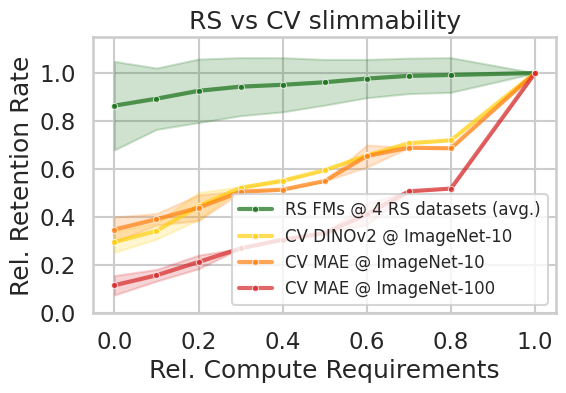

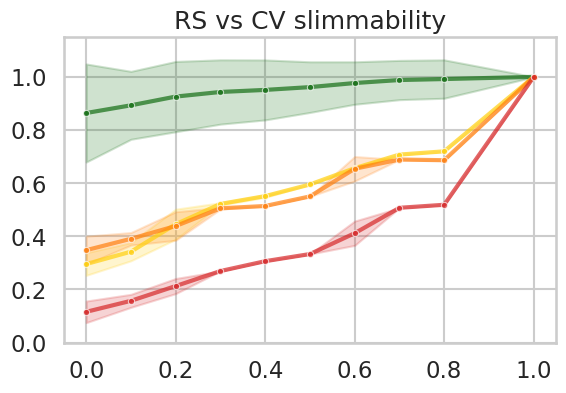

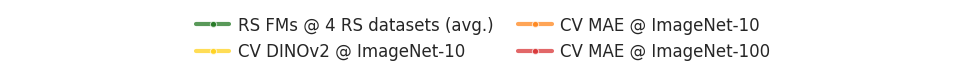

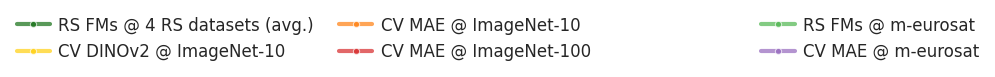

In [9]:
from matplotlib.lines import Line2D
# ── 1. RS FMs on RS classification datasets ───────────────────────────────
rs_dfs = []
for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large',
              'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'copernicusFM']:
    for dataset in ['m-brick-kiln', 'm-eurosat', 'm-so2sat', 'm-bigearthnet']:
        part_df = read_results(model, dataset, 'knn', fraction_for_flop_rounding=10)
        part_df['condition'] = 'RS FMs @ 4 RS datasets (avg.)'
        rs_dfs.append(part_df)
rs_df = pd.concat(rs_dfs)

# ── 2. CV baselines – one line per condition ──────────────────────────────
cv_specs = [
    ('timm_dinoV2_base', 'ImageNet010',  'knn', 'CV DINOv2 @ ImageNet-10'),
    ('timm_mae_base',    'ImageNet010',  'knn', 'CV MAE @ ImageNet-10'),
    #('timm_mae_base',    'CIFAR10',      'knn', 'CV MAE @ CIFAR-10'),
    ('timm_mae_base',    'ImageNet100',  'knn', 'CV MAE @ ImageNet-100'),
]

cv_dfs = []
for model, dataset, task, label in cv_specs:
    part_df = read_results(model, dataset, task, fraction_for_flop_rounding=10)
    part_df['condition'] = label
    cv_dfs.append(part_df)
cv_df = pd.concat(cv_dfs)

# ── 3. Combine ────────────────────────────────────────────────────────────
df = pd.concat([rs_df, cv_df]).reset_index(drop=True)

# ── 4. Plot order & colours ───────────────────────────────────────────────
CONDITION_ORDER = [
    'RS FMs @ 4 RS datasets (avg.)',
    'CV DINOv2 @ ImageNet-10',
    'CV MAE @ ImageNet-10',
    #'CV MAE @ CIFAR-10',
    'CV MAE @ ImageNet-100',
]

CONDITION_COLORS = {
    'RS FMs @ 4 RS datasets (avg.)': '#136e13',  # green
    'CV DINOv2 @ ImageNet-10':                   '#ffcf0e',  # yellow
    'CV MAE @ ImageNet-10':                      '#ff7f0e',  # orange
    #'CV MAE @ CIFAR-10':                         '#ff7ffe',  # pink
    'CV MAE @ ImageNet-100':                     '#d62728',  # red
}

# ── 5. Draw ───────────────────────────────────────────────────────────────
for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))

    sns.lineplot(
        data=df,
        x='Rounded Rel. Compute Requirement',
        y='Rel. Retention Rate of 100%',
        hue='condition',
        hue_order=CONDITION_ORDER,
        palette=CONDITION_COLORS,
        marker='.',
        ax=ax,
        alpha=0.7,
        linewidth=3,
        errorbar=errorbar_setting,
    )

    shared_handles_2, shared_labels = ax.get_legend_handles_labels()
    if mark_axis_legend:
        ax.set_xlabel('Rel. Compute Requirements')
        ax.set_ylabel('Rel. Retention Rate')
        ax.legend(loc='lower right', fontsize=legend_fontsize)
    else:
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.legend([],[], frameon=False)
    ax.set_ylim(bottom=0.0, top=1.15)

    plt.tight_layout()
    Path(f"{FIGURE_BASE}/post_hoc").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{FIGURE_BASE}/post_hoc/CV_vs_RS_retention{'' if mark_axis_legend else '_nolegend'}.pdf", bbox_inches='tight')
    plt.title("RS vs CV slimmability")
    plt.show()

get_legends(shared_handles_2, f"{FIGURE_BASE}/legends", 'CV_vs_RS_retention_overall_legend_only.pdf', ncol=2)
spacer = Line2D([0], [0], color='none', marker='', linestyle='', label=' '*15)
get_legends(shared_handles_2 + [spacer, spacer] + shared_handles_1, f"{FIGURE_BASE}/legends", 'CV_vs_RS_retention_legend_only.pdf', ncol=4)
#print(df[df.dataset.isin(['m-eurosat', 'ImageNet010', 'ImageNet100'])].groupby(['Rounded Rel. Compute Requirement', 'model', 'dataset']).mean(numeric_only=True).reset_index().groupby(['model', 'dataset']).min(numeric_only=True).reset_index()[['Rounded Rel. Compute Requirement', 'model', 'dataset', 'Rel. Retention Rate of 100%']].sort_values(by=['dataset', 'model', 'Rounded Rel. Compute Requirement']).to_markdown())
#print(df.groupby(['Rounded Rel. Compute Requirement', 'model', 'dataset']).mean(numeric_only=True).reset_index().groupby(['model', 'dataset']).min(numeric_only=True).reset_index()[['Rounded Rel. Compute Requirement', 'model', 'dataset', 'Rel. Retention Rate of 100%']].sort_values(by=['dataset', 'model', 'Rounded Rel. Compute Requirement']).to_markdown())

In [24]:
df[(df.condition == "RS FMs @ 4 RS datasets (avg.)") & (df["Rounded Rel. Compute Requirement"] == 0.0)]['Rel. Retention Rate of 100%'].min()
#df[(df.condition == "CV DINOv2 @ ImageNet-10") & (df["Rounded Rel. Compute Requirement"] == 0.0)]['Rel. Retention Rate of 100%'].mean()
#df[(df.condition == "CV MAE @ ImageNet-10") & (df["Rounded Rel. Compute Requirement"] == 0.0)]['Rel. Retention Rate of 100%'].mean()
#df[(df.condition == "CV MAE @ ImageNet-100") & (df["Rounded Rel. Compute Requirement"] == 0.0)]['Rel. Retention Rate of 100%'].mean()

0.5177452814539473

## 4.1 Post-Hoc

### Classification

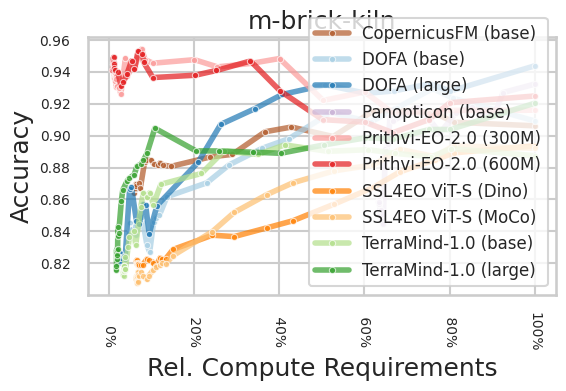

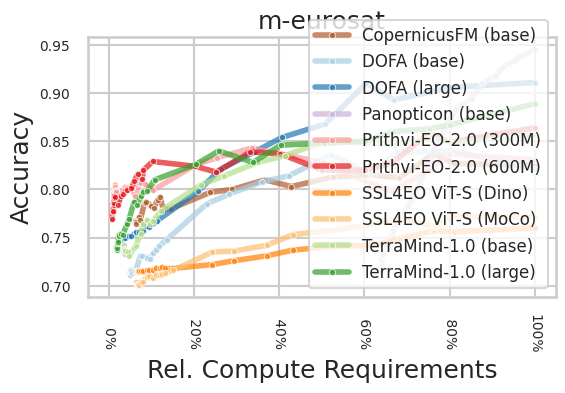

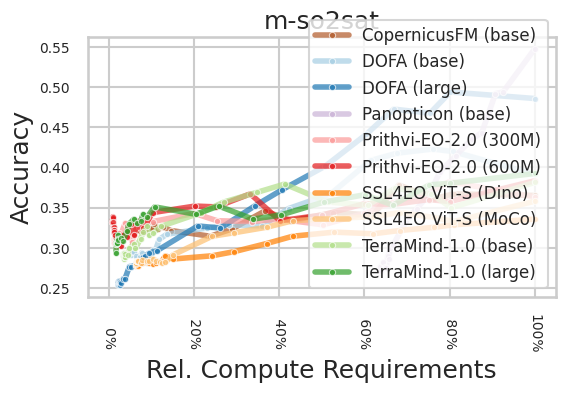

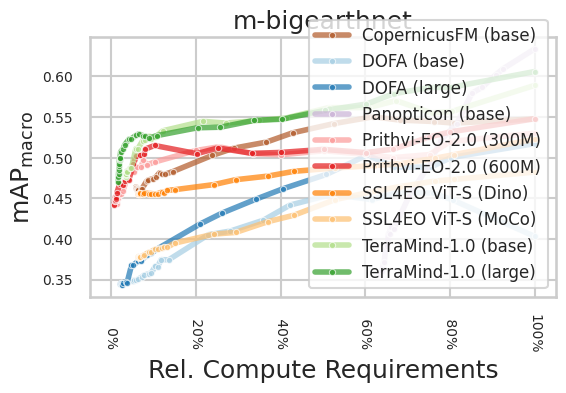

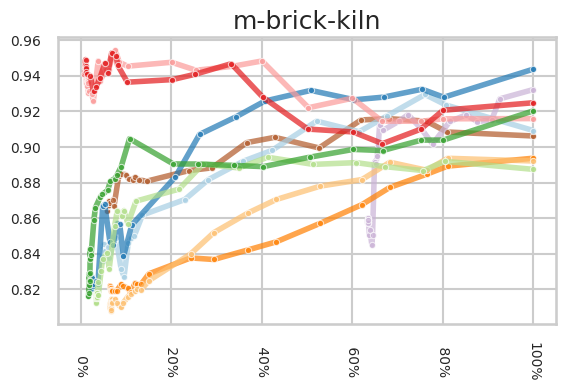

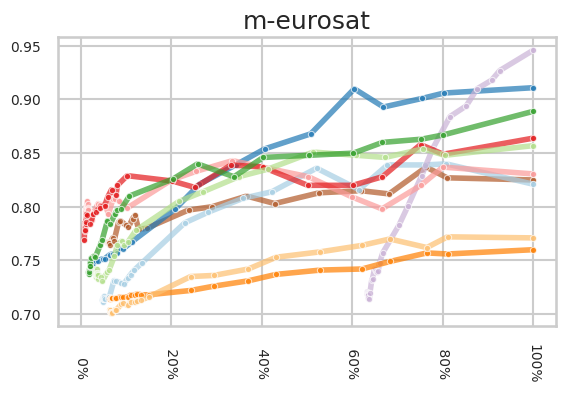

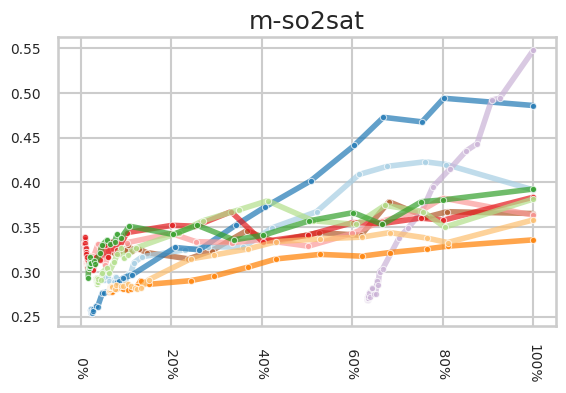

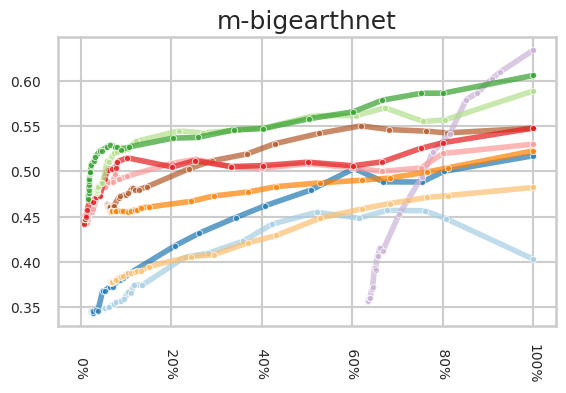

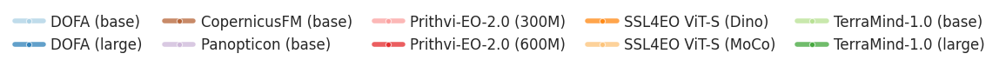

In [82]:
args_list = [(model, dataset, 'knn')
        for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'panopticon', 'copernicusFM'] 
        for dataset in ['m-brick-kiln', 'm-eurosat', 'm-so2sat', 'm-bigearthnet']]
dfs = []
for args in args_list:
    part_df = read_results(*args, avg=True)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
#print(df[['dataset', 'model', 'Exact Rel. Compute Requirement',  'metric', 'Rel. Retention Rate of 100%']].sort_values(by=['dataset', 'model', 'Exact Rel. Compute Requirement']).to_markdown())

for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        df_ds = df[df.dataset == dataset]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_ds,
            x='Exact Rel. Compute Requirement', y='metric',
            marker='.', 
            ax=ax, hue='model',
            palette=model_colors,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting,
        )
    
        #ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        shared_handles, shared_labels = ax.get_legend_handles_labels()
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel(metric_str)
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.legend([],[], frameon=False)
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/post_hoc").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/post_hoc/post_hoc_slimming_existing_fms_average_by_model_{dataset}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(dataset)  # only print title after saving
        plt.show()

shared_handles = shared_handles[1:3]+shared_handles[0:1]+shared_handles[3:]
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_legend_only.pdf', ncol=5)

### Segmentation

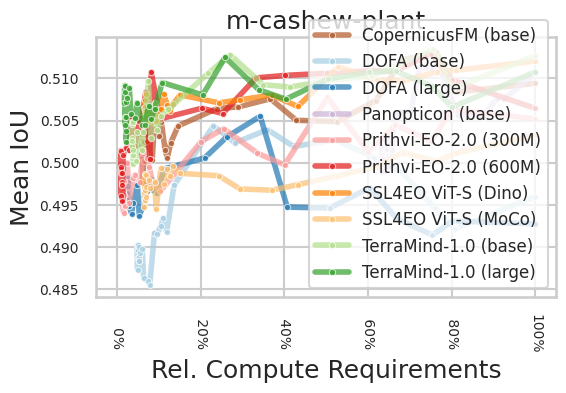

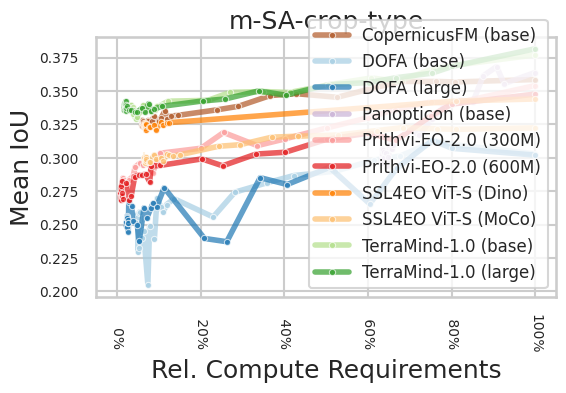

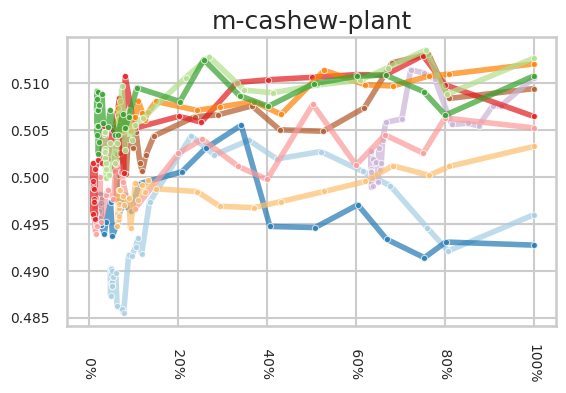

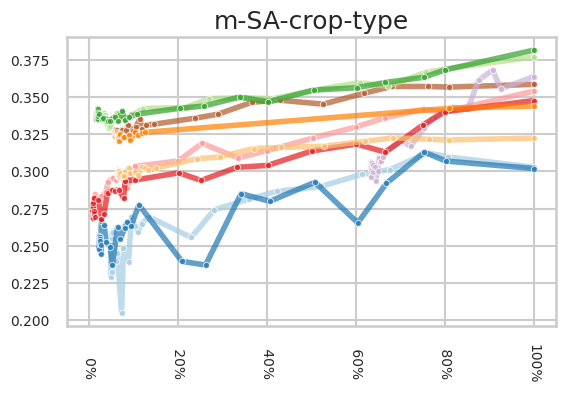

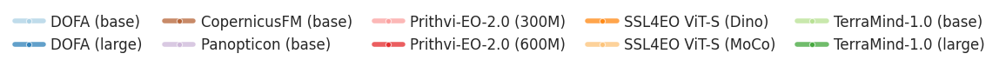

In [86]:
args_list = [(model, dataset, 'segmentation')
        for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'panopticon', 'copernicusFM'] 
        for dataset in ['m-cashew-plant', 'm-SA-crop-type']]
dfs = []
for args in args_list:
    part_df = read_results(*args, fraction_for_flop_rounding=10)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
#print(df[['dataset', 'model', 'Exact Rel. Compute Requirement',  'metric', 'Rel. Retention Rate of 100%', 'scale']].sort_values(by=['dataset', 'model', 'Exact Rel. Compute Requirement']).to_markdown())

for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        df_ds = df[df.dataset == dataset]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_ds,
            x='Exact Rel. Compute Requirement', y='metric',
            marker='.', 
            ax=ax, hue='model',
            palette=model_colors,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting,
        )
    
        #ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        shared_handles, shared_labels = ax.get_legend_handles_labels()
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel(metric_str)
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.legend([],[], frameon=False)
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/post_hoc").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/post_hoc/post_hoc_slimming_existing_fms_average_by_model_{dataset}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(dataset)  # only print title after saving
        plt.show()

shared_handles = shared_handles[1:3]+shared_handles[0:1]+shared_handles[3:]
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_legend_only.pdf', ncol=5)

### Change-Detection

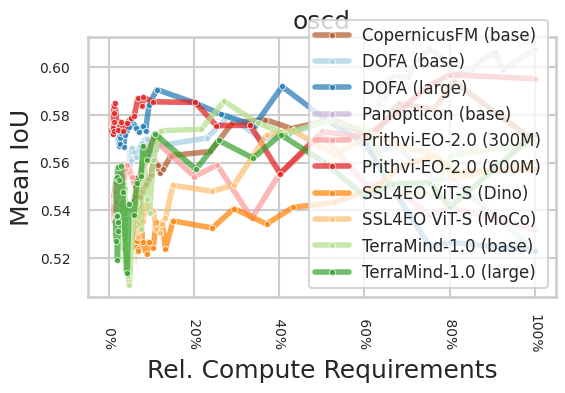

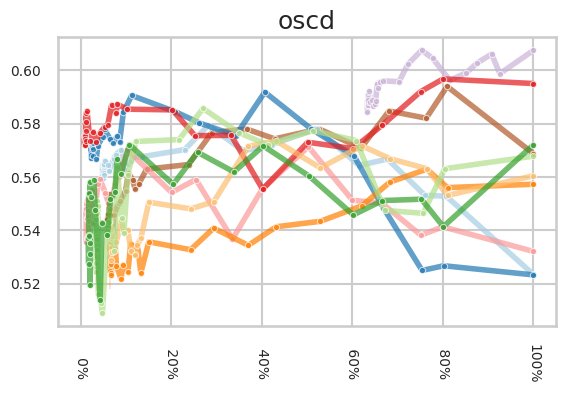

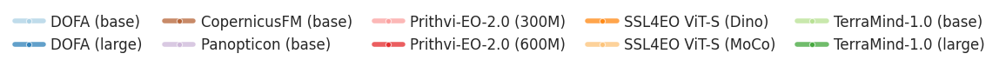

In [5]:
args_list = [(model, dataset, 'change-detection')
        for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'panopticon', 'copernicusFM'] 
        for dataset in ['oscd']]
dfs = []
for args in args_list:
    part_df = read_results(*args, fraction_for_flop_rounding=10)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
#print(df[['dataset', 'model', 'Exact Rel. Compute Requirement', 'metric', 'Rel. Retention Rate of 100%']].sort_values(by=['dataset', 'model', 'Exact Rel. Compute Requirement']).to_markdown())

for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        df_ds = df[df.dataset == dataset]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_ds,
            x='Exact Rel. Compute Requirement', y='metric',
            marker='.', 
            ax=ax, hue='model',
            palette=model_colors,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting,
        )
    
        #ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        shared_handles, shared_labels = ax.get_legend_handles_labels()
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel(metric_str)
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.legend([],[], frameon=False)
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/post_hoc").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/post_hoc/post_hoc_slimming_existing_fms_average_by_model_{dataset}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(dataset)  # only print title after saving
        plt.show()

shared_handles = shared_handles[1:3]+shared_handles[0:1]+shared_handles[3:]
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_legend_only.pdf', ncol=5)

## 4.2 Learned vs Post-Hoc

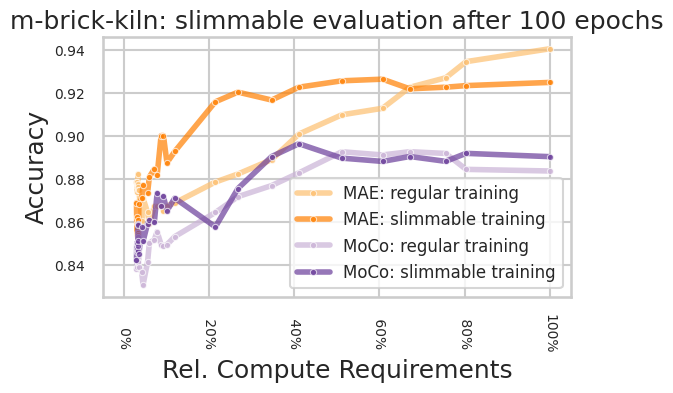

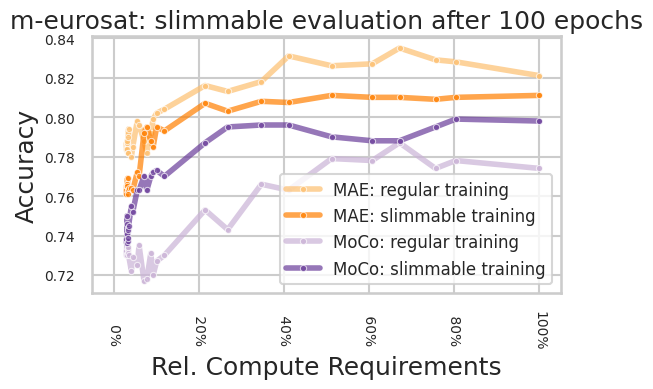

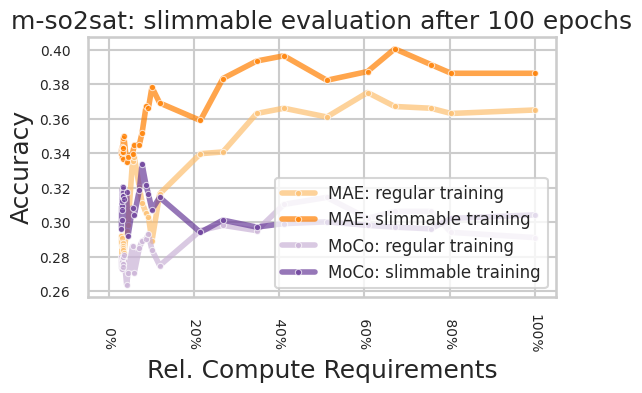

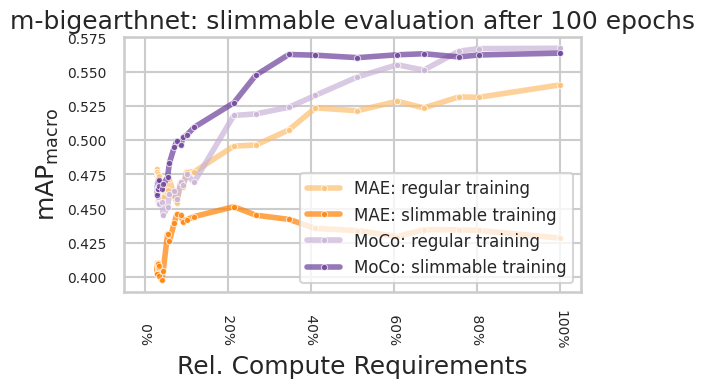

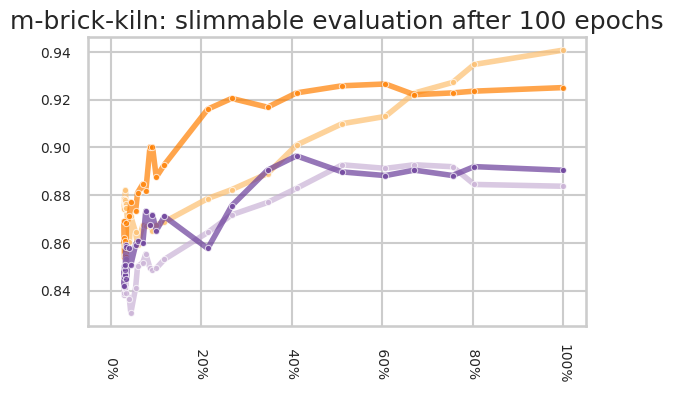

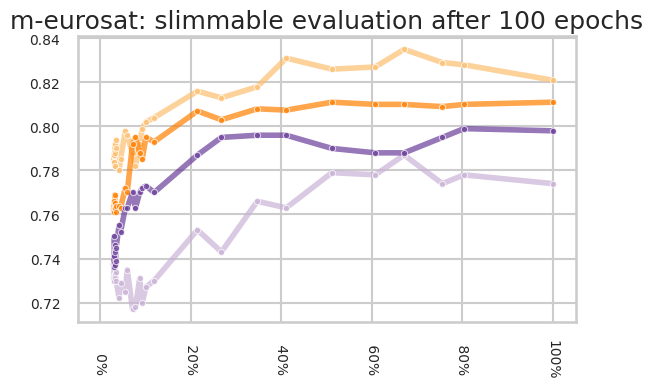

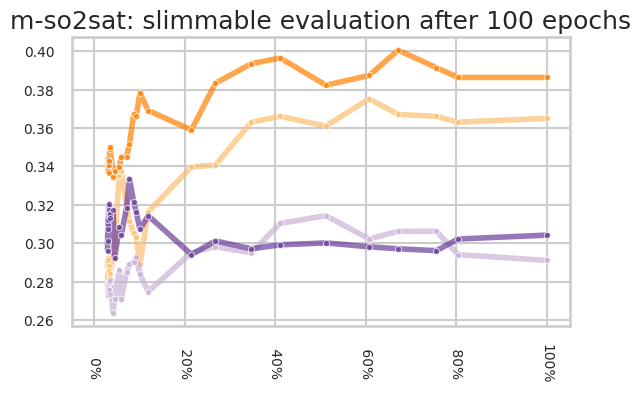

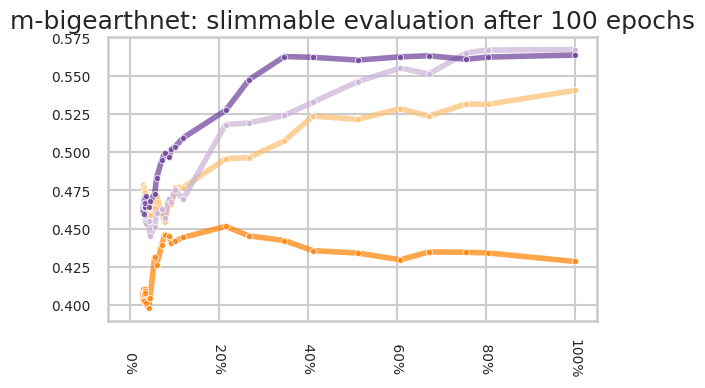

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


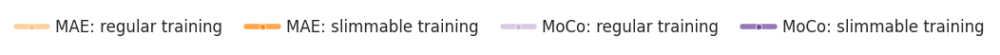

In [92]:
sns.set_palette("Paired")
EPOCH = 100
args_list = [(model, dataset, 'knn')
        for model in [f'MAE ViT base 1.00 epoch{EPOCH-1:03d}', f'MAE ViT base slimable epoch{EPOCH-1:03d}', f'MoCo ViT base 1.00 epoch{EPOCH-1:03d}', f'MoCo ViT base slimable epoch{EPOCH-1:03d}'] 
        #for dataset in ['m-eurosat']]
        for dataset in ['m-brick-kiln', 'm-eurosat', 'm-so2sat', 'm-bigearthnet']]
dfs = []
for args in args_list:
    part_df = read_results(*args, fraction_for_flop_rounding=10, avg=True)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
#print(df[['dataset', 'model', 'Exact Rel. Compute Requirement',  'metric', 'Rel. Retention Rate of 100%', 'scale']].sort_values(by=['dataset', 'model', 'Exact Rel. Compute Requirement']).to_markdown())

palette = sns.color_palette()[6:10]  # C6, C7, C8, C9
for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        df_ds = df[df.dataset == dataset]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_ds,
            x='Exact Rel. Compute Requirement', y='metric',
            marker='.', 
            ax=ax, hue='model',
            palette=palette,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting,
        )
    
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        shared_handles, shared_labels = ax.get_legend_handles_labels()
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel(metric_str)
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.legend([],[], frameon=False)
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/training_slimableOrNot/").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/training_slimableOrNot/native_vs_posthoc_{dataset}{'_nolegend' if not mark_axis_legend else ''}.pdf")
        plt.title(f"{dataset}: slimmable evaluation after {EPOCH} epochs")
        plt.show()

get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'native_vs_posthoc_legend_only.pdf', ncol=4)

## 4.3 EVR, EVR-Slope and Effective Dimension

In [5]:
args_list = [(model, dataset, 'knn')
        for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600', 'ssl4eo_moco', 'ssl4eo_dino', 'panopticon', 'copernicusFM']
        for dataset in ['m-brick-kiln', 'm-eurosat', 'm-so2sat', 'm-bigearthnet']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)

recalculate_evr = False

if recalculate_evr:
    def get_corr(E):
        X = E - E.mean(axis=0, keepdims=True)
        X_norm = X / X.std(axis=0, ddof=1, keepdims=True)
        C = (X_norm.T @ X_norm) / (X_norm.shape[0] - 1)
        off = C[np.triu_indices_from(C, k=1)]
        a = np.abs(off)
        return {"corr_mean": a.mean(), "corr_median": np.median(a)}
    
    #def get_anisotropy(E):
    #    X = E - E.mean(axis=0, keepdims=True)
    #    _, S, _ = np.linalg.svd(X, full_matrices=False)
    #    var = S**2
    #    return {"explained_variance_ratios": var / var.sum(),
    #            "effective_dim": (var.sum()**2) / (var**2).sum()}

    def get_anisotropy(E):
        X = E - E.mean(axis=0, keepdims=True)
        # eigenvalues of X^T X = singular values of X squared
        cov = (X.T @ X)  # don't divide by N-1; it cancels in the ratios
        var = np.linalg.eigvalsh(cov)  # ascending order, real, faster than SVD for D < N
        var = var[::-1]
        var = np.maximum(var, 0)  # numerical safety
        return {"explained_variance_ratios": var / var.sum(),
                "effective_dim": (var.sum()**2) / (var**2).sum()}
    
    collected = defaultdict(list)
    for row in tqdm(df.itertuples(index=False), total=len(df), desc="EVR"):
        fp = f"{FEATURE_BASE}/{ACTIVE_SLIM}/{row.original_model_name}/scale_{row.scale}/features_{row.dataset}_test.npy"
        E  = np.load(fp).astype(np.float32)
        for k, v in {**get_corr(E), **get_anisotropy(E)}.items():
            collected[k].append(v)
    
    for k, v in collected.items():
        df[k] = v
    
    # explode EVR for per-component plots
    df_evr = df.reset_index().rename(columns={"index": "id"}).copy()
    df_evr = df_evr.explode("explained_variance_ratios").reset_index(drop=True)
    df_evr["pos"] = df_evr.groupby("id").cumcount() + 1
    df = df_evr.drop(columns=
        ['accuracy', 'precision', 'recall', 'f1 score', 'metric',
         'flops', 'Exact Rel. Compute Requirement', 
         'Rounded Rel. Compute Requirement', 'mAP', 'accuracy_micro', 'precision_micro', 
         'recall_micro', 'f1 score_micro', 'mAP_micro'
        ])
    df.to_csv(f"{FEATURE_BASE}/{ACTIVE_SLIM}/evr_data.csv")
else:
    df = pd.read_csv(f"{FEATURE_BASE}/{ACTIVE_SLIM}/evr_data.csv")

### EVR curves

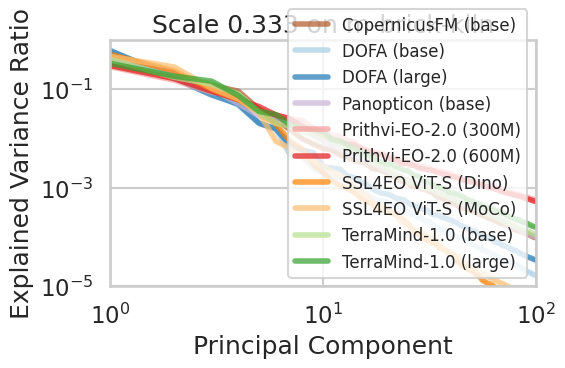

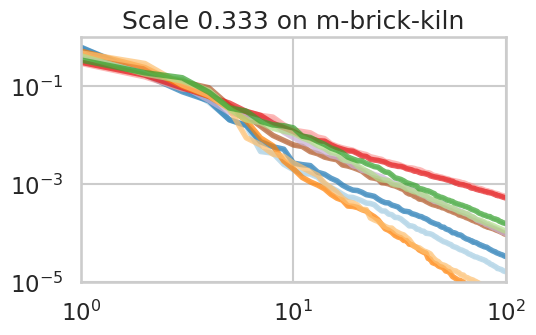

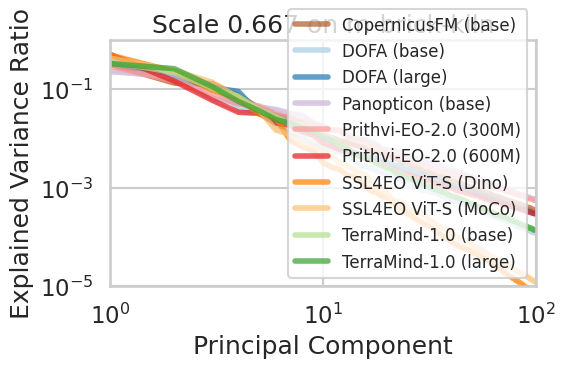

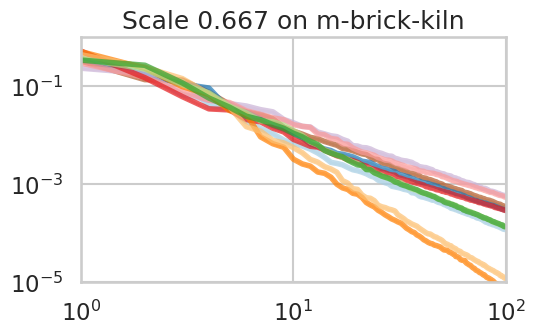

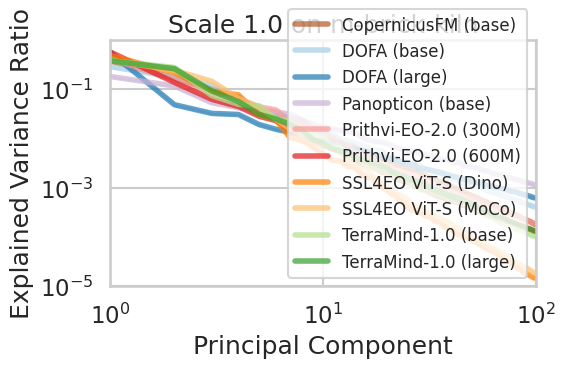

...

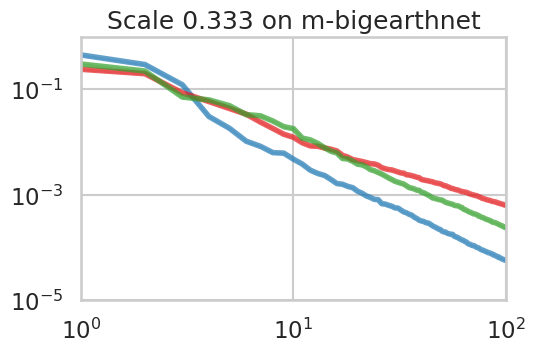

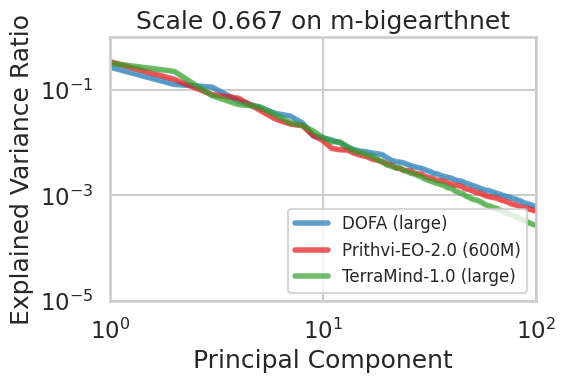

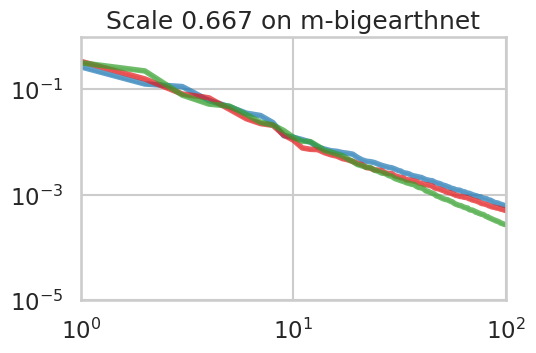

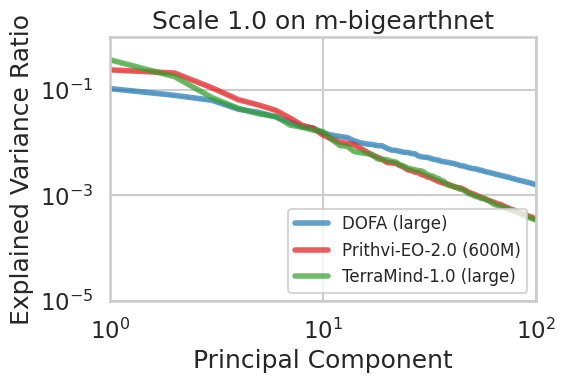

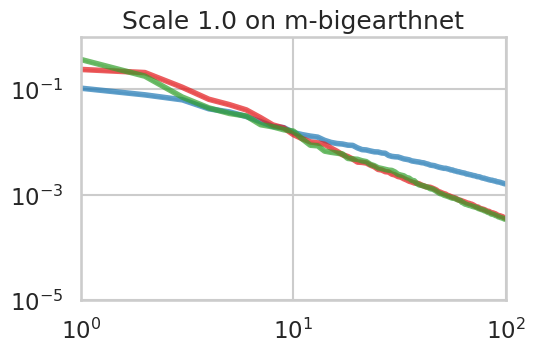

/tmp/ipykernel_4149965/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


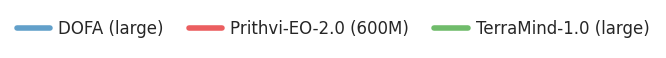

In [6]:
# ── EVR curves ────────────────────────────────────────────────────────────
for all_models in [True, False]:
    palette = model_colors if all_models else PAIRED_COLORS
    for dataset in df.dataset.unique()[:]:
        for scale in [0.333, 0.667, 1.0][:]:
            df_slice = df[(df.pos < 100) & (df.dataset == dataset) & (df.scale == scale)].copy()
            if not all_models:
                df_slice = df_slice[df_slice.model.isin(LARGE_MODELS)]
            
            for mark_labels in [True, False]:
                fig, ax = plt.subplots(figsize=(6, 4))
                sns.lineplot(data=df_slice, x="pos", y="explained_variance_ratios",
                             hue='model', ax=ax, alpha=0.7, linewidth=4,
                             palette=palette, errorbar=errorbar_setting)
                ax.set(xscale='log', yscale='log', ylim=(1e-5, 1), xlim=(1, 100),
                       xlabel='Principal Component', ylabel='Explained Variance Ratio')
                shared_handles, shared_labels = ax.get_legend_handles_labels()
                plt.tight_layout()
                suffix = '_all' if all_models else '_large'
                
                if mark_labels:
                    ax.set_xlabel('Principal Component')
                    ax.set_ylabel('Explained Variance Ratio')
                    ax.legend(loc='lower right', fontsize=legend_fontsize)
                else:
                    ax.set_xlabel('')
                    ax.set_ylabel('')
                    ax.legend([],[], frameon=False)
                Path(f"{FIGURE_BASE}/explain/evr").mkdir(exist_ok=True, parents=True)
                plt.savefig(f"{FIGURE_BASE}/explain/evr/evr_{dataset}_{scale}{suffix}{'' if mark_labels else '_nolegend'}.pdf", bbox_inches='tight')
                plt.title(f"Scale {scale} on {dataset}")
                plt.show()
                
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'evr_legend_only.pdf', ncol=3, width=8)

### EVR Slope

EVR slopes:   0%|          | 0/1240 [00:00<?, ?it/s]

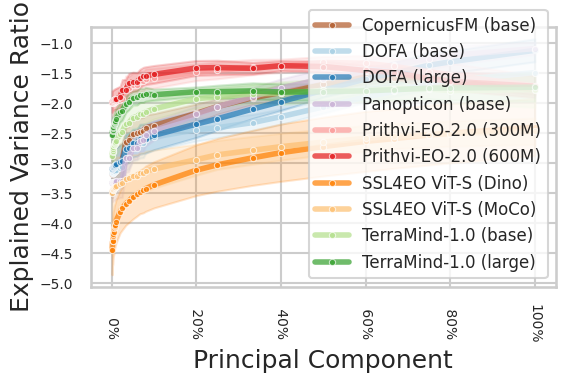

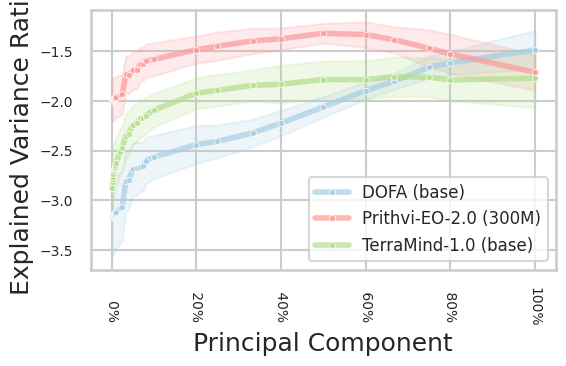

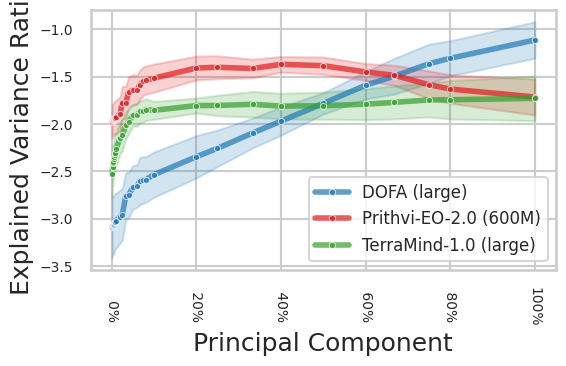

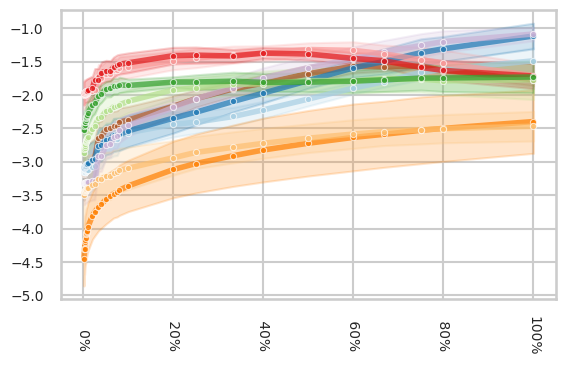

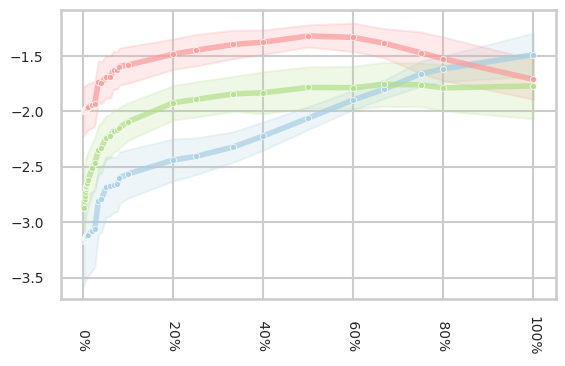

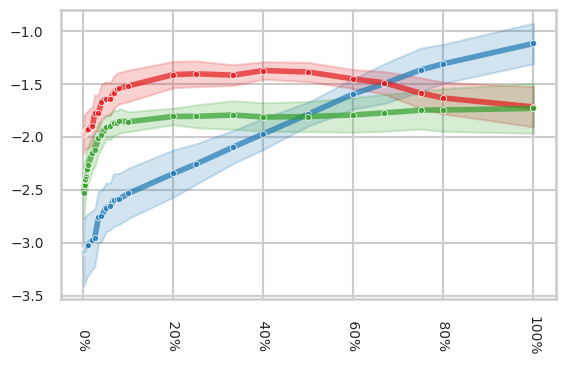

In [7]:
# ── EVR slope ────────────────────────────────────────────────────────────
def loglog_slope(x, y):
    mask = (x > 0) & (y > 0)
    return np.polyfit(np.log10(x[mask]), np.log10(y[mask]), 1)[0]

df_small = df[df.pos < 100].copy()
slope_results = [
    {"model": grp[0], "dataset": grp[1], "scale": grp[2],
     "slope": loglog_slope(g["pos"].to_numpy(), g["explained_variance_ratios"].astype(float).to_numpy())}
    for grp, g in tqdm(df_small.groupby(["model", "dataset", "scale"]), desc="EVR slopes")
]
slopes = pd.DataFrame(slope_results)
slopes['model'] = slopes['model'].apply(model_name_for_plot)

for mark_labels in [True, False]:
    for all_models in ['all', 'small', 'large']:
        data = slopes if all_models=='all' else slopes[~ slopes.model.isin(LARGE_MODELS)]
        data = {'all': slopes, 'small': slopes[slopes.model.isin(SMALL_MODELS)], 'large': slopes[slopes.model.isin(LARGE_MODELS)]}[all_models]
        palette = {'all': model_colors, 'small': PAIRED_COLORS_SMALL, 'large': PAIRED_COLORS}[all_models]
        
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.lineplot(data=data, x='scale', y='slope', marker='.', hue='model',
                     ax=ax, alpha=0.7, linewidth=4, palette=palette, errorbar=errorbar_setting)
        style_flop_axis(ax, mark_labels=mark_labels)
        ax.set_ylabel('Slope of the EVR' if mark_labels else '')
        ax.legend(loc='lower right', fontsize=legend_fontsize)
        plt.tight_layout()
        suffix = ('_nolegend' if not mark_labels else '') + (f'_{all_models}')
        
                
        if mark_labels:
            ax.set_xlabel('Principal Component')
            ax.set_ylabel('Explained Variance Ratio')
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.legend([],[], frameon=False)
        
        Path(f"{FIGURE_BASE}/explain/evr").mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/explain/evr/evr_slope_all_datasets{suffix}.pdf")
        plt.show()
# print(slopes[slopes.dataset.isin(['m-eurosat', 'm-bigearthnet']) & (slopes.model.isin(LARGE_MODELS))].to_markdown())

### Eff. Dim

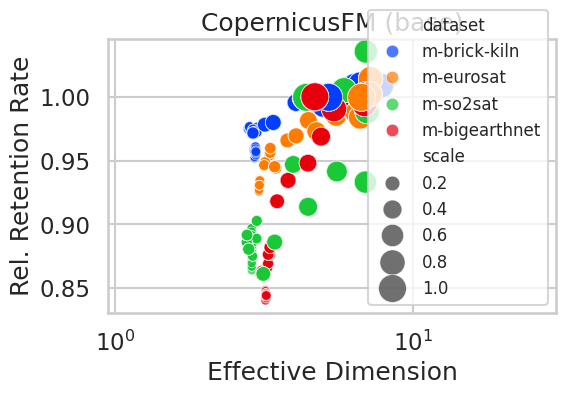

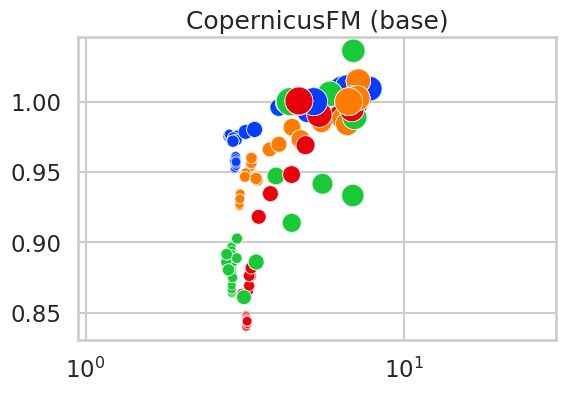

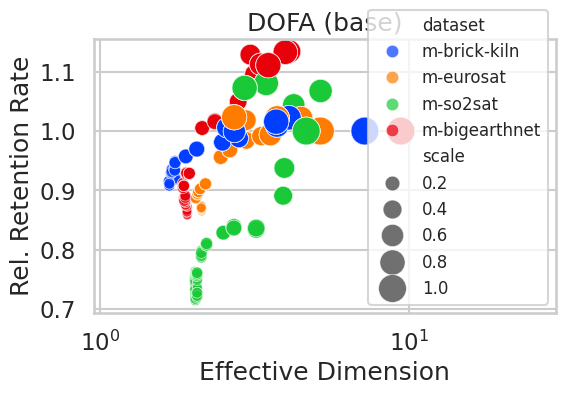

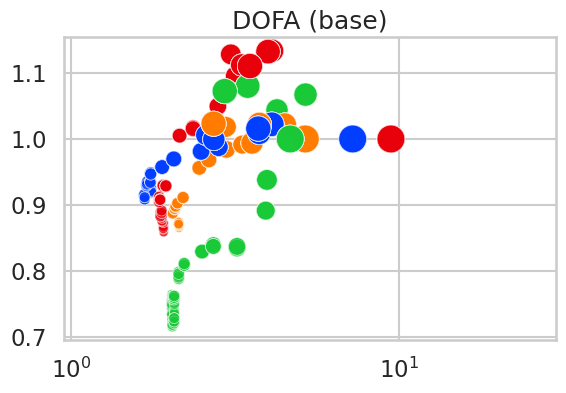

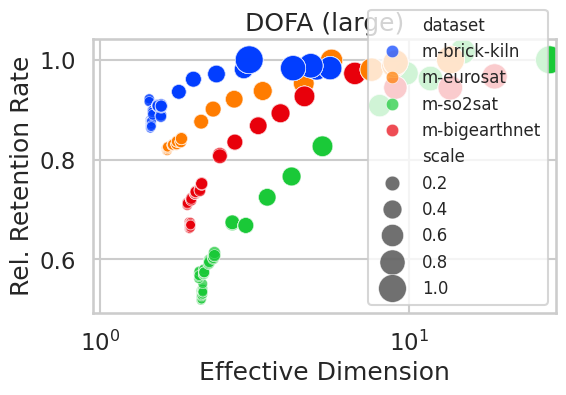

...

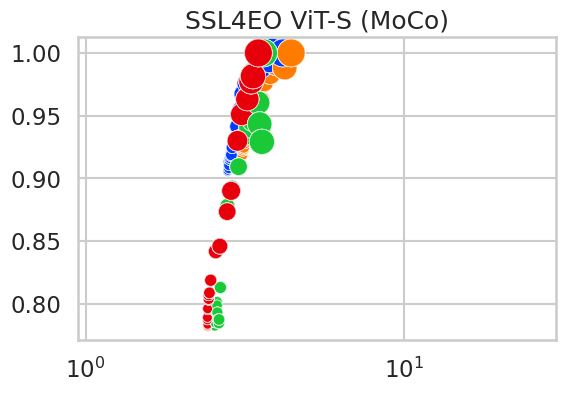

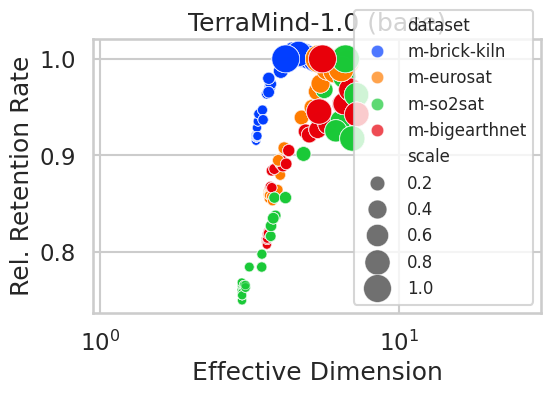

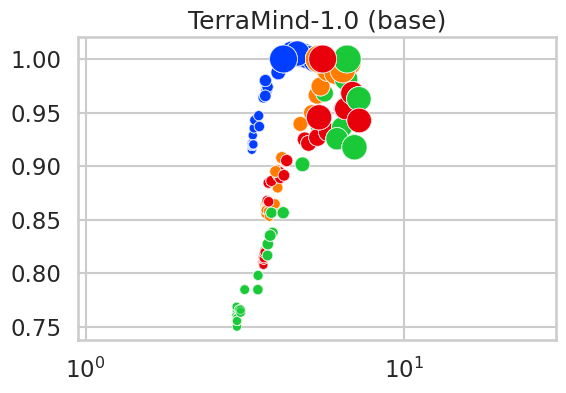

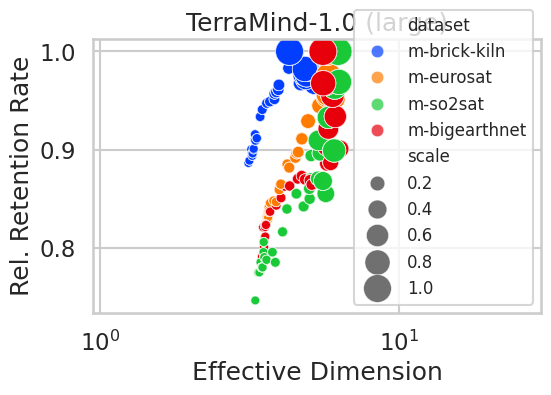

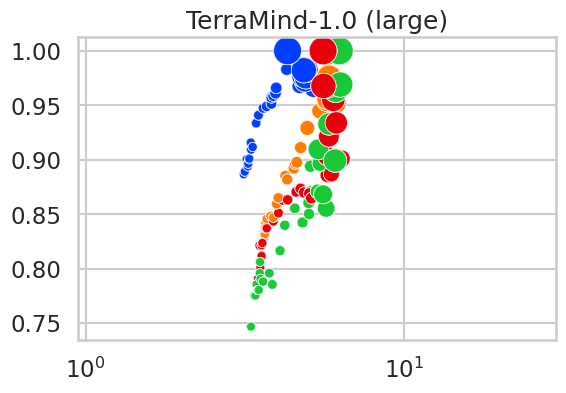

/tmp/ipykernel_4149965/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


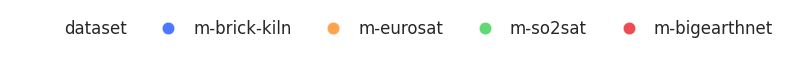

/tmp/ipykernel_4149965/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


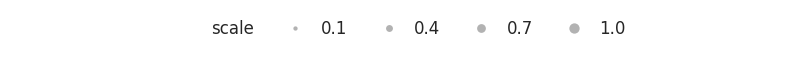

In [8]:
from matplotlib.lines import Line2D
# ── Effective Dimension ───────────────────────────────────────────────────
sns.set_palette("bright")
df_agg = df.sort_values(['model', 'dataset'])
df_agg = df_agg.groupby(['id']).agg({
    col: 'first' if df_agg[col].dtype == 'object' else 'mean' 
    for col in df.columns if col != 'id'
}).drop(columns=['Unnamed: 0'], errors='ignore')

for model in df_agg.model.unique()[:]:
    df_this_model = df_agg[df_agg.model == model]
    original_model_name = df_this_model.original_model_name.unique()[0]
    for mark_labels in [True, False]:
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.scatterplot(
            data=df_this_model,
            x='effective_dim', y='Rel. Retention Rate of 100%',
            hue='dataset', size='scale', ax=ax, alpha=0.7, sizes=(40, 400)
        )
        ax.set(xscale='log', xlim=(0.95, 30))
        #ax.set(xscale='log')
        shared_handles, shared_labels = ax.get_legend_handles_labels()

        if mark_labels:
            ax.set_xlabel('Effective Dimension')
            ax.set_ylabel('Rel. Retention Rate')
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.legend([],[], frameon=False)
        
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/explain/effective_dim/").mkdir(exist_ok=True, parents=True)
        original_model_name = df_this_model.original_model_name.unique()[0]
        plt.savefig(f"{FIGURE_BASE}/explain/effective_dim/eff_dim_{original_model_name}{'_nolegend' if not mark_labels else ''}.pdf")
        plt.title(model)
        plt.show()


get_legends(shared_handles[:5], f"{FIGURE_BASE}/legends", 'eff_dim_ds_legend_only.pdf', ncol=5)
#get_legends(shared_handles[5:], f"{FIGURE_BASE}/legends", 'eff_dim_scale_legend_only.pdf', ncol=len(shared_handles[5:]))
ref_scales = [0.1, 0.4, 0.7, 1.0]  # or np.linspace(s_min, s_max, 4)
s_min, s_max = 0.01, 1.0
size_handles = [
    Line2D([0], [0], marker='o', color='gray', linestyle='', markeredgewidth=0,
           markersize=np.sqrt(5 + 50 * (s - s_min) / (s_max - s_min)),
           label=f'{s:.1f}', alpha=0.6)
    for s in ref_scales
]
size_handles = [shared_handles[5]] + size_handles
get_legends(size_handles, f"{FIGURE_BASE}/legends", 'eff_dim_scale_legend_only.pdf', ncol=len(size_handles))

In [99]:
#print(df[(df.model.isin(['TerraMind-1.0 (base)', 'TerraMind-1.0 (large)']))][['dataset', 'model', 'Rel. Retention Rate of 100%', 'effective_dim', 'scale']].groupby(['dataset', 'model', 'scale']).agg('mean').reset_index().to_markdown())
print(df[['dataset', 'model', 'Rel. Retention Rate of 100%', 'effective_dim', 'scale']].groupby(['dataset', 'model', 'scale']).agg('mean').reset_index().to_markdown())

|      | dataset       | model                 |   scale |   Rel. Retention Rate of 100% |   effective_dim |
|-----:|:--------------|:----------------------|--------:|------------------------------:|----------------:|
|    0 | m-bigearthnet | CopernicusFM (base)   | 0.001   |                      0.84751  |         3.19492 |
|    1 | m-bigearthnet | CopernicusFM (base)   | 0.002   |                      0.845926 |         3.20378 |
|    2 | m-bigearthnet | CopernicusFM (base)   | 0.0025  |                      0.844134 |         3.20104 |
|    3 | m-bigearthnet | CopernicusFM (base)   | 0.00333 |                      0.844707 |         3.19833 |
|    4 | m-bigearthnet | CopernicusFM (base)   | 0.004   |                      0.841441 |         3.2032  |
|    5 | m-bigearthnet | CopernicusFM (base)   | 0.005   |                      0.841935 |         3.20678 |
|    6 | m-bigearthnet | CopernicusFM (base)   | 0.006   |                      0.842607 |         3.20478 |
|    7 | m-bigearth

### Feat. Correlation

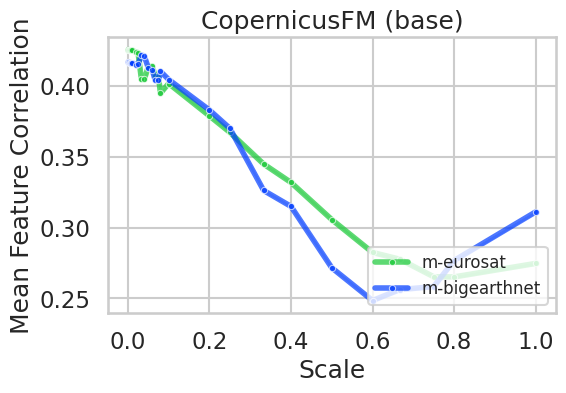

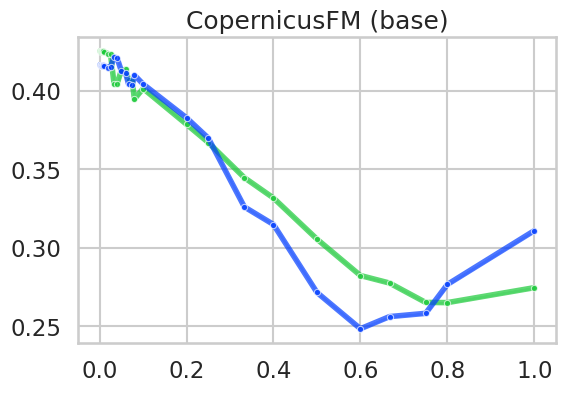

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


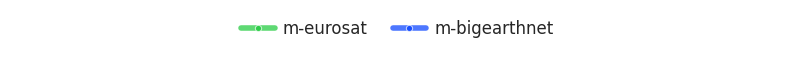

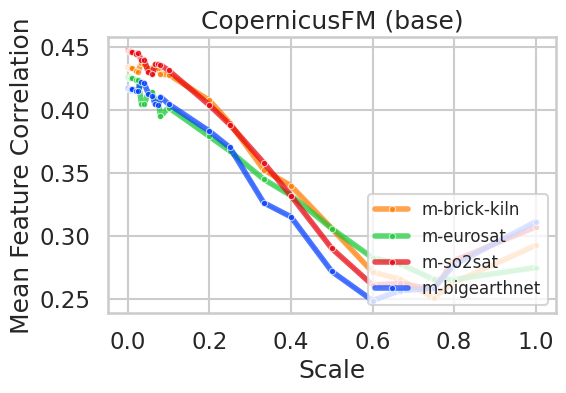

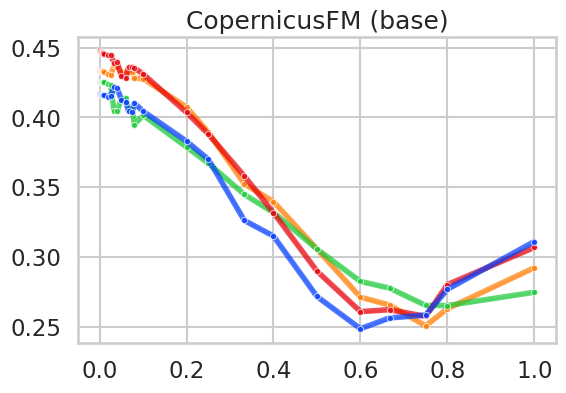

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


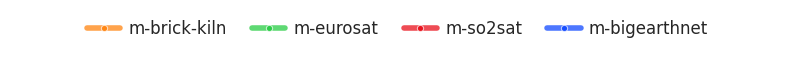

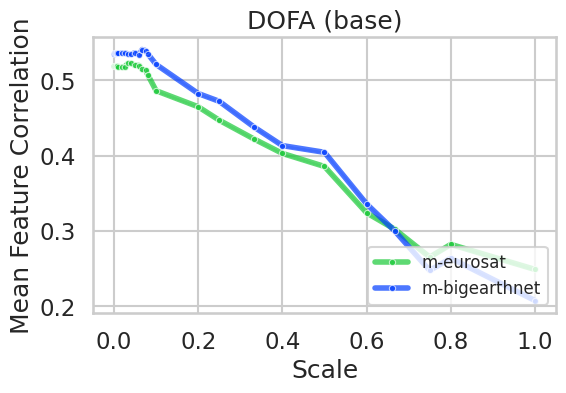

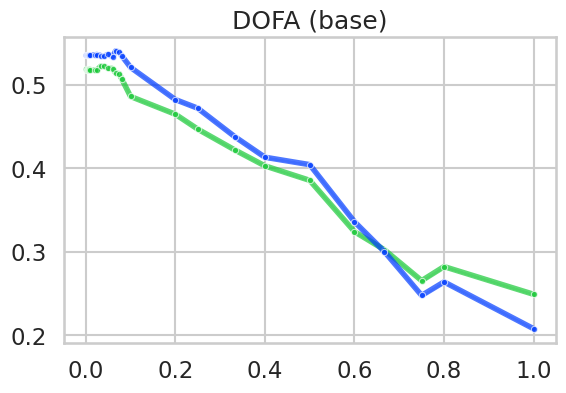

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


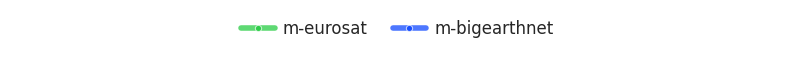

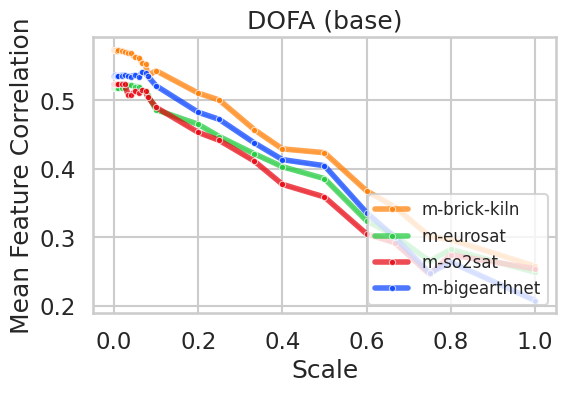

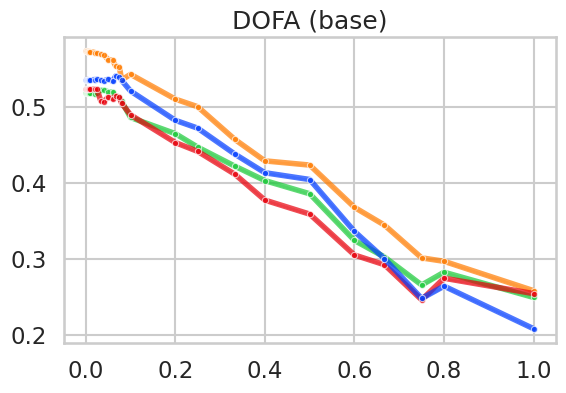

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


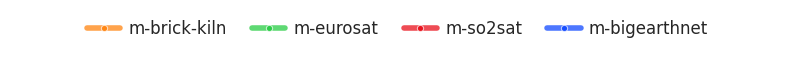

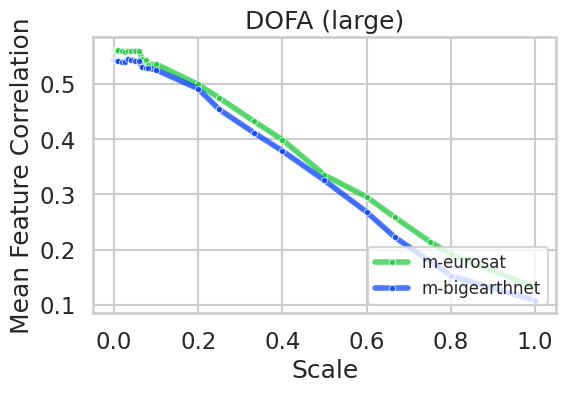

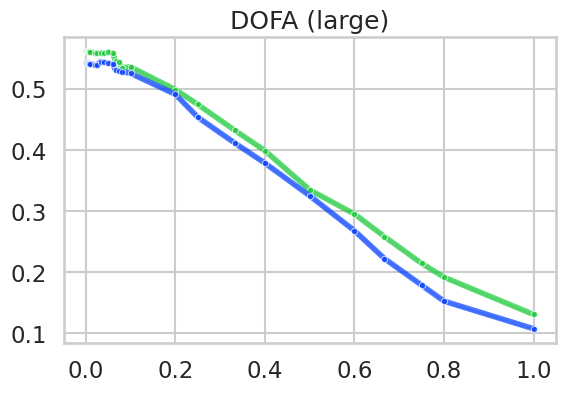

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


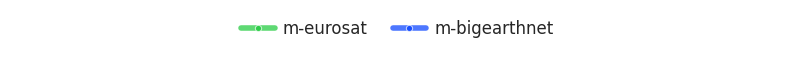

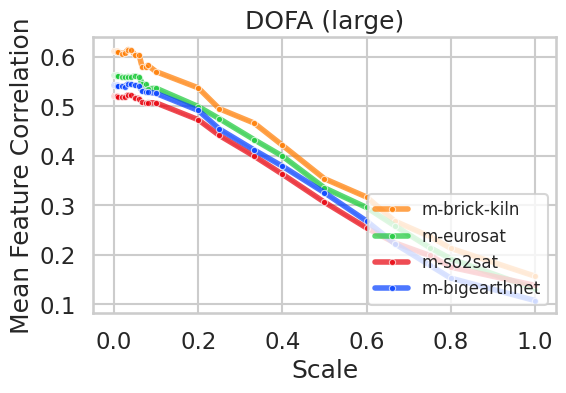

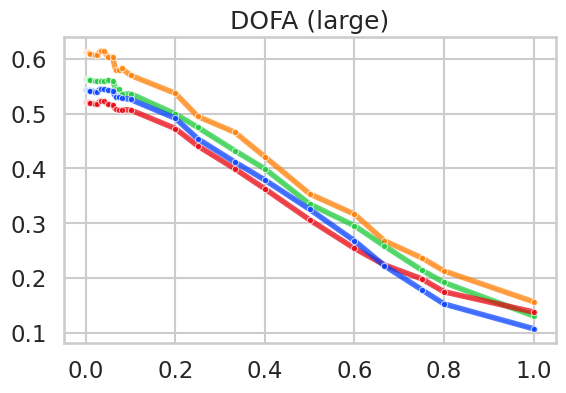

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


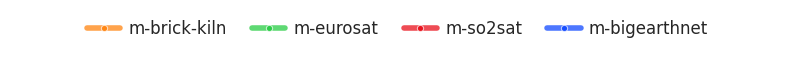

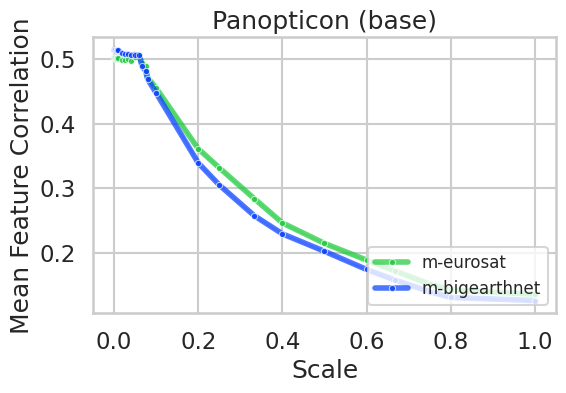

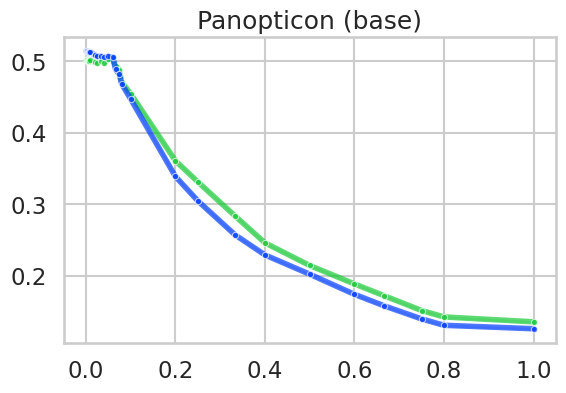

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


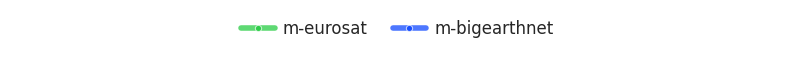

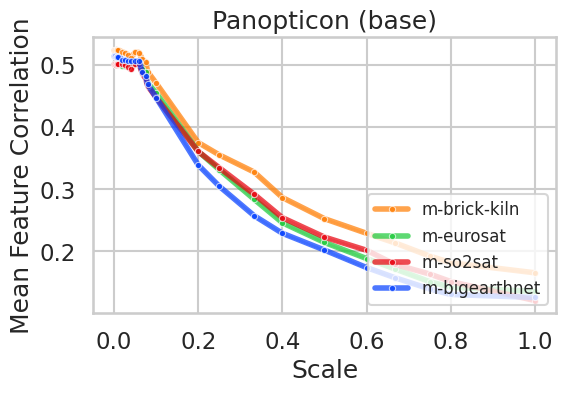

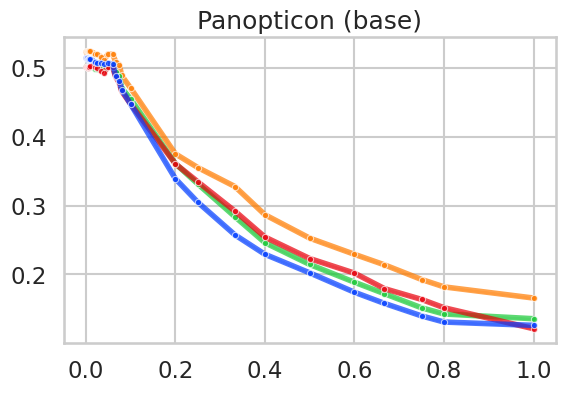

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


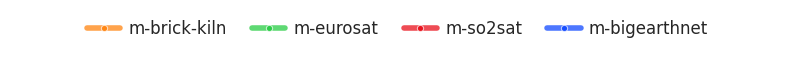

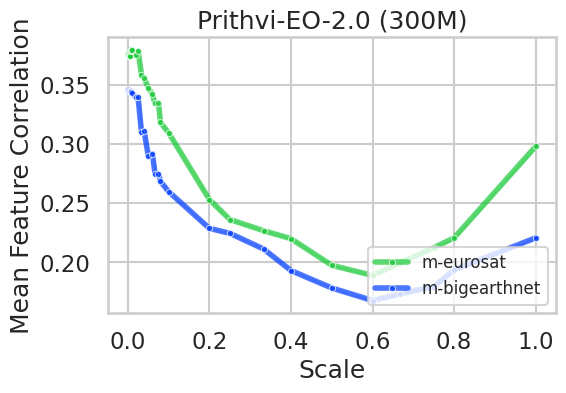

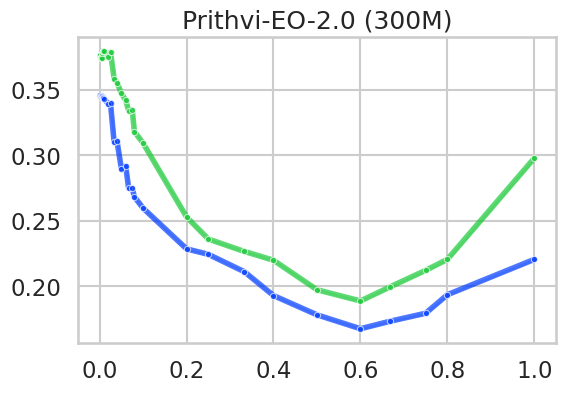

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


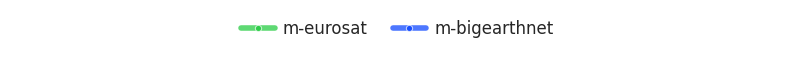

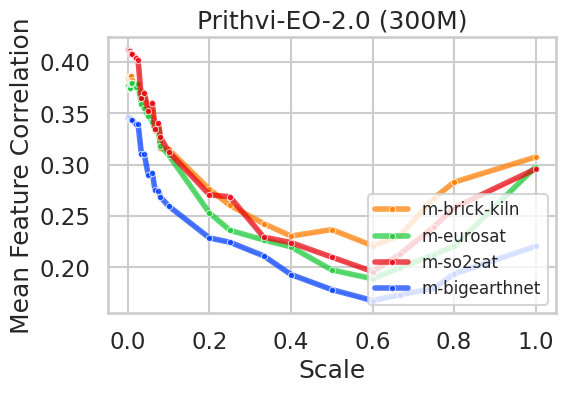

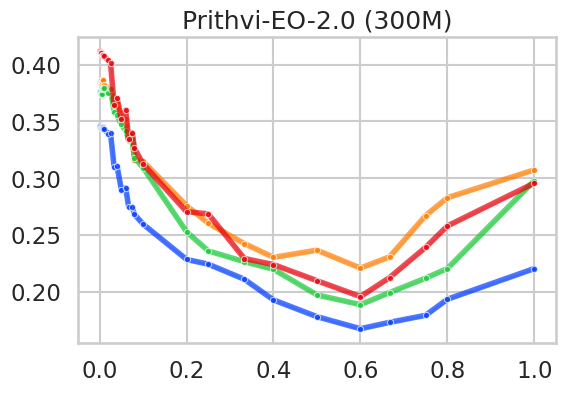

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


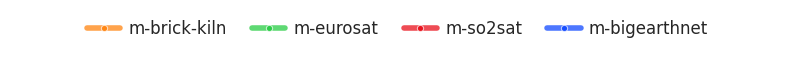

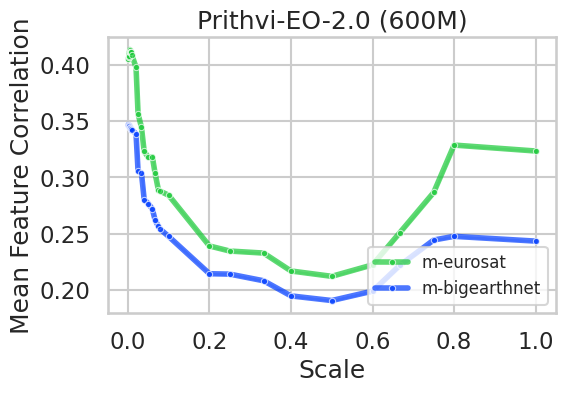

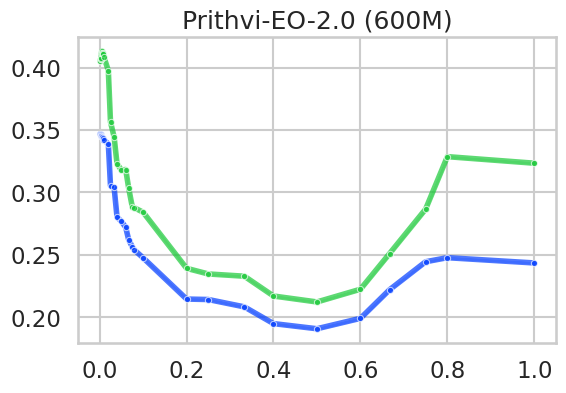

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


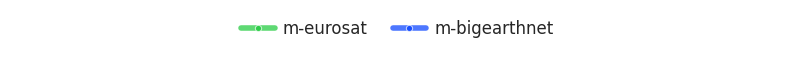

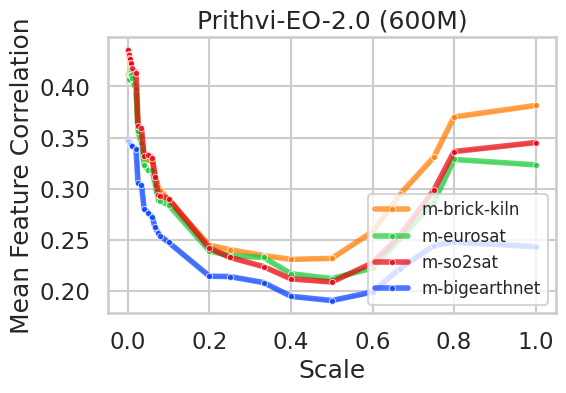

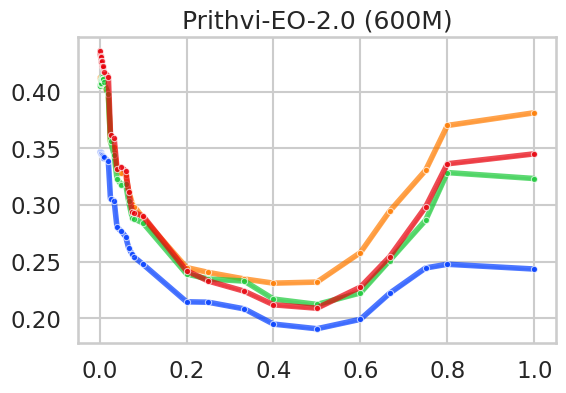

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


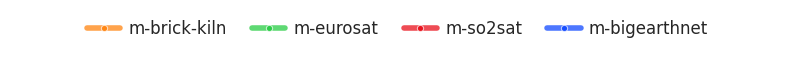

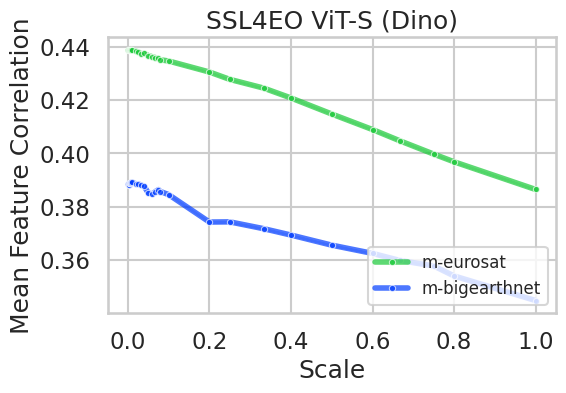

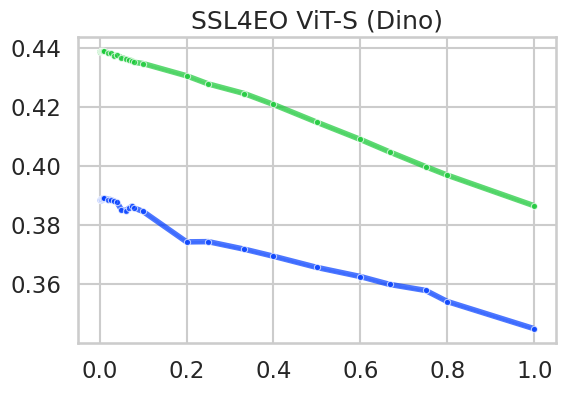

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


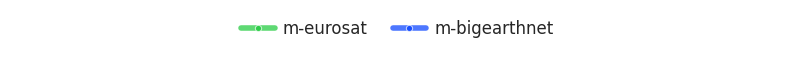

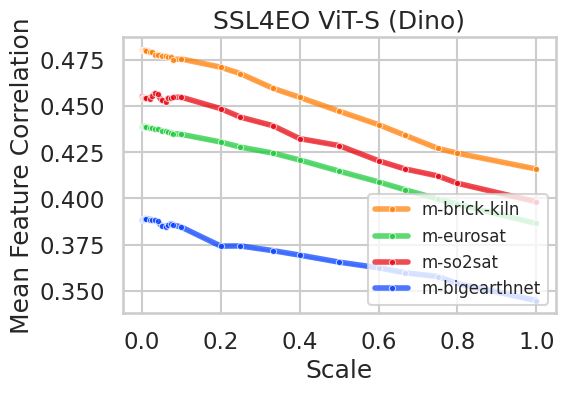

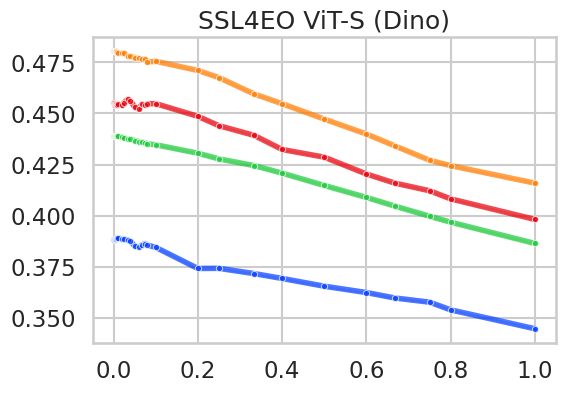

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


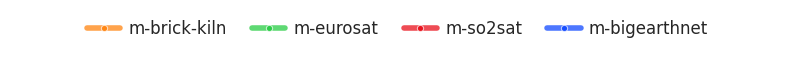

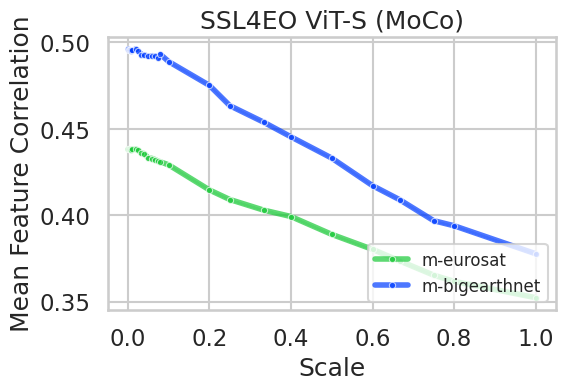

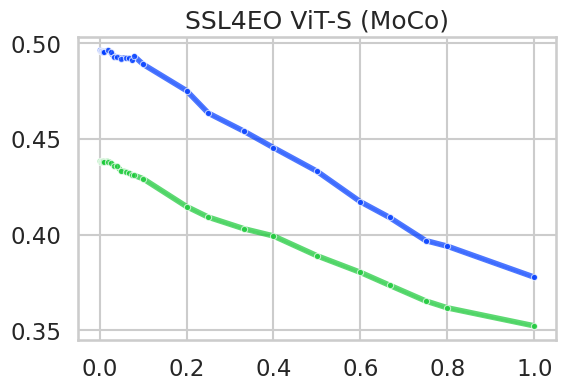

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


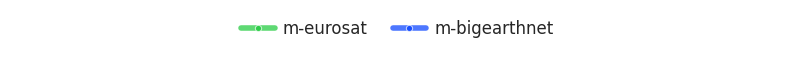

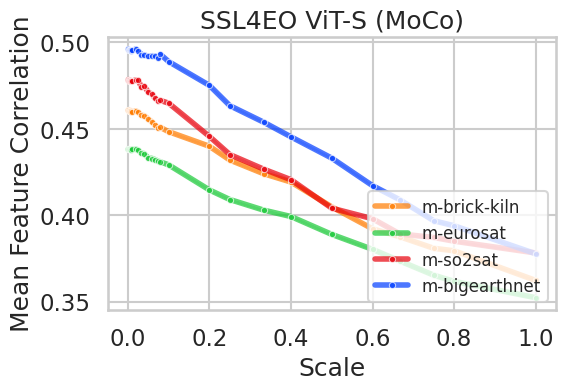

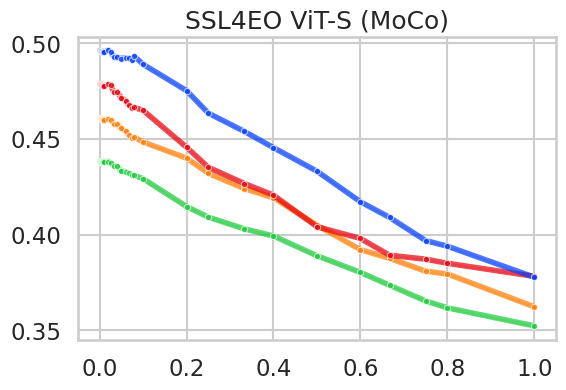

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


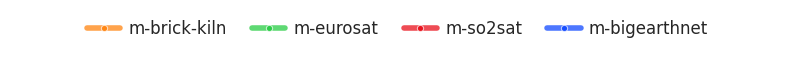

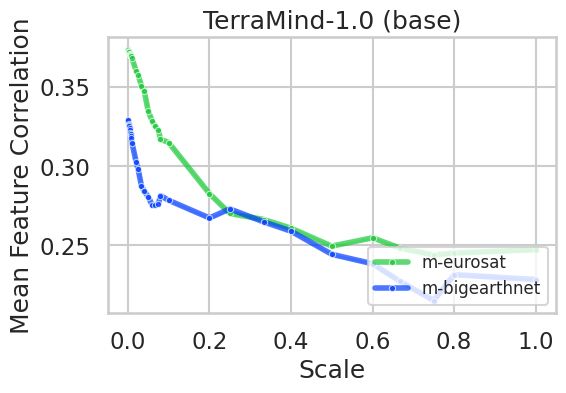

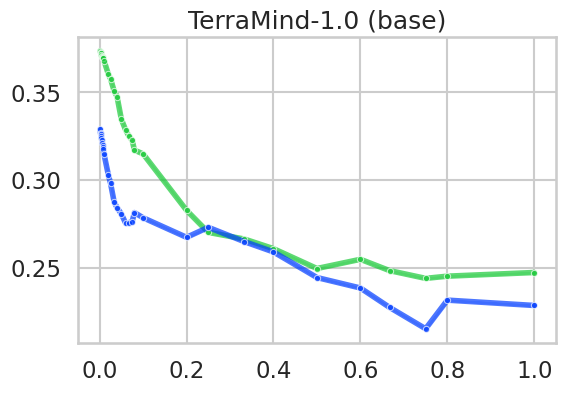

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


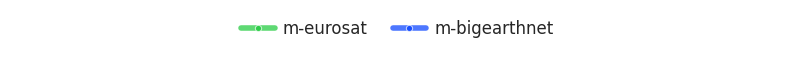

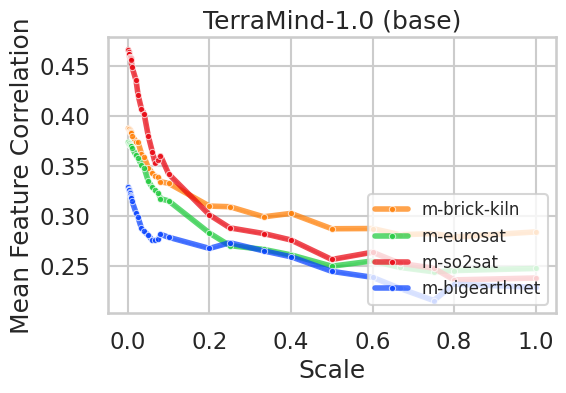

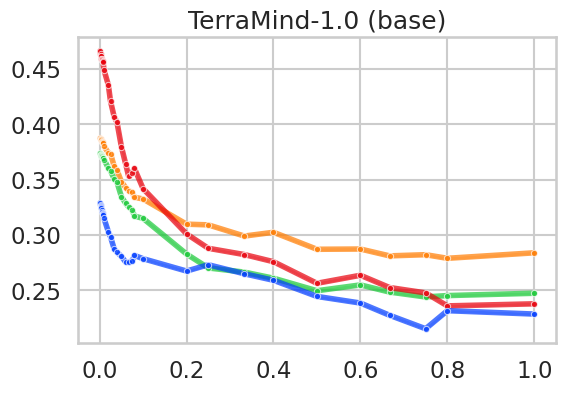

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


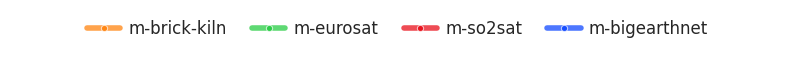

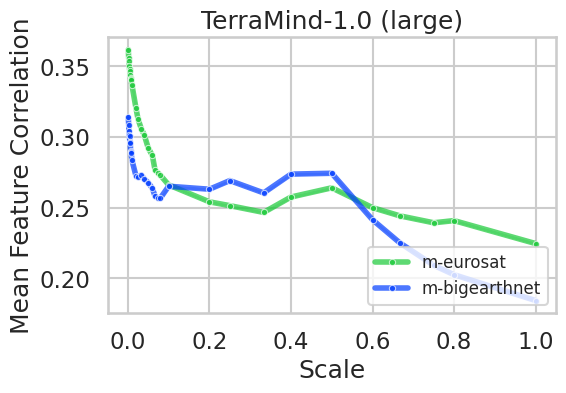

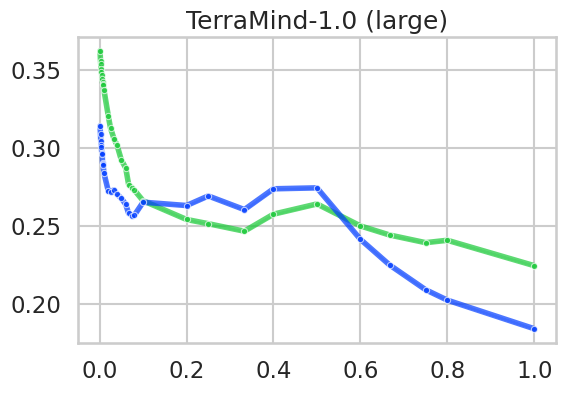

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


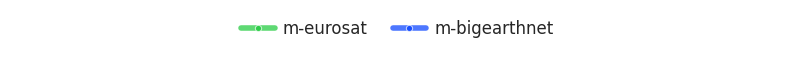

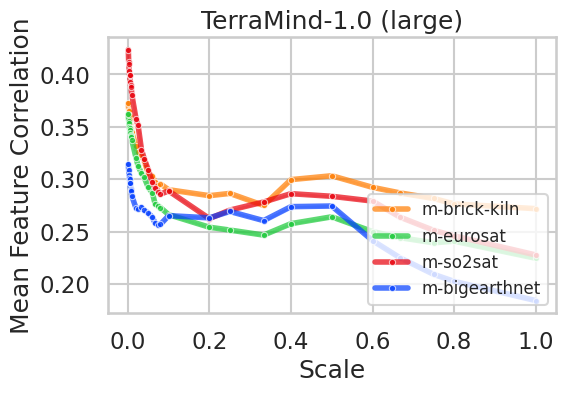

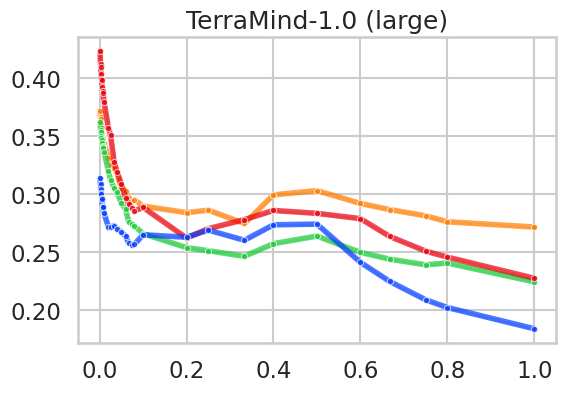

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


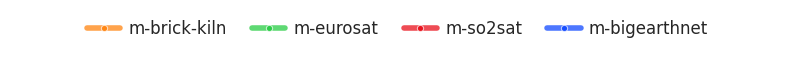

In [102]:
# ── Feature Correlation ───────────────────────────────────────────────────
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
dataset_palette = {
    'm-bigearthnet': prop_cycle[0],
    'm-brick-kiln':  prop_cycle[1],
    'm-eurosat':     prop_cycle[2],
    'm-so2sat':      prop_cycle[3],
}
for model in df.model.unique():
    df_this_model = df[df.model == model]
    original_model_name = df_this_model.original_model_name.unique()[0]
    for ds_combi in [('m-bigearthnet', 'm-eurosat'),
                      ('m-bigearthnet', 'm-brick-kiln', 'm-eurosat', 'm-so2sat')]:
        df_model_ds = df_this_model[df_this_model.dataset.isin(ds_combi)]
        for mark_labels in [True, False]:
            fig, ax = plt.subplots(figsize=(6, 4))
            sns.lineplot(
                data=df_model_ds,
                x='scale', y='corr_mean', marker='.', hue='dataset',
                ax=ax, alpha=0.7, linewidth=4, errorbar=errorbar_setting, palette=dataset_palette
            )            
            shared_handles, shared_labels = ax.get_legend_handles_labels()
            if mark_labels:
                ax.set_xlabel('Scale')
                ax.set_ylabel('Mean Feature Correlation')
                ax.legend(loc='lower right', fontsize=legend_fontsize)
            else:
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.legend([],[], frameon=False)
            plt.tight_layout()
            leg_tag = '_nolegend' if not mark_labels else ''
            Path(f"{FIGURE_BASE}/explain/correlation").mkdir(exist_ok=True, parents=True)
            plt.savefig(f"{FIGURE_BASE}/explain/correlation/corr_{original_model_name}_{'some_ds' if len(ds_combi) < 4 else 'all_ds'}{leg_tag}.pdf")
            plt.title(model)
            plt.show()
        
        get_legends(shared_handles, f"{FIGURE_BASE}/legends", f"corr_{'some_ds' if len(ds_combi) < 4 else 'all_ds'}_legend_only.pdf", ncol=4)
        
#print(df[df.dataset.isin(['m-eurosat', 'm-bigearthnet']) & (df.model.isin(LARGE_MODELS))][['dataset', 'model', 'corr_mean', 'scale']].to_markdown())

# Appendix

In [10]:
model_flops[model_flops.scale == 1.0]

,model,scale,flops_SASF,flops_SF,flops_SA
30,terramind,1.0,1.783625e+10,1.783651e+10,1.783625e+10
61,terramind_large,1.0,6.173234e+10,6.173434e+10,6.173234e+10
92,dofa,1.0,1.747011e+10,1.746988e+10,1.747011e+10
123,dofa_large,1.0,6.047052e+10,6.047239e+10,6.047052e+10
154,prithvi2_600,1.0,1.621803e+11,1.621827e+11,1.621803e+11
185,prithvi2_300,1.0,5.984784e+10,5.984971e+10,5.984784e+10
216,vit_tiny,1.0,1.146718e+09,1.146718e+09,1.146718e+09
247,vit_base,1.0,1.713662e+10,1.713662e+10,1.713662e+10
278,ssl4eo_dino,1.0,4.442644e+09,4.442588e+09,4.442644e+09
309,ssl4eo_moco,1.0,4.442644e+09,4.442588e+09,4.442644e+09


## Slimming by Layertype
SlimAttn vs SlimFFN vs SlimAttn+SlimFFN

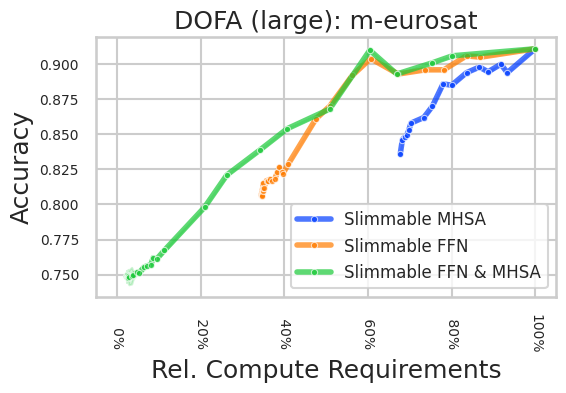

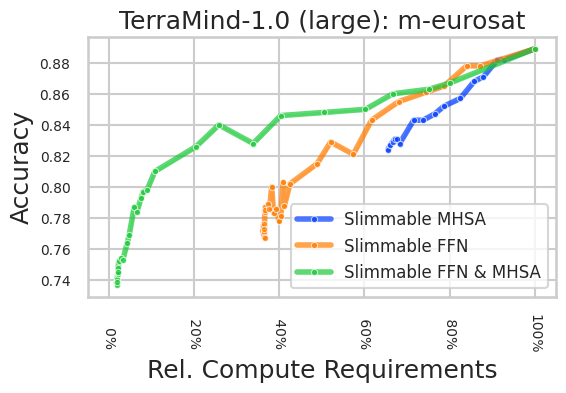

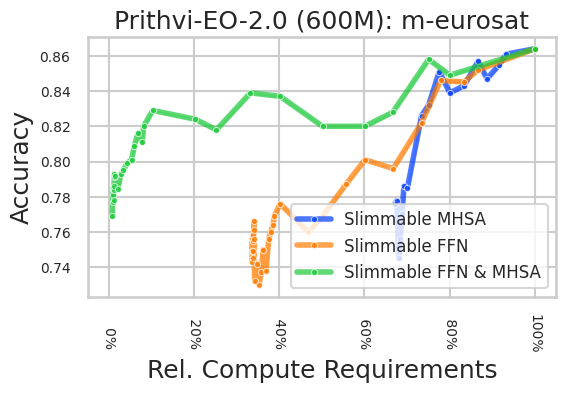

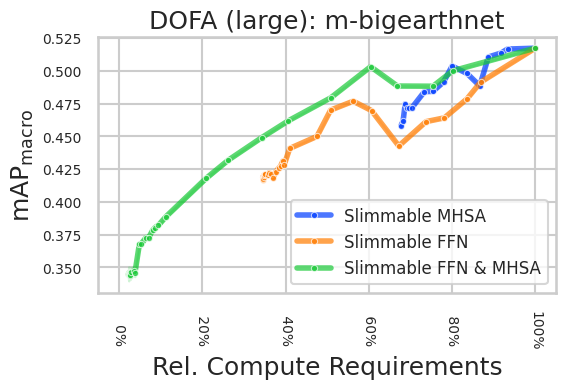

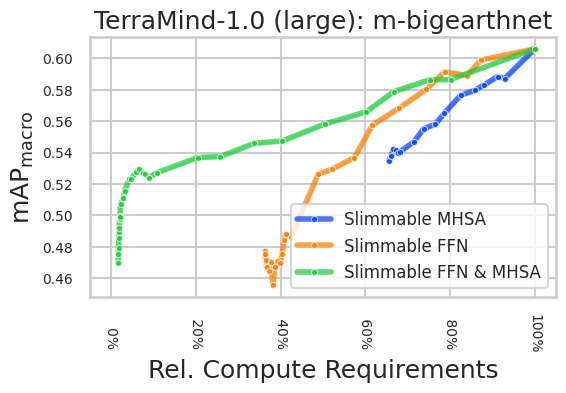

...

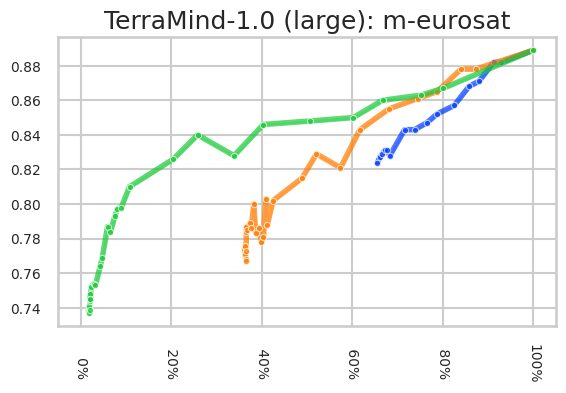

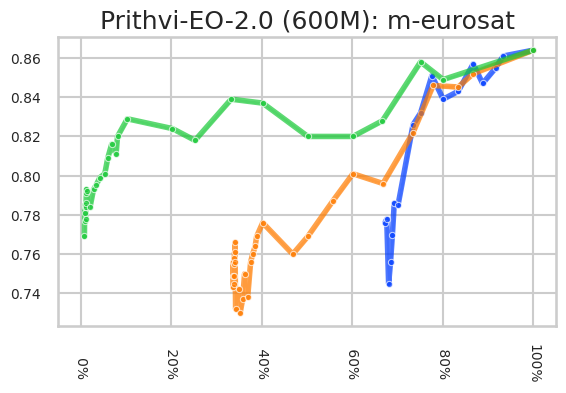

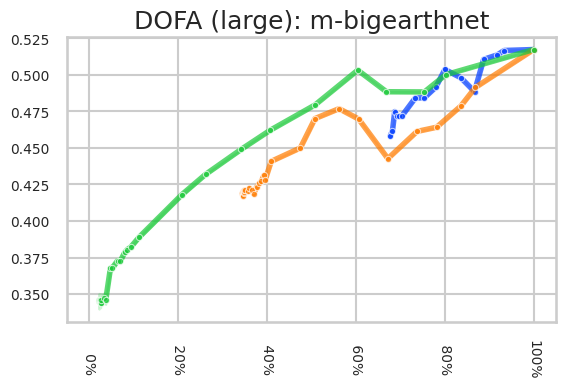

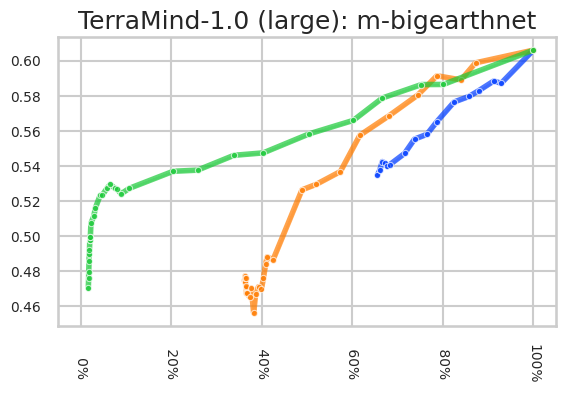

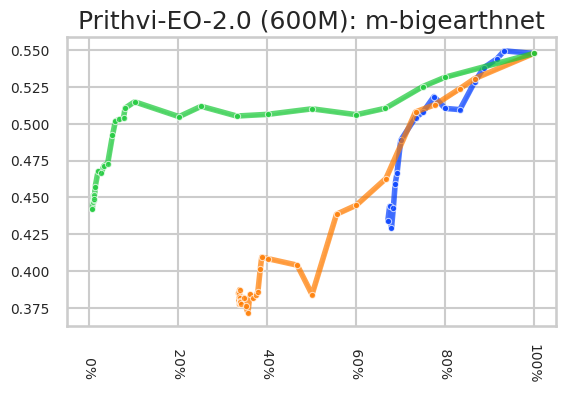

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


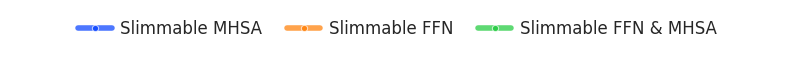

In [105]:
args_list = [(model, dataset, 'knn', slim)
        for model in ['dofa_large', 'terramind_large', 'prithvi2_600'] 
        for dataset in ['m-eurosat', 'm-bigearthnet']
        for slim in ['SlimAttn', 'SlimFFN', 'SlimAttn+SlimFFN']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)
    
df = pd.concat(dfs)
df['slimmable_layers'] = df.slim_style.apply(lambda s: 'Slimmable MHSA' if s == 'SlimAttn' else 'Slimmable FFN' if s == 'SlimFFN' else 'Slimmable FFN & MHSA' if s == 'SlimAttn+SlimFFN' else 'ERROR')

for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        for model in df.model.unique():
            df_ds_mod = df[(df.dataset == dataset) & (df.model == model)]
            original_model_name = df_ds_mod.original_model_name.unique()[0]
            fig, ax = plt.subplots(figsize=(6, 4))
            metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
        
            sns.lineplot(
                data=df_ds_mod,
                x='Exact Rel. Compute Requirement', y='metric',
                marker='.', 
                ax=ax, hue='slimmable_layers',
                palette='bright',
                alpha=0.7,
                linewidth=4, errorbar=errorbar_setting
            )
        
            #ax.set_xscale('log')
            ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
            ax.xaxis.minorticks_off()
            shared_handles, shared_labels = ax.get_legend_handles_labels()
            if mark_axis_legend:
                ax.set_xlabel('Rel. Compute Requirements')
                ax.set_ylabel(metric_str)
                ax.legend(loc='lower right', fontsize=legend_fontsize)
            else:
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.legend([],[], frameon=False)
            ax.tick_params(axis='both', which='both', labelsize=10)
            ax.tick_params(axis='x', which='both', labelrotation=-90)
            ax.set_xlim(left=-0.05, right=1.05)
            plt.tight_layout()
            Path(f"{FIGURE_BASE}/by_layertype").resolve().mkdir(exist_ok=True, parents=True)
            plt.savefig(f"{FIGURE_BASE}/by_layertype/slimmability_by_layer_type_{original_model_name}_{dataset}{'' if mark_axis_legend else '_nolegend'}.pdf")
            plt.title(f"{model}: {dataset}")  # only print title after saving
            plt.show()
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'slimmability_by_layer_type_legend_only.pdf', ncol=4)        

## Implicit Ordering

terramind
|    |   scale | order   |    mean |          std |   min |   max |   max_diff |
|---:|--------:|:--------|--------:|-------------:|------:|------:|-----------:|
|  0 | 0.001   | first   | 0.735   | nan          | 0.735 | 0.735 |  0         |
|  3 | 0.002   | first   | 0.736   | nan          | 0.736 | 0.736 |  0         |
|  6 | 0.0025  | first   | 0.74    | nan          | 0.74  | 0.74  |  0         |
|  9 | 0.00333 | first   | 0.737   | nan          | 0.737 | 0.737 |  0         |
| 12 | 0.004   | first   | 0.742   | nan          | 0.742 | 0.742 |  0         |
| 15 | 0.005   | first   | 0.738   | nan          | 0.738 | 0.738 |  0         |
| 18 | 0.006   | first   | 0.738   | nan          | 0.738 | 0.738 |  0         |
| 21 | 0.00667 | first   | 0.737   | nan          | 0.737 | 0.737 |  0         |
| 24 | 0.0075  | first   | 0.736   | nan          | 0.736 | 0.736 |  0         |
| 27 | 0.008   | first   | 0.733   | nan          | 0.733 | 0.733 |  0         |
| 30 | 0.01    | f

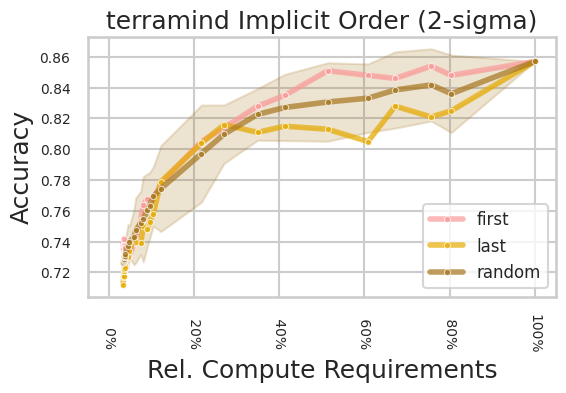

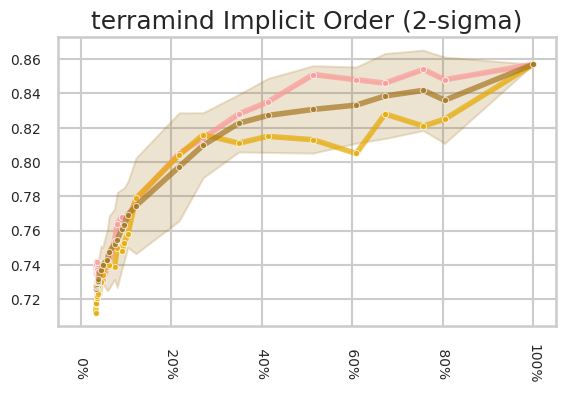

dofa
|    |   scale | order   |    mean |          std |    min |    max |   max_diff |
|---:|--------:|:--------|--------:|-------------:|-------:|-------:|-----------:|
|  0 | 0.001   | first   | 0.7136  | nan          | 0.7136 | 0.7136 |  0         |
|  3 | 0.002   | first   | 0.7128  | nan          | 0.7128 | 0.7128 |  0         |
|  6 | 0.0025  | first   | 0.7118  | nan          | 0.7118 | 0.7118 |  0         |
|  9 | 0.00333 | first   | 0.715   | nan          | 0.715  | 0.715  |  0         |
| 12 | 0.004   | first   | 0.7142  | nan          | 0.7142 | 0.7142 |  0         |
| 15 | 0.005   | first   | 0.7148  | nan          | 0.7148 | 0.7148 |  0         |
| 18 | 0.006   | first   | 0.716   | nan          | 0.716  | 0.716  |  0         |
| 21 | 0.00667 | first   | 0.7148  | nan          | 0.7148 | 0.7148 |  0         |
| 24 | 0.0075  | first   | 0.7168  | nan          | 0.7168 | 0.7168 |  0         |
| 27 | 0.008   | first   | 0.7154  | nan          | 0.7154 | 0.7154 |  0         |

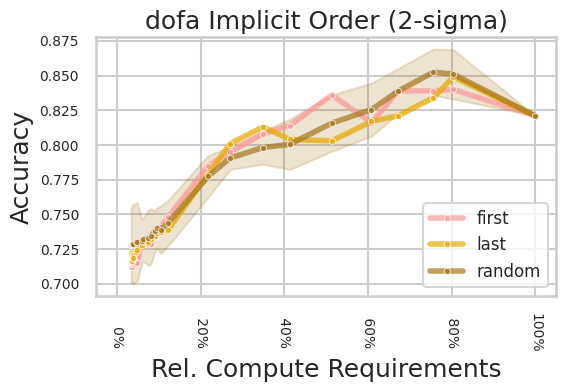

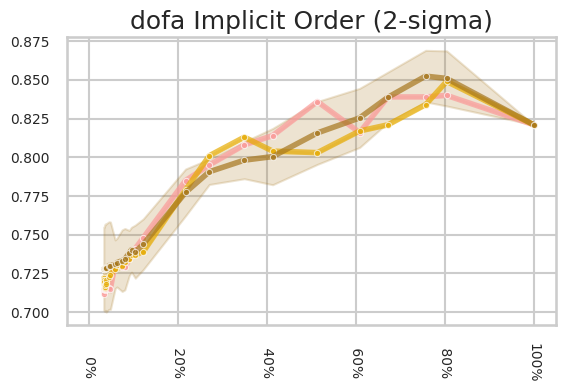

prithvi2_300
|    |   scale | order   |    mean |          std |    min |    max |   max_diff |
|---:|--------:|:--------|--------:|-------------:|-------:|-------:|-----------:|
|  0 | 0.001   | first   | 0.792   | nan          | 0.792  | 0.792  |  0         |
|  3 | 0.002   | first   | 0.799   | nan          | 0.799  | 0.799  |  0         |
|  6 | 0.0025  | first   | 0.801   | nan          | 0.801  | 0.801  |  0         |
|  9 | 0.00333 | first   | 0.798   | nan          | 0.798  | 0.798  |  0         |
| 12 | 0.004   | first   | 0.802   | nan          | 0.802  | 0.802  |  0         |
| 15 | 0.005   | first   | 0.805   | nan          | 0.805  | 0.805  |  0         |
| 18 | 0.006   | first   | 0.8024  | nan          | 0.8024 | 0.8024 |  0         |
| 21 | 0.00667 | first   | 0.7996  | nan          | 0.7996 | 0.7996 |  0         |
| 24 | 0.0075  | first   | 0.798   | nan          | 0.798  | 0.798  |  0         |
| 27 | 0.008   | first   | 0.797   | nan          | 0.797  | 0.797  |  0  

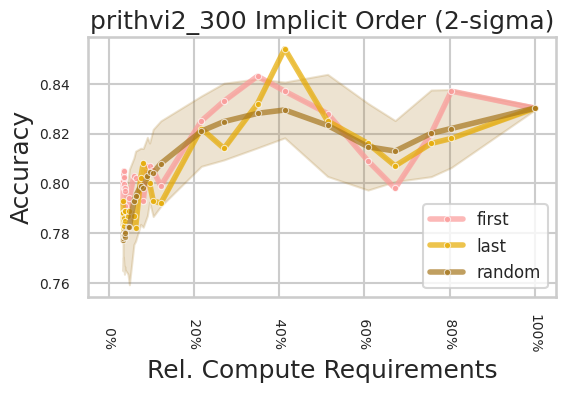

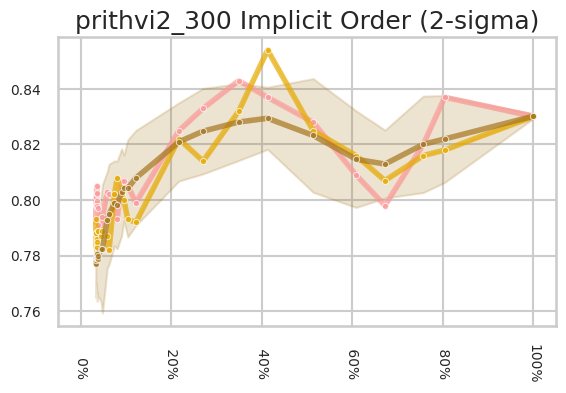

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


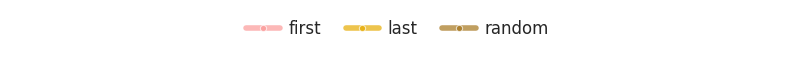

In [104]:
models = ['terramind', 'dofa', 'prithvi2_300']

for model_name in models:
    args_list = [(f'SlimAttn+SlimFFN/implicit_order/{model}', dataset, 'knn')
            for model in [f'{model_name}_first', f'{model_name}_last'] 
            for dataset in ['m-eurosat']]
    args_list += [(f'SlimAttn+SlimFFN/implicit_order/{model_name}_random:seed{seed}', dataset, 'knn') 
            for seed in range(20) 
            for dataset in ['m-eurosat']]
    dfs = []
    for args in args_list:
        part_df = read_results(*args)
        dfs.append(part_df)
        
    df = pd.concat(dfs)
    df['order'] = df.original_model_name.apply(lambda omn: 'first' if 'first' in omn else 'last' if 'last' in omn else 'random')
    
    df2 = df.groupby(['scale', 'original_model_name']).agg({
        col: 'first' if df[col].dtype == 'object' else 'mean' 
        for col in df.columns if col not in ['original_model_name']
    }).reset_index(drop=True).sort_values(by=['order', 'scale'])[['Exact Rel. Compute Requirement', 'metric', 'order', 'scale']]
    # print(df2.to_markdown())
    
    stats = df2.groupby(['scale', 'order'])['metric'].agg(['mean', 'std', 'min', 'max', ('max_diff', lambda x: x.max() - x.min())]).reset_index().sort_values(by=['order', 'scale'])
    print(model_name)
    print(stats.to_markdown())
    
    COLORS = {
        'first':   sns.color_palette('Paired', 12)[4],
        'last':    sns.color_palette('Dark2', 8)[5],
        'random':  sns.color_palette('Dark2', 8)[6],
    }
    
    for mark_axis_legend in [True, False]:
        for dataset in df.dataset.unique():
            df_ds = df[df.dataset == dataset]
            fig, ax = plt.subplots(figsize=(6, 4))
            metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
        
            lp = sns.lineplot(
                data=df_ds,
                x='Exact Rel. Compute Requirement', y='metric',
                marker='.', 
                ax=ax, hue='order',
                palette=COLORS,
                alpha=0.7,
                linewidth=4, 
                errorbar=errorbar_setting
            )
        
            #ax.set_xscale('log')
            ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
            ax.xaxis.minorticks_off()
            shared_handles, shared_labels = ax.get_legend_handles_labels()
            if mark_axis_legend:
                ax.set_xlabel('Rel. Compute Requirements')
                ax.set_ylabel(metric_str)
                ax.legend(loc='lower right', fontsize=legend_fontsize)
            else:
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.legend([],[], frameon=False)
            ax.tick_params(axis='both', which='both', labelsize=10)
            ax.tick_params(axis='x', which='both', labelrotation=-90)
            ax.set_xlim(left=-0.05, right=1.05)
            plt.tight_layout()
            Path(f"{FIGURE_BASE}/implicit_order").resolve().mkdir(exist_ok=True, parents=True)
            plt.savefig(f"{FIGURE_BASE}/implicit_order/slimmability_implicit_order_{model_name}{'' if mark_axis_legend else '_nolegend'}.pdf")
            plt.title(f"{model_name} Implicit Order (2-sigma)")  # only print title after saving
            plt.show()
            
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'slimmability_implicit_order_legend_only.pdf', ncol=4)

## Slimmability during Training
Evaluate every 50 epochs

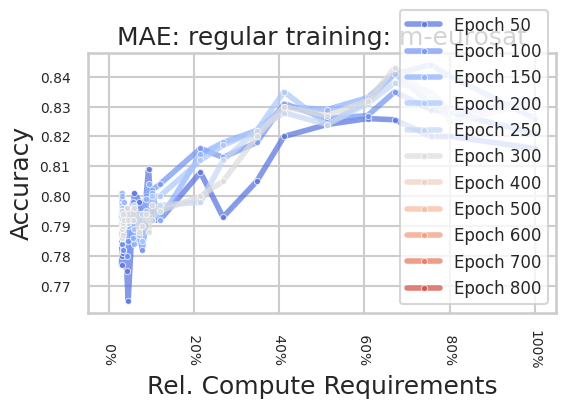

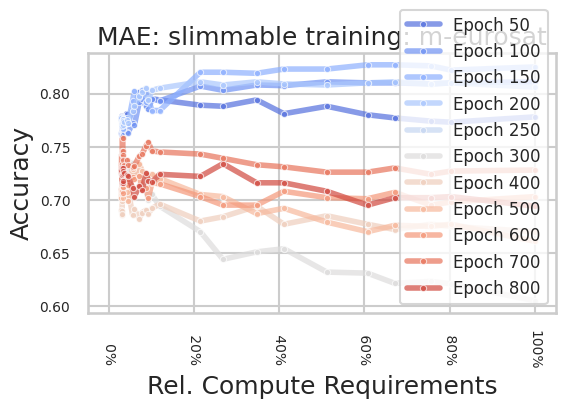

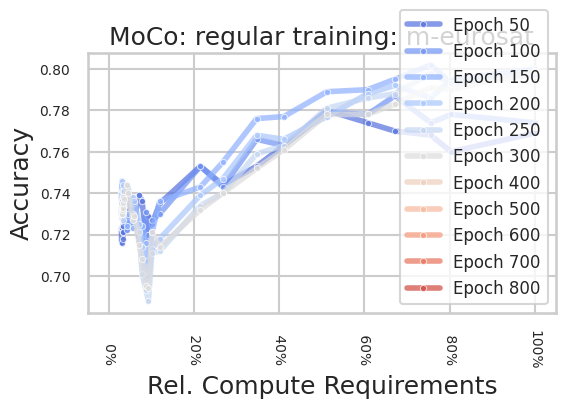

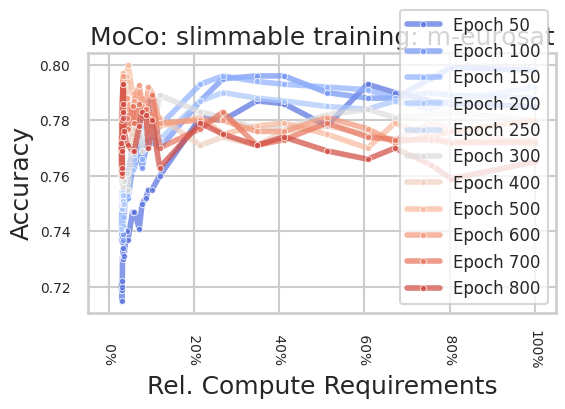

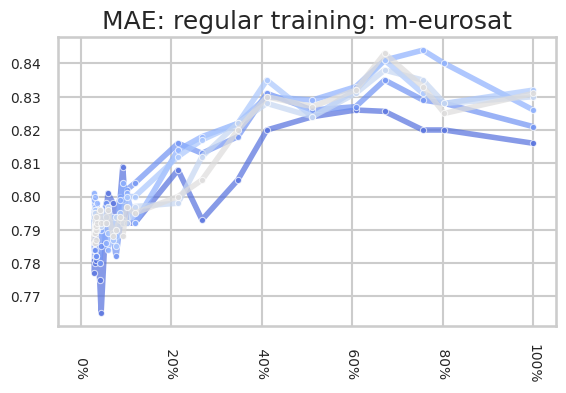

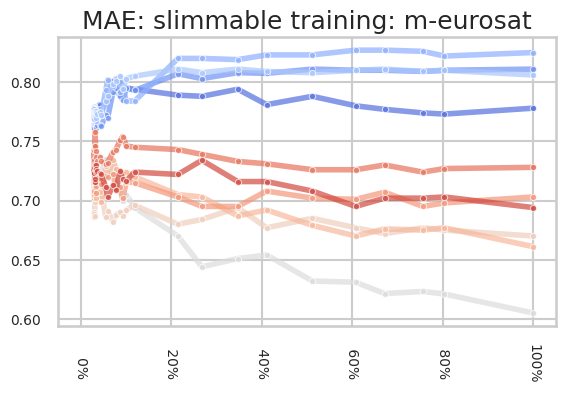

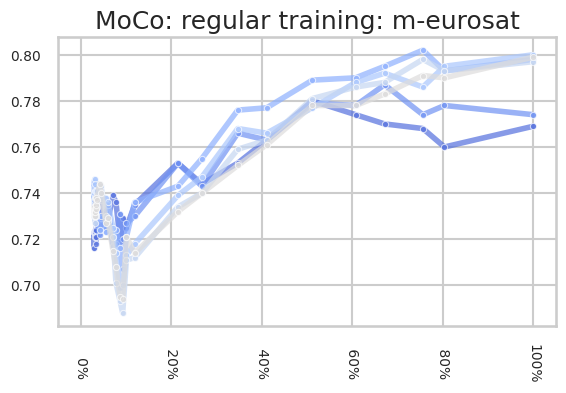

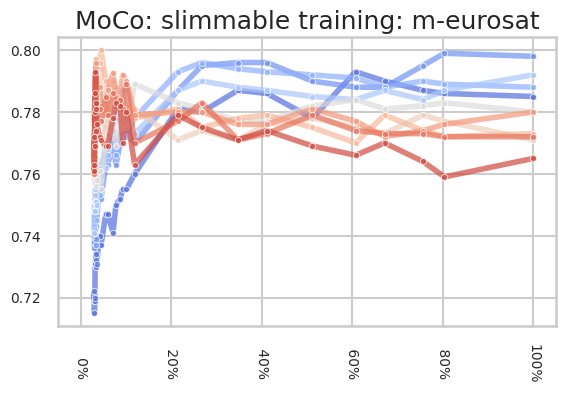

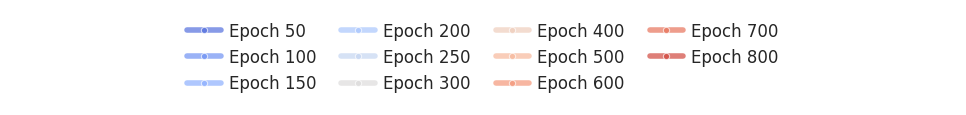

In [106]:
args_list = [(f"{paradigm} ViT base 1.00 epoch{epoch:03d}", dataset, 'knn')
        for paradigm in ['MAE', 'MoCo'] 
        for epoch in range(49, 300, 50)
        for dataset in ['m-eurosat']]
args_list += [(f"{paradigm} ViT base slimable epoch{epoch:03d}", dataset, 'knn')
        for paradigm in ['MAE', 'MoCo'] 
        for epoch in range(49, 200, 50)
        for dataset in ['m-eurosat']]
args_list += [(f"{paradigm} ViT base slimable epoch{epoch:03d}", dataset, 'knn')
        for paradigm in ['MAE', 'MoCo'] 
        for epoch in range(299, 800, 100)
        #for epoch in range(299, 300, 100)
        for dataset in ['m-eurosat']]
dfs = []
for args in args_list:
    part_df = read_results(*args, avg=True)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
df['epoch'] = df.original_model_name.apply(lambda n: f"Epoch {int(n.split(' ')[-1][-3:])+1}")
# print(df[['dataset', 'model', 'Exact Rel. Compute Requirement',  'metric', 'Rel. Retention Rate of 100%', 'scale', 'original_model_name']].sort_values(by=['dataset', 'original_model_name', 'Exact Rel. Compute Requirement']).to_markdown())

unique_epochs = sorted(df['epoch'].unique(), key=lambda x: int(x.split(' ')[-1]))
palette_map = dict(zip(unique_epochs, sns.color_palette("coolwarm", len(unique_epochs))))



for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        for model in df.model.unique():
            df_ds_mod = df[(df.dataset == dataset) & (df.model == model)]
            fig, ax = plt.subplots(figsize=(6, 4))
            metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
        
            sns.lineplot(
                data=df_ds_mod,
                x='Exact Rel. Compute Requirement', y='metric',
                marker='.', 
                ax=ax, hue='epoch',
                palette=palette_map,
                hue_order=unique_epochs,
                alpha=0.7,
                linewidth=4, errorbar=errorbar_setting
            )
        
            #ax.set_xscale('log')
            ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
            ax.xaxis.minorticks_off()
            shared_handles, shared_labels = ax.get_legend_handles_labels()
            if mark_axis_legend:
                ax.set_xlabel('Rel. Compute Requirements')
                ax.set_ylabel(metric_str)
                ax.legend(loc='lower right', fontsize=legend_fontsize)
            else:
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.legend([],[], frameon=False)
            ax.tick_params(axis='both', which='both', labelsize=10)
            ax.tick_params(axis='x', which='both', labelrotation=-90)
            ax.set_xlim(left=-0.05, right=1.05)
            plt.tight_layout()
            Path(f"{FIGURE_BASE}/training").resolve().mkdir(exist_ok=True, parents=True)
            plt.savefig(f"{FIGURE_BASE}/training/slimability_during_{'slimable_' if 'slimmable' in model else ''}training_{'MAE' if 'MAE' in model else 'MoCo'}_{dataset}{'' if mark_axis_legend else '_nolegend'}.pdf")
            plt.title(f"{model}: {dataset}")  # only print title after saving
            plt.show()

get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'slimability_during_training_legend_only.pdf', ncol=4)

## KNN vs Linear vs Finetuning (Classification)

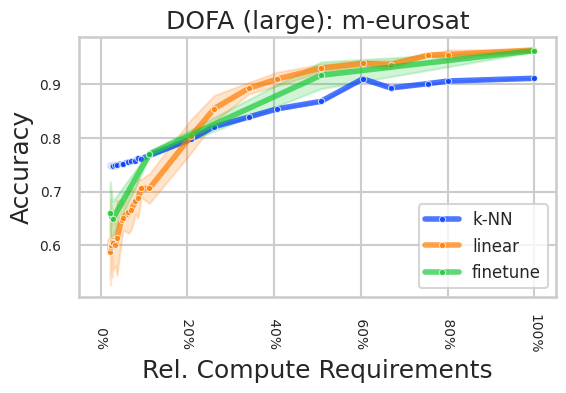

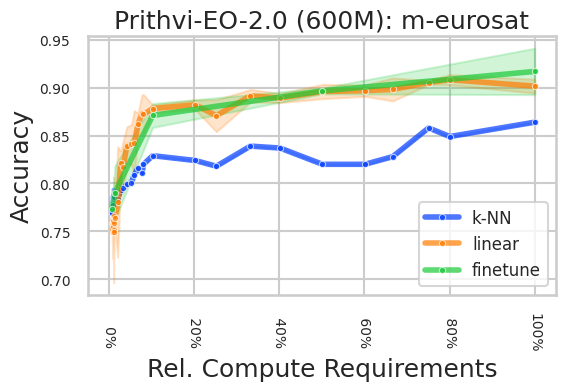

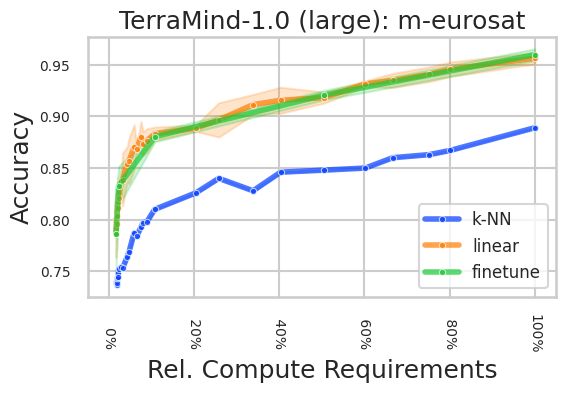

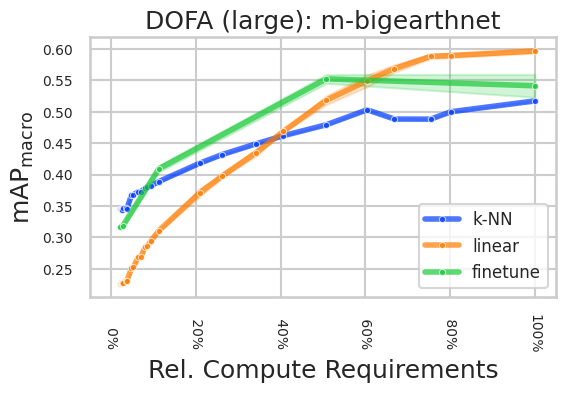

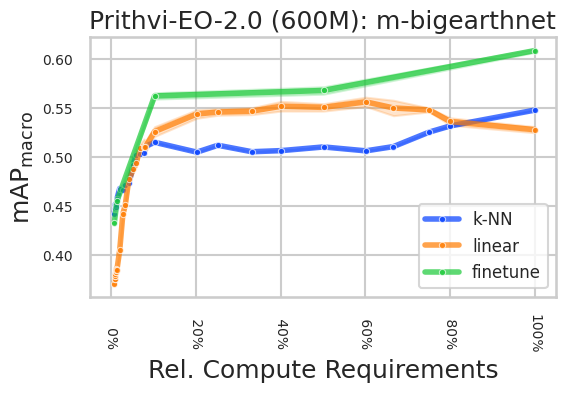

...

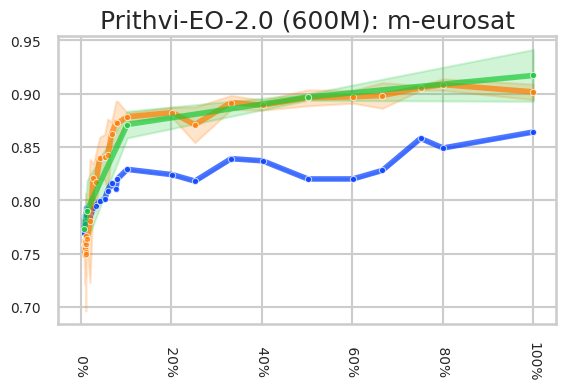

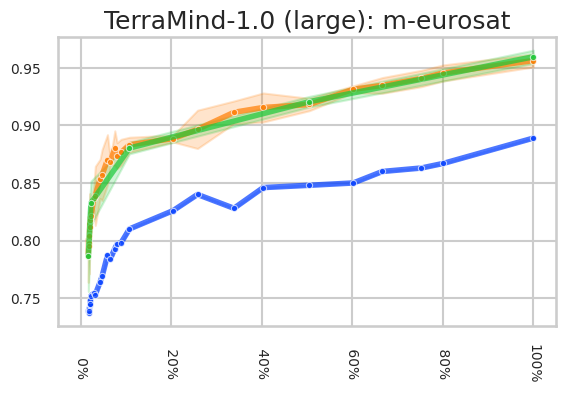

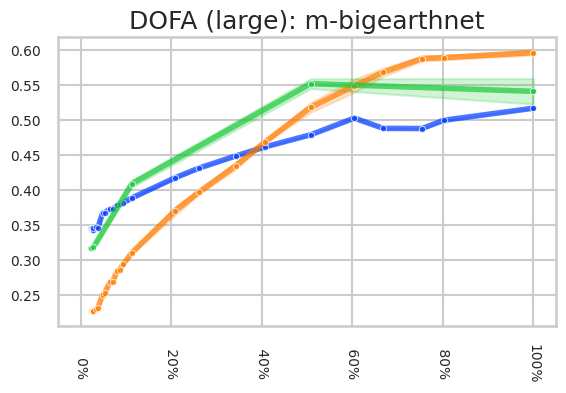

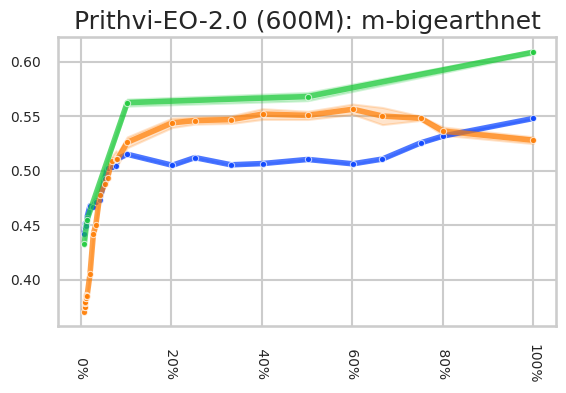

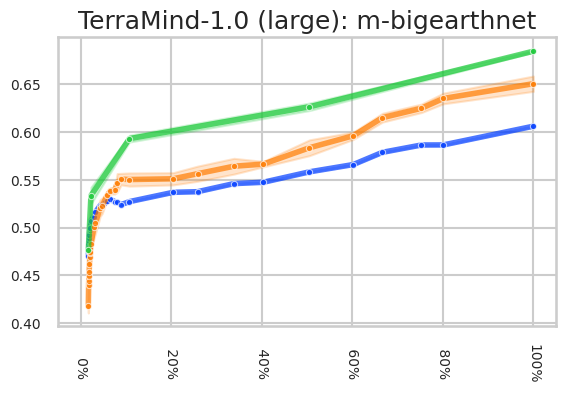

/tmp/ipykernel_101201/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


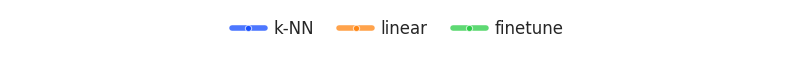

In [110]:
args_list = [(model, dataset, 'knn')
        for model in ['dofa_large', 'terramind_large', 'prithvi2_600'] 
        for dataset in ['m-eurosat', 'm-bigearthnet']]
args_list += [(model, dataset, 'linear')
        for model in ['dofa_large', 'terramind_large', 'prithvi2_600'] 
        for dataset in ['m-eurosat', 'm-bigearthnet']]
args_list += [(model, dataset, 'finetune')
        for model in ['dofa_large', 'terramind_large', 'prithvi2_600'] 
        for dataset in ['m-eurosat', 'm-bigearthnet']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
df.task = df.task.apply(lambda t: 'k-NN' if t == 'knn' else t)

for mark_axis_legend in [True, False]:
    for dataset in df.dataset.unique():
        for model in df.model.unique():
            df_ds_mod = df[(df.dataset == dataset) & (df.model == model)]
            fig, ax = plt.subplots(figsize=(6, 4))
            metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
        
            sns.lineplot(
                data=df_ds_mod,
                x='Exact Rel. Compute Requirement', y='metric',
                marker='.', 
                ax=ax, hue='task',
                palette='bright',
                alpha=0.7,
                linewidth=4, errorbar=errorbar_setting
            )
        
            #ax.set_xscale('log')
            ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
            ax.xaxis.minorticks_off()
            shared_handles, shared_labels = ax.get_legend_handles_labels()
            if mark_axis_legend:
                ax.set_xlabel('Rel. Compute Requirements')
                ax.set_ylabel(metric_str)
                ax.legend(loc='lower right', fontsize=legend_fontsize)
            else:
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.legend([],[], frameon=False)
            ax.tick_params(axis='both', which='both', labelsize=10)
            ax.tick_params(axis='x', which='both', labelrotation=-90)
            ax.set_xlim(left=-0.05, right=1.05)
            plt.tight_layout()
            Path(f"{FIGURE_BASE}/knn_vs_linear").resolve().mkdir(exist_ok=True, parents=True)
            plt.savefig(f"{FIGURE_BASE}/knn_vs_linear/knn_vs_linear_{df_ds_mod.original_model_name.unique()[0]}_{dataset}{'_nolegend' if not mark_labels else ''}.pdf")
            plt.title(f"{model}: {dataset}")  # only print title after saving
            plt.show()
get_legends(shared_handles, f"{FIGURE_BASE}/legends", 'knn_vs_linear_legend_only.pdf', ncol=4)

## Failure Modes

### m-bigearthnet classwise accuracy

In [57]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm

# Provide a list of models to evaluate
models = ['dofa', 'terramind', 'prithvi2_300'] 
dataset = 'm-bigearthnet'

model_name_to_max_dim = {
    'v014.6': 768, 
    'v015.1': 256, 
    'prithvi2_300': 1024, 
    'prithvi2_600': 1280,
    'terramind_large': 1024, 
    'terramind': 768, 
    'dofa_large': 1024, 
    'dofa': 768,
    'ssl4eo_moco': 384, 
    'ssl4eo_dino': 384, 
    '-tiny-': 192, 
    '-base-': 768, 
    'panopticon': 768,
    'copernicusFM': 768
}

task = [t for t in geobench.task_iterator(benchmark_name="classification_v1.0") if t.dataset_name == dataset][0]
scales = SCALES

MAP = 'test/MultilabelAveragePrecision'
records, worst_classes_info, best_classes_info = [], [], []

for model in models:
    model_name, max_dim = next((m, d) for m, d in model_name_to_max_dim.items() if m in model)

    results = {}
    for scale in tqdm(scales, desc=f"Running for {model}"):
        results[scale] = redundant_feature_helpers.test_features_knn(
            model_name, scale, dataset, dim=max_dim, seed=0,
            base_path=FEATURE_BASE + '/' + ACTIVE_SLIM
        )

    class_aps = torch.stack([torch.as_tensor(results[sc][f'{MAP}_class']) for sc in scales]).cpu()
    worst_idx = int(class_aps.mean(0).argmin())
    best_idx = int(class_aps.mean(0).argmax())
    worst_classes_info.append(f"{MODEL_SHORT_TO_LABEL[model]}: index {worst_idx} - {task.label_type.class_name[worst_idx]}")
    best_classes_info.append(f"{MODEL_SHORT_TO_LABEL[model]}: index {best_idx} - {task.label_type.class_name[best_idx]}")

    for scale, cap in zip(scales, class_aps.numpy()):
        for metric, val in [
            ('macro mAP', results[scale][f'{MAP}_macro']),
            ('micro mAP', results[scale][f'{MAP}_micro']),
            ('AP of globally worst class', cap[worst_idx]),
            ('AP of globally best class', cap[best_idx]),
        ]:
            records.append(dict(model=model, scale=scale, metric=metric, value=float(val)))

print("Worst classes:\n" + "\n".join(worst_classes_info))
print("Best classes:\n" + "\n".join(best_classes_info))

df = pd.DataFrame(records)

flop_col = f'flops_{ACTIVE_FLOPS[ACTIVE_SLIM]}'

df = df.merge(
    model_flops[['model', 'scale', flop_col]].rename(columns={'model': 'model_style', flop_col: 'flops'}),
    left_on=['model', 'scale'], right_on=['model_style', 'scale'],
    how='left', validate='many_to_one',
).drop(columns='model_style')

assert df.flops.notna().all(), df[df.flops.isna()][['model', 'scale']].drop_duplicates()

# same as read_results: max over the scales present for that model
df['Exact Rel. Compute Requirement'] = df.flops / df.groupby('model').flops.transform('max')

# only after the merge, so the palette keys match your other plots
df['model'] = df.model.map(model_name_for_plot)

Running for prithvi2_300: 100%|███████████████████████████████████████████████████████████████| 31/31 [00:07<00:00,  4.01it/s]

Worst classes:
DOFA (base): index 1 - Airports
TerraMind-1.0 (base): index 13 - Dump sites
Prithvi-EO-2.0 (300M): index 38 - Sport and leisure facilities
Best classes:
DOFA (base): index 36 - Sea and ocean
TerraMind-1.0 (base): index 3 - Bare rock
Prithvi-EO-2.0 (300M): index 3 - Bare rock


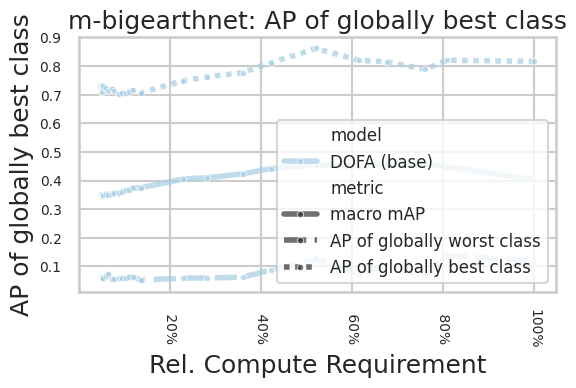

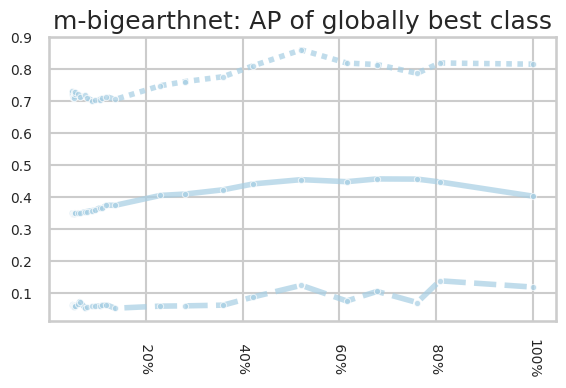

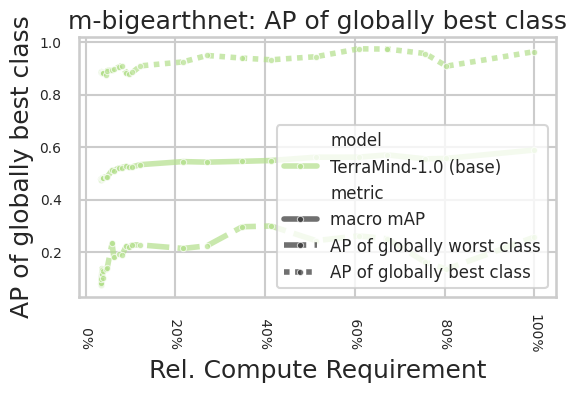

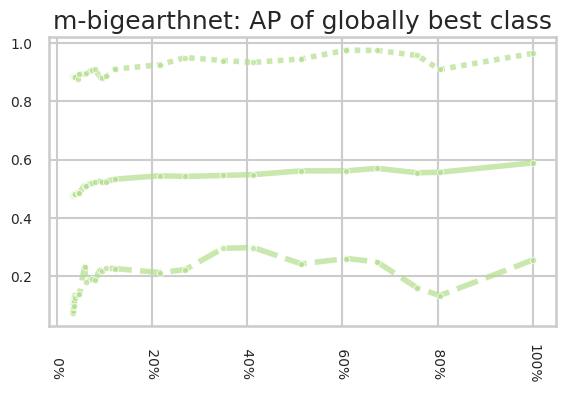

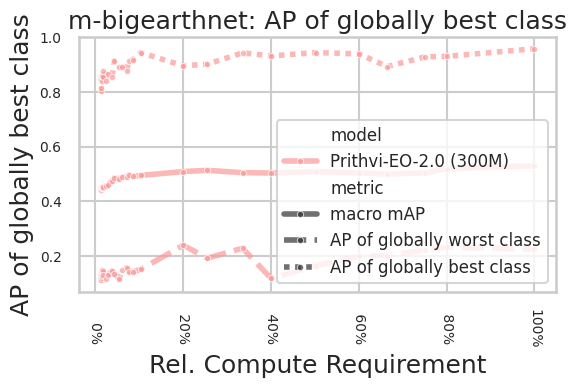

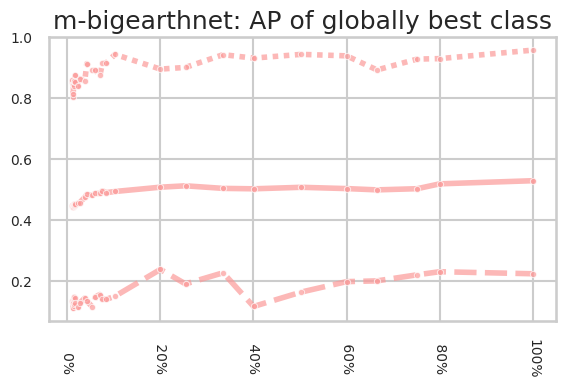

/tmp/ipykernel_4137013/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


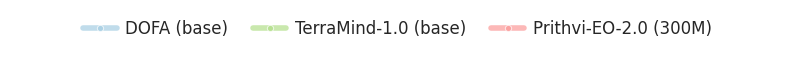

/tmp/ipykernel_4137013/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


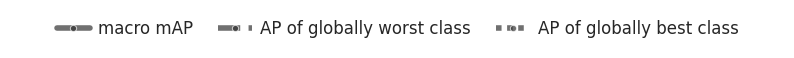

In [58]:
lsh = []
for model in df.model.unique():
    for mark_axis_legend in [True, False]:
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.lineplot(
            data=df[(df.model==model) & (df.metric!= 'micro mAP')], 
            x='Exact Rel. Compute Requirement', y='value',
            marker='.', 
            ax=ax, hue='model', 
            style='metric',
            palette=model_colors, 
            alpha=0.7, 
            linewidth=4,
        )
        
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        shared_handles, shared_labels = ax.get_legend_handles_labels()
        lsh += [shared_handles]
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirement')
            ax.set_ylabel(metric)
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel(''); ax.set_ylabel('')
            ax.legend([], [], frameon=False)
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', labelrotation=-90)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/failure_mode_classes").resolve().mkdir(exist_ok=True, parents=True)
        fname = metric.replace(' ', '_')
        plt.savefig(f"{FIGURE_BASE}/failure_mode_classes/{dataset}_{model}_{fname}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(f"{dataset}: {metric}")
        plt.show()

handles = [lsh[i*2][1] for i in range(3)] 
get_legends(handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_failure_modes_models_legend_only.pdf', ncol=5)
handles = [lsh[0][i+3] for i in range(3)] 
get_legends(handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_failure_modes_versions_legend_only.pdf', ncol=5)

### m-so2sat as defined (which is the de-corellated (Cultural 10) split) vs random splitting

In [59]:
from slimrsfms.models.metrics import build_classification_evaluation_metrics
from redundant_feature_helpers import knn_predict

def test_features_knn_random_split(version, scale, dataset_name, dim=None, seed: int = 42,
                                    knn_k: int = 5, knn_t: float = 0.9, base_path: str = ''):
    feature_bank = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/features_{dataset_name}_train.npy"))
    features = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/features_{dataset_name}_test.npy"))
    assert len(feature_bank[0]) == len(features[0]), \
        f"Features do not have the same dim but bank: {len(feature_bank[0])} and test:{len(features[0])}"

    target_bank = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/labels_{dataset_name}_train.npy")).squeeze()
    true_targets = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/labels_{dataset_name}_test.npy")).squeeze()

    n_train = feature_bank.shape[0]

    all_features = torch.cat([feature_bank, features], dim=0)
    all_targets = torch.cat([target_bank, true_targets], dim=0)

    rng = np.random.default_rng(seed)
    perm = rng.permutation(all_features.shape[0])
    all_features, all_targets = all_features[perm], all_targets[perm]

    feature_bank, features = all_features[:n_train], all_features[n_train:]
    target_bank, true_targets = all_targets[:n_train], all_targets[n_train:].long()

    if dim is not None:
        assert 0 < dim <= features.shape[-1], \
            f"Cannot select {dim} dimensions from a feature of shape {features.shape[-1]}"
        feat_dim_selection = rng.choice(feature_bank.shape[-1], dim, replace=False)
        feature_bank = feature_bank[..., feat_dim_selection]
        features = features[..., feat_dim_selection]

    metrics = build_classification_evaluation_metrics(task="multiclass", num_classes=int(target_bank.max()) + 1)

    prediction_probs = knn_predict(features=features, feature_bank=feature_bank.T,
                                   target_bank=target_bank, knn_k=knn_k, knn_t=knn_t)
    metric_dict = {}
    if "test" in metrics:
        metric_dict.update(metrics["test"](prediction_probs, true_targets))
    if "test_macro" in metrics:
        metric_dict.update(metrics["test_macro"](prediction_probs, true_targets))
    if "test_micro" in metrics:
        metric_dict.update(metrics["test_micro"](prediction_probs, true_targets))
    if "test_sample" in metrics:
        metrics_sample = metrics["test_sample"](prediction_probs.unsqueeze(-1), true_targets.unsqueeze(-1))
        metric_dict.update({k: v.mean() for k, v in metrics_sample.items()})
    if "test_class" in metrics:
        metrics_sample = metrics["test_class"](prediction_probs, true_targets)
        metric_dict.update(metrics_sample)
    return metric_dict

In [81]:
import pandas as pd
import torch
import geobench

# Provide a list of models to evaluate
models = ['dofa', 'terramind', 'prithvi2_300'] 
dataset = 'm-so2sat'

model_name_to_max_dim = {
    'v014.6': 768, 
    'v015.1': 256, 
    'prithvi2_300': 1024, 
    'prithvi2_600': 1280,
    'terramind_large': 1024, 
    'terramind': 768, 
    'dofa_large': 1024, 
    'dofa': 768,
    'ssl4eo_moco': 384, 
    'ssl4eo_dino': 384, 
    '-tiny-': 192, 
    '-base-': 768, 
    'panopticon': 768,
    'copernicusFM': 768
}

scales = SCALES
n_seeds = 5

all_results = []
for model in models:
    model_name, max_dim = None, None
    for m, d in model_name_to_max_dim.items():
        if m in model:
            model_name, max_dim = m, d
            break

    for scale in tqdm(scales, desc=f"Running for model {model}"):
        results = redundant_feature_helpers.test_features_knn(
            model_name, scale, dataset, dim=max_dim, seed=0, base_path=FEATURE_BASE + '/' + ACTIVE_SLIM
        )
        results['model'] = model_name
        results['scale'] = scale
        results['split'] = 'Cultural 10'
        all_results.append(results)

        for seed in range(n_seeds):
            results = test_features_knn_random_split(
                model_name, scale, dataset, dim=max_dim, seed=seed, base_path=FEATURE_BASE + '/' + ACTIVE_SLIM
            )
            results['model'] = model_name
            results['scale'] = scale
            results['split'] = f'random'
            all_results.append(results)

df = pd.DataFrame(all_results)

Running for model prithvi2_300: 100%|█████████████████████████████████████████████████████████| 31/31 [00:33<00:00,  1.07s/it]


In [82]:
metric_col = 'test/MulticlassAccuracy_macro'
if metric_col not in df.columns:
    raise ValueError(f"{metric_col} not in columns: {list(df.columns)}")

# average over seeds (Cultural 10 has one value, random has n_seeds — mean handles both)
agg = df.groupby(['model', 'scale', 'split'])[metric_col].mean().reset_index()

flop_col = f'flops_{ACTIVE_FLOPS[ACTIVE_SLIM]}'

df = agg.merge(
    model_flops[['model', 'scale', flop_col]].rename(columns={'model': 'model_style', flop_col: 'flops'}),
    left_on=['model', 'scale'], right_on=['model_style', 'scale'],
    how='left', validate='many_to_one',
).drop(columns='model_style')

assert df.flops.notna().all(), df[df.flops.isna()][['model', 'scale']].drop_duplicates()

# same as read_results: max over the scales present for that model
df['Exact Rel. Compute Requirement'] = df.flops / df.groupby('model').flops.transform('max')

# only after the merge, so the palette keys match your other plots
df['model'] = df.model.map(model_name_for_plot)

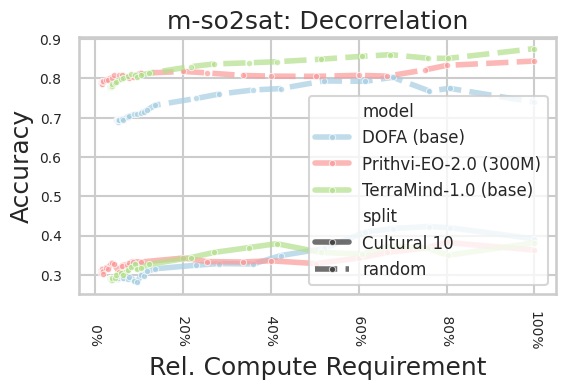

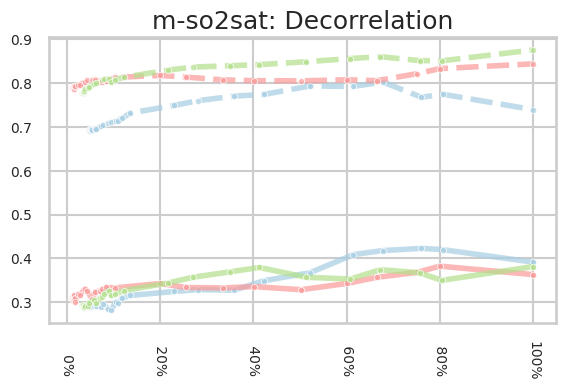

/tmp/ipykernel_4137013/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


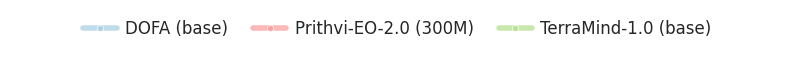

/tmp/ipykernel_4137013/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


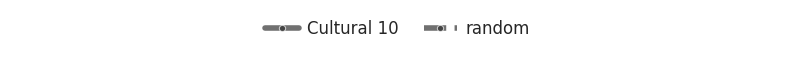

In [83]:
for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.lineplot(
        data=df, 
        x='Exact Rel. Compute Requirement', y='test/MulticlassAccuracy_macro',
        marker='.', 
        ax=ax, hue='model', 
        style='split',
        palette=model_colors, 
        alpha=0.7, 
        linewidth=4,
    )
    
    ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
    ax.xaxis.minorticks_off()
    shared_handles, shared_labels = ax.get_legend_handles_labels()
    if mark_axis_legend:
        ax.set_xlabel('Rel. Compute Requirement')
        ax.set_ylabel("Accuracy")
        ax.legend(loc='lower right', fontsize=legend_fontsize)
    else:
        ax.set_xlabel(''); ax.set_ylabel('')
        ax.legend([], [], frameon=False)
    ax.tick_params(axis='both', which='both', labelsize=10)
    ax.tick_params(axis='x', labelrotation=-90)
    plt.tight_layout()
    Path(f"{FIGURE_BASE}/failure_mode_correlation").resolve().mkdir(exist_ok=True, parents=True)
    fname = metric.replace(' ', '_')
    plt.savefig(f"{FIGURE_BASE}/failure_mode_correlation/{dataset}_{fname}{'' if mark_axis_legend else '_nolegend'}.pdf")
    plt.title(f"{dataset}: Decorrelation")
    plt.show()

get_legends(shared_handles[1:4], f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_failure_mode_correlation_models_legend_only.pdf', ncol=5)
get_legends(shared_handles[5:], f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_failure_mode_correlation_versions_legend_only.pdf', ncol=5)

### m-eurosat with class imbalance

In [49]:
from slimrsfms.models.metrics import build_classification_evaluation_metrics
from redundant_feature_helpers import knn_predict

def apply_class_imbalance(features, targets, imbalance_ratio, seed, num_classes):
    """
    Subsample `features`/`targets` to create exponential class imbalance.
    Classes ordered by label index; class 0 keeps all its samples,
    class (num_classes-1) keeps `imbalance_ratio` fraction.
    imbalance_ratio == 1.0 is a no-op.
    """
    if imbalance_ratio >= 1.0:
        return features, targets

    rng = np.random.default_rng(seed)
    keep_idx = []
    for c in range(num_classes):
        cls_idx = torch.where(targets == c)[0]
        frac = imbalance_ratio ** (c / max(num_classes - 1, 1))
        n_keep = max(1, int(round(len(cls_idx) * frac)))
        chosen = rng.choice(len(cls_idx), n_keep, replace=False)
        keep_idx.append(cls_idx[chosen])
    keep_idx = torch.cat(keep_idx)
    return features[keep_idx], targets[keep_idx]


def test_features_knn_unequal_split(version, scale, dataset_name, dim=None, seed: int = 42,
                                     knn_k: int = 5, knn_t: float = 0.9, base_path: str = '',
                                     imbalance_ratio: float = 1.0):
    feature_bank = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/features_{dataset_name}_train.npy"))
    features = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/features_{dataset_name}_test.npy"))
    assert len(feature_bank[0]) == len(features[0]), \
        f"Features do not have the same dim but bank: {len(feature_bank[0])} and test:{len(features[0])}"

    target_bank = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/labels_{dataset_name}_train.npy")).squeeze().long()
    true_targets = torch.Tensor(np.load(f"{base_path}/{version}/scale_{scale}/labels_{dataset_name}_test.npy")).squeeze().long()

    num_classes = int(target_bank.max()) + 1

    if imbalance_ratio < 1.0:
        feature_bank, target_bank = apply_class_imbalance(
            feature_bank, target_bank, imbalance_ratio, seed, num_classes
        )

    if dim is not None:
        assert 0 < dim <= features.shape[-1], \
            f"Cannot select {dim} dimensions from a feature of shape {features.shape[-1]}"
        rng = np.random.default_rng(seed)
        feat_dim_selection = rng.choice(feature_bank.shape[-1], dim, replace=False)
        feature_bank = feature_bank[..., feat_dim_selection]
        features = features[..., feat_dim_selection]

    metrics = build_classification_evaluation_metrics(task="multiclass", num_classes=num_classes)

    prediction_probs = knn_predict(features=features, feature_bank=feature_bank.T,
                                   target_bank=target_bank, knn_k=knn_k, knn_t=knn_t)
    metric_dict = {}
    if "test" in metrics:
        metric_dict.update(metrics["test"](prediction_probs, true_targets))
    if "test_macro" in metrics:
        metric_dict.update(metrics["test_macro"](prediction_probs, true_targets))
    if "test_micro" in metrics:
        metric_dict.update(metrics["test_micro"](prediction_probs, true_targets))
    if "test_sample" in metrics:
        metrics_sample = metrics["test_sample"](prediction_probs.unsqueeze(-1), true_targets.unsqueeze(-1))
        metric_dict.update({k: v.mean() for k, v in metrics_sample.items()})
    if "test_class" in metrics:
        metrics_sample = metrics["test_class"](prediction_probs, true_targets)
        metric_dict.update(metrics_sample)
    return metric_dict

In [62]:
import pandas as pd
import torch
import geobench

models = ['dofa', 'terramind', 'prithvi2_300']
dataset = 'm-eurosat'
model_name_to_max_dim = {
    'v014.6': 768, 'v015.1': 256, 'prithvi2_300': 1024, 'prithvi2_600': 1280,
    'terramind_large': 1024, 'terramind': 768, 'dofa_large': 1024, 'dofa': 768,
    'ssl4eo_moco': 384, 'ssl4eo_dino': 384, '-tiny-': 192, '-base-': 768, 'panopticon': 768, 'copernicusFM': 768
}
scales = SCALES
imbalance_ratios = [1.0, 0.5, 0.1, 0.01]
n_seeds = 5

all_results = []
for model in models:
    model_name, max_dim = None, None
    for m, d in model_name_to_max_dim.items():
        if m in model:
            model_name, max_dim = m, d
            break

    for scale in tqdm(scales, desc=f"Getting imbalance for {model}"):
        for ratio in imbalance_ratios:
            for seed in range(n_seeds):
                results = test_features_knn_unequal_split(
                    model_name, scale, dataset, dim=max_dim, seed=seed,
                    base_path=FEATURE_BASE + '/' + ACTIVE_SLIM,
                    imbalance_ratio=ratio
                )
                results['model'] = model_name
                results['scale'] = scale
                results['imbalance_ratio'] = ratio
                all_results.append(results)

df = pd.DataFrame(all_results)

Getting imbalance for dofa:   0%|          | 0/31 [00:00<?, ?it/s]

Getting imbalance for terramind:   0%|          | 0/31 [00:00<?, ?it/s]

Getting imbalance for prithvi2_300:   0%|          | 0/31 [00:00<?, ?it/s]

In [63]:
df = df.drop(columns='test/MulticlassAccuracy_class', errors='ignore')

metric_col = 'test/MulticlassAccuracy_macro'
if metric_col not in df.columns:
    raise ValueError(f"{metric_col} not in columns: {list(df.columns)}")

# average over seeds (Cultural 10 has one value, random has n_seeds — mean handles both)
agg = df.groupby(['model', 'scale', 'imbalance_ratio'])[metric_col].mean().reset_index()

flop_col = f'flops_{ACTIVE_FLOPS[ACTIVE_SLIM]}'

df = agg.merge(
    model_flops[['model', 'scale', flop_col]].rename(columns={'model': 'model_style', flop_col: 'flops'}),
    left_on=['model', 'scale'], right_on=['model_style', 'scale'],
    how='left', validate='many_to_one',
).drop(columns='model_style')

assert df.flops.notna().all(), df[df.flops.isna()][['model', 'scale']].drop_duplicates()

# same as read_results: max over the scales present for that model
df['Exact Rel. Compute Requirement'] = df.flops / df.groupby('model').flops.transform('max')

# only after the merge, so the palette keys match your other plots
df['model'] = df.model.map(model_name_for_plot)

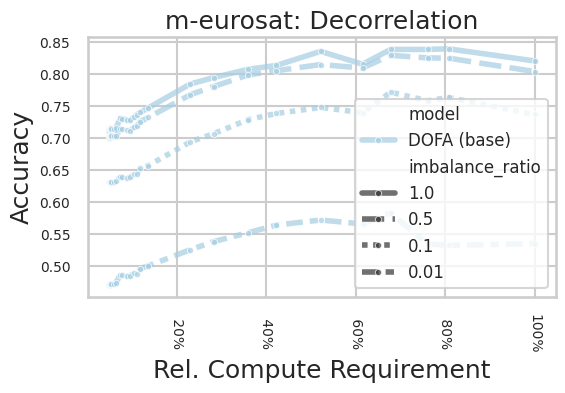

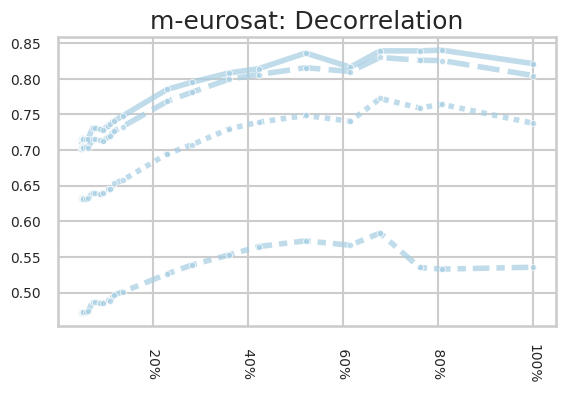

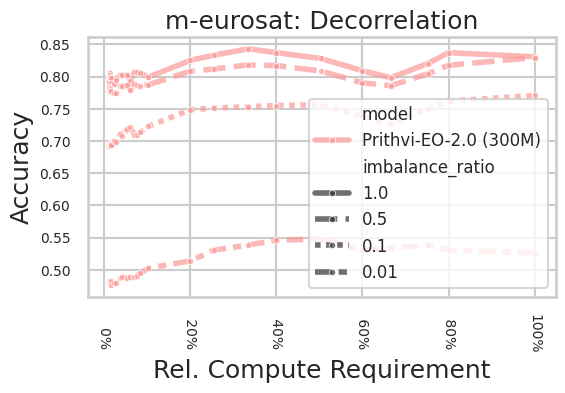

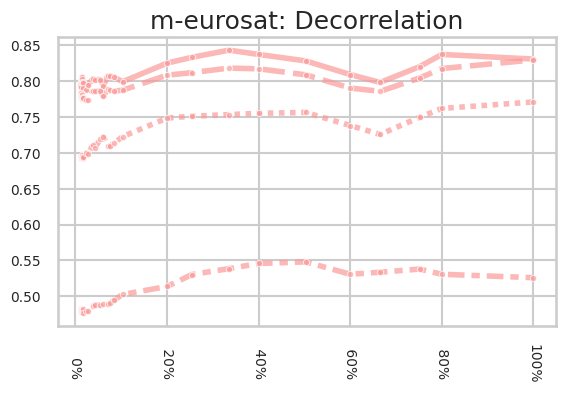

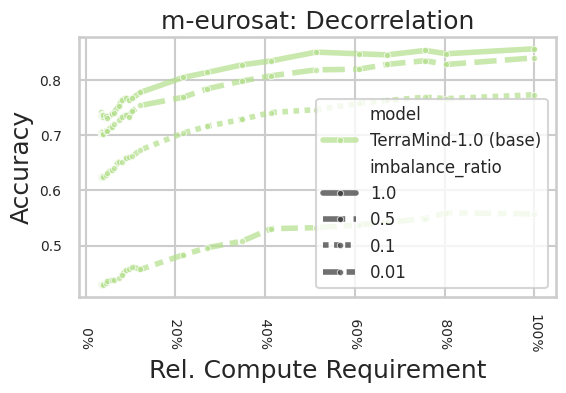

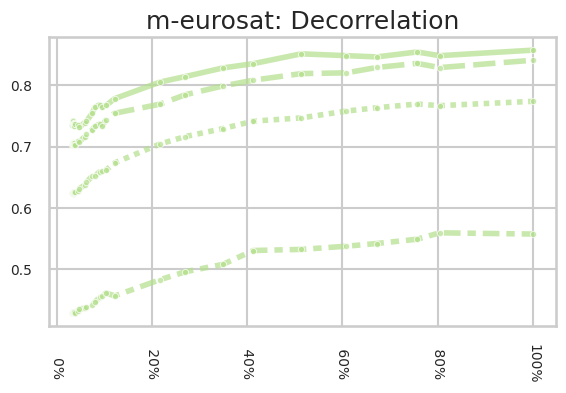

/tmp/ipykernel_375175/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


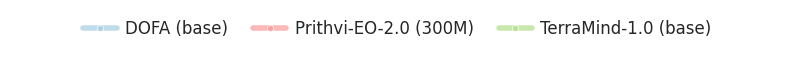

/tmp/ipykernel_375175/4175762872.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


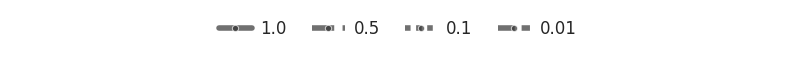

In [69]:
lsh = []

for model in df.model.unique():
    for mark_axis_legend in [True, False]:
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.lineplot(
            data=df[df.model == model], 
            x='Exact Rel. Compute Requirement', y='test/MulticlassAccuracy_macro',
            marker='.', 
            ax=ax, hue='model', 
            style='imbalance_ratio',
            style_order=[1.0, 0.5, 0.1, 0.01],
            palette=model_colors, 
            alpha=0.7, 
            linewidth=4,
        )
        
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        shared_handles, shared_labels = ax.get_legend_handles_labels()
        lsh += [shared_handles]
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirement')
            ax.set_ylabel("Accuracy")
            ax.legend(loc='lower right', fontsize=legend_fontsize)
        else:
            ax.set_xlabel(''); ax.set_ylabel('')
            ax.legend([], [], frameon=False)
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', labelrotation=-90)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/failure_mode_imbalance").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/failure_mode_imbalance/{dataset}_{model}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(f"{dataset}: Decorrelation")
        plt.show()

handles = [lsh[i*2][1] for i in range(3)] 
get_legends(handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_failure_mode_imbalance_models_legend_only.pdf', ncol=5)
handles = [lsh[0][i+3] for i in range(4)] 
get_legends(handles, f"{FIGURE_BASE}/legends", 'post_hoc_slimming_existing_fms_failure_mode_imbalance_versions_legend_only.pdf', ncol=5)

# Not in Paper

## Efficient Baselines (CV Pretrained)
Including MobileNet, MobileViT, etc.

#### Calculation

In [18]:
from operator import itemgetter
from geobench_evaluate import bandorders
from terratorch_baselines import bandorders as terratorch_baseline_bandorders
from geobench_evaluate import get_classification_transform
import torch
import torch.nn as nn
import timm
import lightning as L
from torchmetrics import Accuracy
from torchinfo import summary
torch.set_float32_matmul_precision('medium')

In [19]:
class GeoBenchClassifier(L.LightningModule):
    def __init__(
        self,
        model_name: str = "vit_tiny_patch16_224",
        num_classes: int = 10,
        in_chans: int = 10,
        img_size: int | None = 224,
        pretrained: bool = False,
        finetune: bool = True,
        lr: float = 1e-3,
    ):
        super().__init__()
        self.save_hyperparameters()
        self.model = timm.create_model(
            model_name,
            pretrained=pretrained,
            in_chans=in_chans,
            num_classes=num_classes,
            **({'img_size': img_size} if img_size is not None else {})
        )
        if not finetune:
            for name, param in self.model.named_parameters():
                if "head" not in name:
                    param.requires_grad = False

        self.criterion = nn.CrossEntropyLoss()
        self.test_acc = Accuracy(task="multiclass", num_classes=num_classes)
        img_size = 224 if img_size is None else img_size
        info = summary(self.model, input_size=(1, in_chans, img_size, img_size), verbose=0)
        self.model_flops_forward = info.total_mult_adds
        print(f"Model '{model_name}' has {self.model_flops_forward/1e9:.2f} GFLOPs.")
        self.model_name = model_name

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch["input"], batch["label"]
        return self.criterion(self(x), y)

    def test_step(self, batch, batch_idx):
        x, y = batch["input"], batch["label"]
        preds = self(x).argmax(dim=-1)
        acc = self.test_acc(preds, y)
        self.log("test/acc", self.test_acc, on_step=False, on_epoch=True)

    def on_test_epoch_end(self):
        self.test_result = self.test_acc.compute().item()

    def configure_optimizers(self):
        params = filter(lambda p: p.requires_grad, self.parameters())
        return torch.optim.AdamW(params, lr=self.hparams.lr, weight_decay=0.01)

In [20]:
dataset = 'm-eurosat'
task = [t for t in geobench.task_iterator(benchmark_name="classification_v1.0") if t.dataset_name == dataset][0]
ds = task.get_dataset(split="train")
geobench_dataset_name = ds.task_specs.dataset_name
bandnames = itemgetter(*terratorch_baseline_bandorders['dofa']["classification_v1.0"][geobench_dataset_name])(ds.task_specs.bands_info)
bandnames_param = [bn.name for bn in bandnames]
dm = task.get_pytorch_data_module(
    band_names=bandnames_param,
    train_transform=get_classification_transform(task, bandnames_param, train=True, input_size=224),
    eval_transform=get_classification_transform(task, bandnames_param, train=False, input_size=224),
    batch_size=128,
    num_workers=8,
)
batch = next(iter(dm.train_dataloader()))
batch['input'].shape, batch['label'].shape, ds.task_specs.label_type.n_classes

(torch.Size([128, 10, 224, 224]), torch.Size([128]), 10)

In [21]:
class CachedDataset(torch.utils.data.Dataset):
    def __init__(self, batches):
        self.batches = batches
    def __len__(self):
        return len(self.batches)
    def __getitem__(self, idx):
        return self.batches[idx]

def cache_dataloader(dl):
    print("Caching...")
    batches = [batch for batch in dl]
    return torch.utils.data.DataLoader(
        CachedDataset(batches),
        batch_size=None,      # disables re-batching
        collate_fn=lambda x: x,  # return as-is
        num_workers=0,
        pin_memory=True
    )

def run_classification(model_name, img_size=224, seed=0, finetune=False, pretrained=False):
    L.seed_everything(seed)
    trainer = L.pytorch.Trainer(max_epochs=epochs, accelerator="auto", enable_checkpointing=False, logger=False)

    model = GeoBenchClassifier(num_classes=10, in_chans=10, finetune=finetune, lr=lr, 
                               model_name=model_name, img_size=img_size, pretrained=pretrained)

    #trainer.fit(model, train_dataloaders=dm.train_dataloader())
    #trainer.test(model, dataloaders=dm.test_dataloader())
    trainer.fit(model, train_dataloaders=cached_train)
    trainer.test(model, dataloaders=cached_test)
    return model

In [22]:
epochs = 30
finetune, lr = False, 1e-3
# finetune, lr = True, 1e-4

recalculate_efficient_cv_models = False
if recalculate_efficient_cv_models:
    cached_train = cache_dataloader(dm.train_dataloader())
    cached_test = cache_dataloader(dm.test_dataloader())
    print('Caching complete')

    csv_path = f"/scratch/htc/lhackel/RSFM_redundancy/_features/efficient_cv_models_{dataset}_{'ft' if finetune else 'linear'}.csv"
    completed = set(pd.read_csv(csv_path)['name'].tolist()) if Path(csv_path).exists() else set()

    for model_name, img_size in [
        ('mobilenetv3_small_050', None),
        ('mobilenetv3_small_100', None),
        ('mobilenetv3_large_100', None),
        ('mobilenetv3_large_150d', None),
        ('mobilevitv2_050', 224),
        ('mobilevitv2_100', 224),
        ('mobilevitv2_150', 224),
        ('mobilevitv2_200', 224),
        ('mobilevit_xxs', 224),
        ('mobilevit_xs', 224),
        ('mobilevit_s', 224),
        ('fastvit_sa12', None),
        ('fastvit_sa24', None),
        ('fastvit_sa36', None),
        ('efficientvit_b0', None),
        ('efficientvit_b1', None),
        ('efficientvit_b2', None),
        ('efficientvit_b3', None),
    ]:
        if model_name in completed:
            print(f'Skipping {model_name} (already in CSV)')
            continue
        for seed in [0,1,2,3,4]:
            model = run_classification(model_name, img_size, seed=seed, finetune=finetune, pretrained=True)
            row = pd.DataFrame([{
                'name': model.model_name,
                'flops': model.model_flops_forward,
                'accuracy': model.test_result,
                'seed': seed,
            }])
            row.to_csv(csv_path, mode='a', header=not Path(csv_path).exists(), index=False)
        print(f'Saved {model_name}')

#### Evaluation

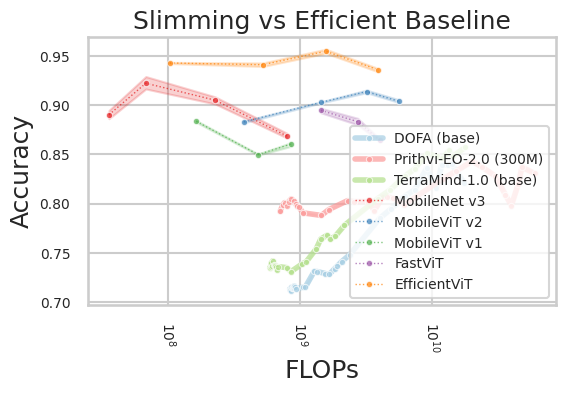

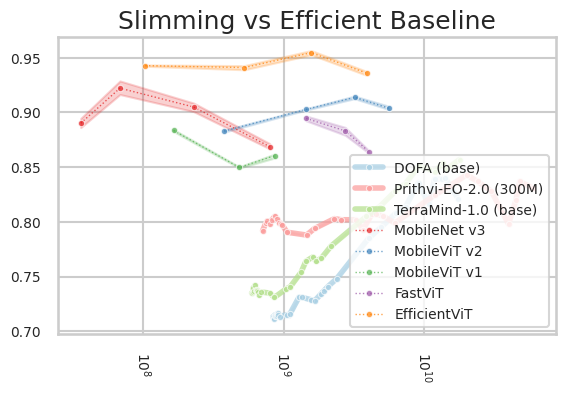

In [23]:
name_mapping = {
    'mobilenetv3_small_050': 'MobileNet v3',
    'mobilenetv3_small_100': 'MobileNet v3',
    'mobilenetv3_large_100': 'MobileNet v3',
    'mobilenetv3_large_150d': 'MobileNet v3',
    'mobilevitv2_050': 'MobileViT v2',
    'mobilevitv2_100': 'MobileViT v2',
    'mobilevitv2_150': 'MobileViT v2',
    'mobilevitv2_200': 'MobileViT v2',
    'mobilevit_xxs': 'MobileViT v1',
    'mobilevit_xs': 'MobileViT v1',
    'mobilevit_s': 'MobileViT v1',
    'fastvit_sa12': 'FastViT',
    'fastvit_sa24': 'FastViT',
    'fastvit_sa36': 'FastViT',
    'efficientvit_b0': 'EfficientViT',
    'efficientvit_b1': 'EfficientViT',
    'efficientvit_b2': 'EfficientViT',
    'efficientvit_b3': 'EfficientViT',
}

df_1 = pd.read_csv(f"{FEATURE_BASE}/efficient_cv_models_m-eurosat_linear.csv")
df_1['task'] = 'linear'
df_baselines = pd.concat([df_1])
#df_2 = pd.read_csv(f"{FEATURE_BASE}/efficient_cv_models_m-eurosat_ft.csv").drop(columns=['Unnamed: 0']).rename({'result': 'accuracy'}, axis=1)
#df_2['task'] = 'tuned'
#df_baselines = pd.concat([df_baselines, df_2])
df_baselines['model'] = df_baselines.name.apply(lambda n: name_mapping[n])

args_list = [(model, dataset, 'knn')
        #for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600'] 
        for model in ['dofa', 'terramind', 'prithvi2_300']
        for dataset in ['m-eurosat']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)

for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))

    sns.lineplot(
        data=df,
        x='flops', y='accuracy',
        marker='.', 
        ax=ax, hue='model',
        palette=PAIRED_COLORS_SMALL,
        alpha=0.7,
        linewidth=4, errorbar=errorbar_setting
    )

    sns.lineplot(
        data=df_baselines,
        x='flops', y='accuracy',
        marker='.', 
        ax=ax, hue='model',# style='task',
        palette='Set1',
        alpha=0.7,
        linewidth=1, linestyle='dotted'
    )

    ax.set_xscale('log')
    #ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
    ax.xaxis.minorticks_off()
    ax.legend(loc='lower right', fontsize=legend_fontsize)
    if mark_axis_legend:
        ax.set_xlabel('FLOPs')
        ax.set_ylabel('Accuracy')
    else:
        ax.set_xlabel('')
        ax.set_ylabel('')
    ax.tick_params(axis='both', which='both', labelsize=10)
    ax.tick_params(axis='x', which='both', labelrotation=-90)
    plt.tight_layout()
    Path(f"{FIGURE_BASE}/slimming_vs_efficient_baseline/").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{FIGURE_BASE}/slimming_vs_efficient_baseline/slimming_vs_efficient_CV_baseline{'' if mark_axis_legend else '_nolegend'}.pdf")
    plt.title("Slimming vs Efficient Baseline")  # only print title after saving
    plt.show()

## Efficient Baselines (RS Models)

#### Calculation

In [24]:
from operator import itemgetter
from geobench_evaluate import bandorders
from terratorch_baselines import bandorders as terratorch_baseline_bandorders
from geobench_evaluate import get_classification_transform
import torch
import torch.nn as nn
import timm
import lightning as L
from torchmetrics import Accuracy
from torchinfo import summary
import torchgeo.models as tgm
from torchgeo.models import ResNet18_Weights, ResNet50_Weights, ViTSmall16_Weights
import torch
import torch.nn as nn
torch.set_float32_matmul_precision('medium')

In [25]:
model_configs = [
    (tgm.resnet18, ResNet18_Weights.SENTINEL2_ALL_MOCO, 'ResNet-18', 'MoCo'),
    (tgm.resnet50, ResNet50_Weights.SENTINEL2_ALL_MOCO, 'ResNet-50', 'MoCo'),
    (tgm.resnet50, ResNet50_Weights.SENTINEL2_ALL_DINO, 'ResNet-50', 'DINO'),
    (tgm.vit_small_patch16_224, ViTSmall16_Weights.SENTINEL2_ALL_DINO, 'ViT (small)', 'DINO'),
    (tgm.vit_small_patch16_224, ViTSmall16_Weights.SENTINEL2_ALL_MOCO, 'ViT (small)', 'MoCo'),
    (tgm.vit_small_patch16_224, ViTSmall16_Weights.SENTINEL2_ALL_MAE, 'ViT (small)', 'MAE'),
]

In [26]:
dataset = 'm-eurosat'
task = [t for t in geobench.task_iterator(benchmark_name="classification_v1.0") if t.dataset_name == dataset][0]

# Build dm with all 13 S2 bands (what this model expects)
s2_bands_eurosat = [
    '01 - Coastal aerosol', '02 - Blue', '03 - Green', 
    '04 - Red', '05 - Vegetation Red Edge', '06 - Vegetation Red Edge', 
    '07 - Vegetation Red Edge', '08 - NIR', '08A - Vegetation Red Edge', 
    '09 - Water vapour', '10 - SWIR - Cirrus', '11 - SWIR', 
    '12 - SWIR']
dm_tg = task.get_pytorch_data_module(
    band_names=s2_bands_eurosat,
    train_transform=get_classification_transform(task, s2_bands_eurosat, train=False, input_size=224),
    eval_transform=get_classification_transform(task, s2_bands_eurosat, train=False, input_size=224),
    batch_size=128,
    num_workers=8,
)

In [27]:
from redundant_feature_helpers import get_features_and_labels
from redundant_feature_helpers import knn_predict
import torch.nn.functional as F

recalculate = False
csv_path = f"/scratch/htc/lhackel/RSFM_redundancy/_features/efficient_rs_models_{dataset}_knn_scores_1way.csv"
if recalculate:
    for model_cls, weights, model_type, training_paradigm in model_configs:
        tg_model = model_cls(weights=weights)
        backbone = nn.Sequential(*list(tg_model.children())[:-1], nn.Flatten())
        backbone.eval()
    
        train_features, train_labels = get_features_and_labels(backbone, dm_tg, mode='train')
        test_features, test_labels = get_features_and_labels(backbone, dm_tg, mode='test')
    
        feature_bank = torch.tensor(train_features)
        features = torch.tensor(test_features)
        target_bank = torch.tensor(train_labels)
        true_targets = torch.tensor(test_labels)
        
        pred_probs = knn_predict(
            features=features,
            feature_bank=feature_bank.T,
            target_bank=target_bank,
            knn_k=5,
            knn_t=0.9,
        )
        preds = pred_probs.argmax(dim=-1)
        acc = (preds == true_targets).float().mean().item()
    
        
        row = pd.DataFrame([{
            'name': model_type,
            'training_paradigm': training_paradigm,
            'accuracy': acc,
            'flops': summary(backbone, input_size=(1, 13, 224, 224), verbose=0).total_mult_adds,
        }])
        row.to_csv(csv_path, mode='a', header=not Path(csv_path).exists(), index=False)

#### Evaluation

In [28]:
df_baselines = pd.read_csv(f"/scratch/htc/lhackel/RSFM_redundancy/_features/efficient_rs_models_m-eurosat_knn_scores_1way.csv")
df_baselines.rename({'name': 'Architecture', 'training_paradigm': 'Training Paradigm'}, inplace=True, axis=1)

args_list = [(model, dataset, 'knn')
        #for model in ['dofa', 'dofa_large', 'terramind', 'terramind_large', 'prithvi2_300', 'prithvi2_600'] 
        for model in ['dofa', 'terramind', 'prithvi2_300']
        for dataset in ['m-eurosat']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)

df = pd.concat(dfs).sort_values(['model','scale']).reset_index(drop=True)
print(df_baselines)

   Architecture Training Paradigm  accuracy       flops
0     ResNet-18              MoCo     0.741  2206950784
1     ResNet-50              MoCo     0.759  4480569216
2     ResNet-50              DINO     0.753  4480569216
3   ViT (small)              DINO     0.567   271848192
4   ViT (small)              MoCo     0.554   271848192
5   ViT (small)               MAE     0.622   271848192
6     ResNet-18              MoCo     0.741  2206950784
7     ResNet-50              MoCo     0.759  4480569216
8     ResNet-50              DINO     0.754  4480569216
9   ViT (small)              DINO     0.567   271848192
10  ViT (small)              MoCo     0.553   271848192
11  ViT (small)               MAE     0.622   271848192


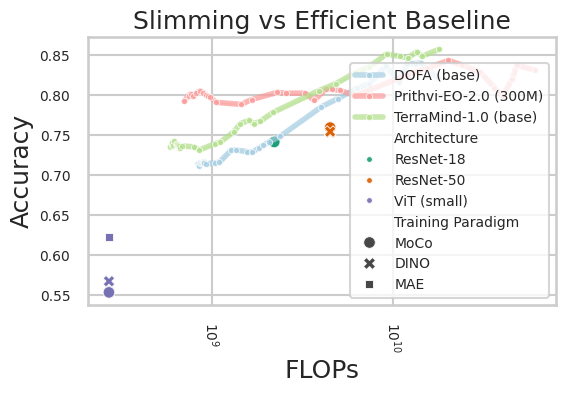

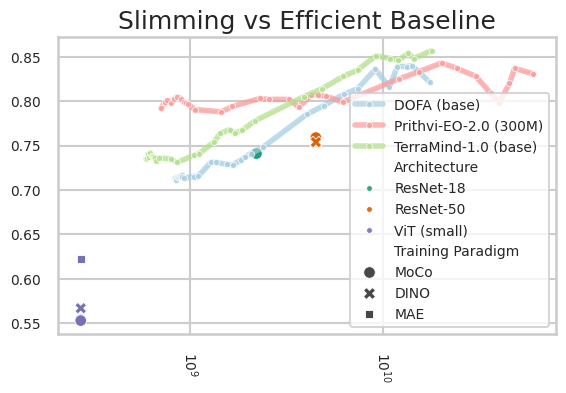

In [29]:
for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))

    sns.lineplot(
        data=df,
        x='flops', y='accuracy',
        marker='.', 
        ax=ax, hue='model',
        palette=PAIRED_COLORS_SMALL,
        alpha=0.7,
        linewidth=4, errorbar=errorbar_setting
    )

    sns.scatterplot(
        data=df_baselines,
        x='flops', y='accuracy',
        marker='.', 
        ax=ax, hue='Architecture', style='Training Paradigm',
        palette='Dark2',
        alpha=0.9,
        s=70
    )

    ax.set_xscale('log')
    #ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
    ax.xaxis.minorticks_off()
    ax.legend(loc='lower right', fontsize=legend_fontsize)
    if mark_axis_legend:
        ax.set_xlabel('FLOPs')
        ax.set_ylabel('Accuracy')
    else:
        ax.set_xlabel('')
        ax.set_ylabel('')
    ax.tick_params(axis='both', which='both', labelsize=10)
    ax.tick_params(axis='x', which='both', labelrotation=-90)
    plt.tight_layout()
    Path(f"{FIGURE_BASE}/slimming_vs_efficient_baseline/").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{FIGURE_BASE}/slimming_vs_efficient_baseline/slimming_vs_efficient_RS_baseline{'' if mark_axis_legend else '_nolegend'}.pdf")
    plt.title("Slimming vs Efficient Baseline")  # only print title after saving
    plt.show()

## CV Baselines with different number of Classes
ImageNet-n ablation

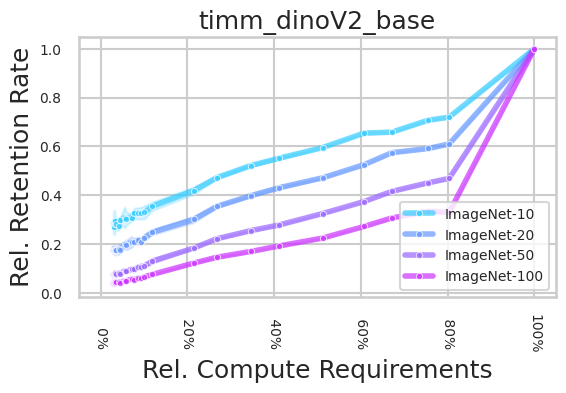

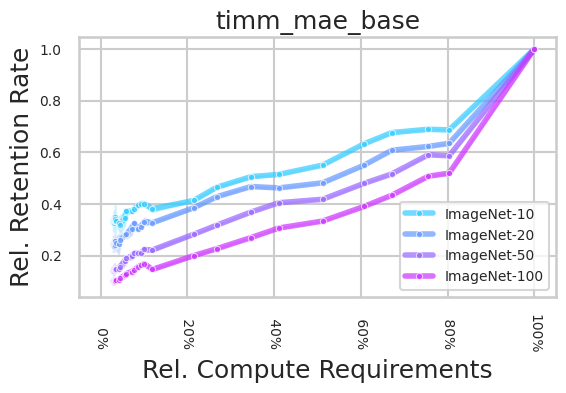

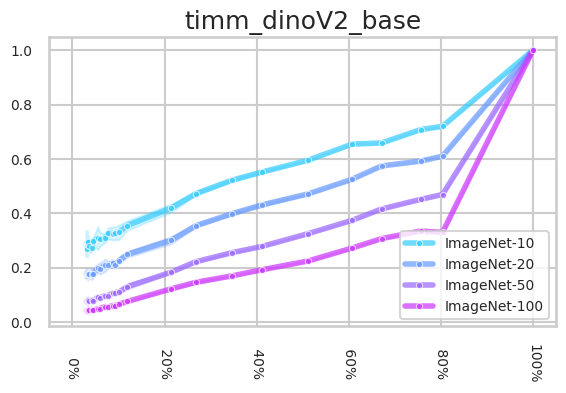

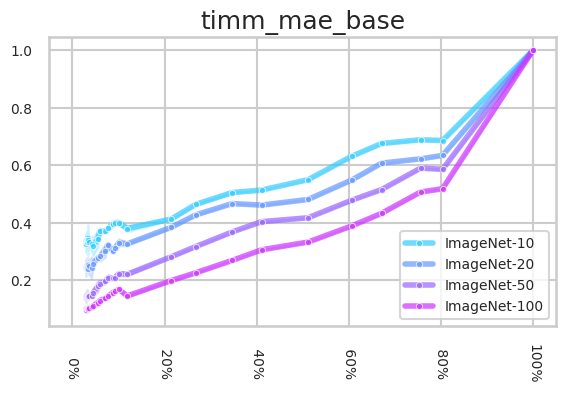

In [32]:
args_list = [(model, dataset, 'knn')
        for model in ['timm_dinoV2_base', 'timm_mae_base'] 
        for dataset in ['ImageNet010', 'ImageNet020', 'ImageNet050', 'ImageNet100']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)
    
df = pd.concat(dfs)
df['dataset'] = df.dataset.apply(lambda ds: f"ImageNet-{int(ds.split('ImageNet')[-1])}" if 'ImageNet' in ds else ds)

DATASET_COLORS = {
    'CIFAR10':       sns.color_palette('winter', 10)[1],
    'ImageNet-10':   sns.color_palette('cool', 4)[0],
    'ImageNet-20':   sns.color_palette('cool', 4)[1],
    'ImageNet-50':   sns.color_palette('cool', 4)[2],
    'ImageNet-100':  sns.color_palette('cool', 4)[3],
    'm-bigearthnet': sns.color_palette('autumn', 5)[0],
    'm-eurosat':     sns.color_palette('autumn', 5)[4],
}

for mark_axis_legend in [True, False]:
    for original_model_name in df.original_model_name.unique():
        df_mod = df[df.original_model_name == original_model_name]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_mod,
            x='Exact Rel. Compute Requirement', y='Rel. Retention Rate',
            marker='.', 
            ax=ax, hue='dataset',
            palette=DATASET_COLORS,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting
        )
    
        #ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        ax.legend(loc='lower right', fontsize=legend_fontsize)
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel('Rel. Retention Rate')
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/cv_baseline_by_cv_classcount").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/cv_baseline_by_cv_classcount/slimmability_by_cv_classcount_{original_model_name}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(f"{original_model_name}")  # only print title after saving
        plt.show()

## CV Baselines with different Dataset

### CV Baselines on other CV Datasets

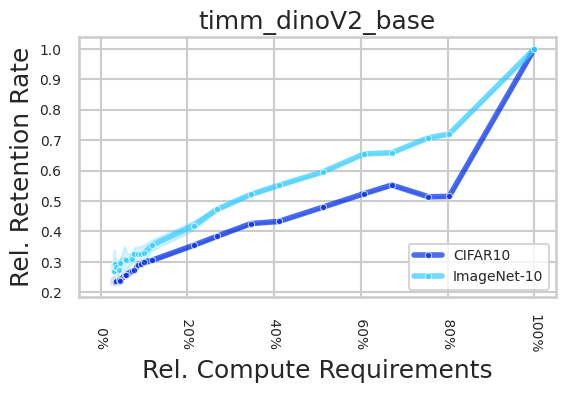

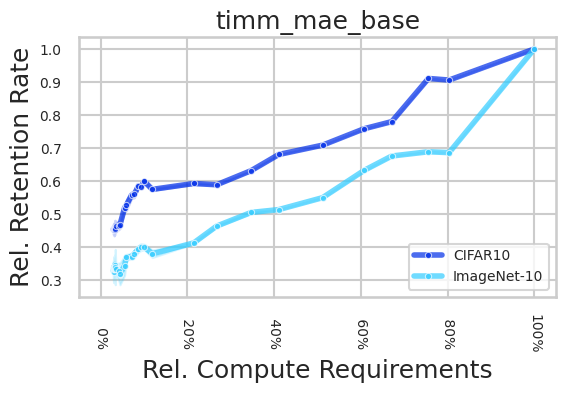

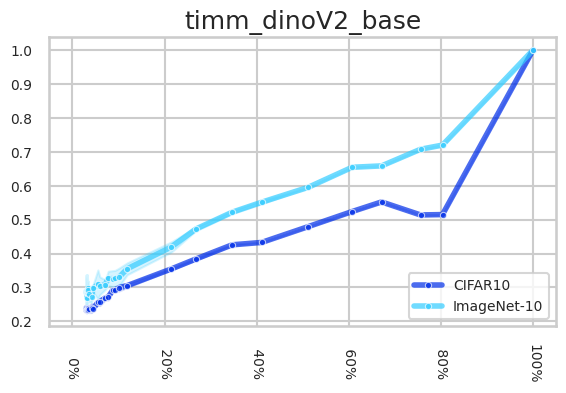

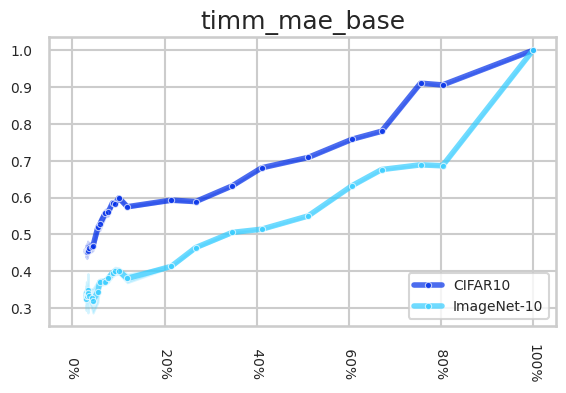

In [33]:
args_list = [(model, dataset, 'knn')
        for model in ['timm_dinoV2_base', 'timm_mae_base'] 
        for dataset in ['CIFAR10', 'ImageNet010']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)
    
df = pd.concat(dfs)
df['dataset'] = df.dataset.apply(lambda ds: f"ImageNet-{int(ds.split('ImageNet')[-1])}" if 'ImageNet' in ds else ds)

DATASET_COLORS = {
    'CIFAR10':       sns.color_palette('winter', 10)[1],
    'ImageNet-10':   sns.color_palette('cool', 4)[0],
    'ImageNet-20':   sns.color_palette('cool', 4)[1],
    'ImageNet-50':   sns.color_palette('cool', 4)[2],
    'ImageNet-100':  sns.color_palette('cool', 4)[3],
    'm-bigearthnet': sns.color_palette('autumn', 5)[0],
    'm-eurosat':     sns.color_palette('autumn', 5)[4],
}

for mark_axis_legend in [True, False]:
    for original_model_name in df.original_model_name.unique():
        df_mod = df[df.original_model_name == original_model_name]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_mod,
            x='Exact Rel. Compute Requirement', y='Rel. Retention Rate',
            marker='.', 
            ax=ax, hue='dataset',
            palette=DATASET_COLORS,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting
        )
    
        #ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        ax.legend(loc='lower right', fontsize=legend_fontsize)
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel('Rel. Retention Rate')
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/cv_baseline_by_cv_dataset").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/cv_baseline_by_cv_dataset/slimmability_by_cv_dataset_{original_model_name}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(f"{original_model_name}")  # only print title after saving
        plt.show()

### CV Baselines on RS Datasets

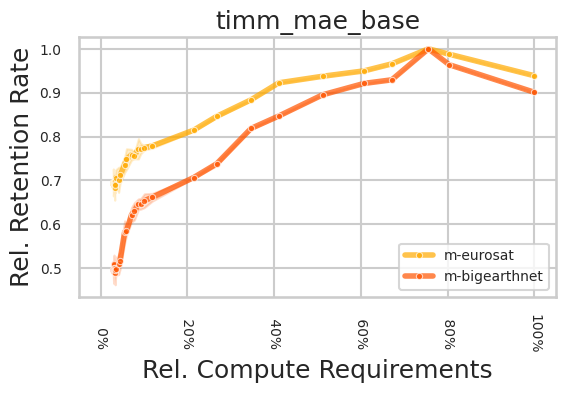

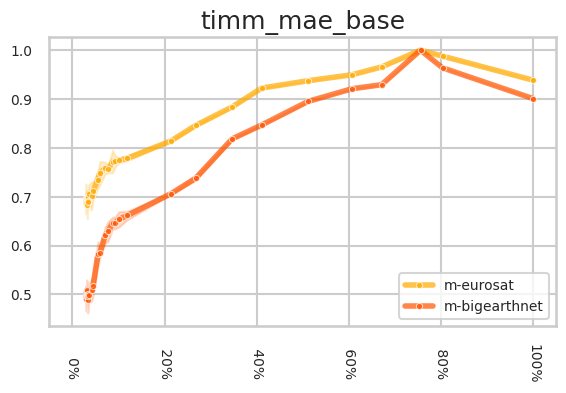

In [34]:
args_list = [(model, dataset, 'knn')
        for model in ['timm_mae_base'] 
        for dataset in ['m-eurosat', 'm-bigearthnet']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)
    
df = pd.concat(dfs)
df['dataset'] = df.dataset.apply(lambda ds: f"ImageNet-{int(ds.split('ImageNet')[-1])}" if 'ImageNet' in ds else ds)

DATASET_COLORS = {
    'CIFAR10':       sns.color_palette('winter', 10)[1],
    'ImageNet-10':   sns.color_palette('cool', 4)[0],
    'ImageNet-20':   sns.color_palette('cool', 4)[1],
    'ImageNet-50':   sns.color_palette('cool', 4)[2],
    'ImageNet-100':  sns.color_palette('cool', 4)[3],
    'm-bigearthnet': sns.color_palette('autumn', 2)[0],
    'm-eurosat':     sns.color_palette('autumn', 2)[1],
}

for mark_axis_legend in [True, False]:
    for original_model_name in df.original_model_name.unique():
        df_mod = df[df.original_model_name == original_model_name]
        fig, ax = plt.subplots(figsize=(6, 4))
        metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]
    
        sns.lineplot(
            data=df_mod,
            x='Exact Rel. Compute Requirement', y='Rel. Retention Rate',
            marker='.', 
            ax=ax, hue='dataset',
            palette=DATASET_COLORS,
            alpha=0.7,
            linewidth=4, errorbar=errorbar_setting
        )
    
        #ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
        ax.xaxis.minorticks_off()
        ax.legend(loc='lower right', fontsize=legend_fontsize)
        if mark_axis_legend:
            ax.set_xlabel('Rel. Compute Requirements')
            ax.set_ylabel('Rel. Retention Rate')
        else:
            ax.set_xlabel('')
            ax.set_ylabel('')
        ax.tick_params(axis='both', which='both', labelsize=10)
        ax.tick_params(axis='x', which='both', labelrotation=-90)
        ax.set_xlim(left=-0.05, right=1.05)
        plt.tight_layout()
        Path(f"{FIGURE_BASE}/cv_baseline_by_rs_dataset").resolve().mkdir(exist_ok=True, parents=True)
        plt.savefig(f"{FIGURE_BASE}/cv_baseline_by_rs_dataset/slimmability_by_cv_dataset_{original_model_name}{'' if mark_axis_legend else '_nolegend'}.pdf")
        plt.title(f"{original_model_name}")  # only print title after saving
        plt.show()

### CV vs RS on RS data

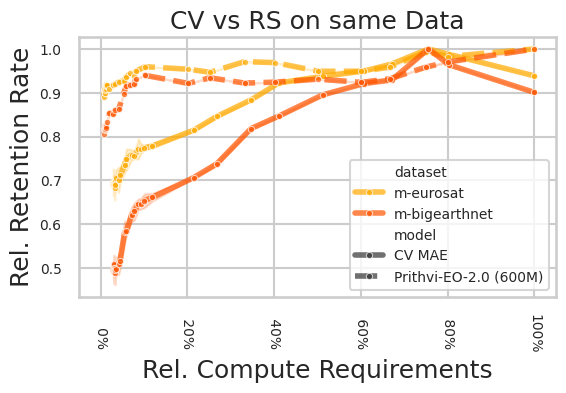

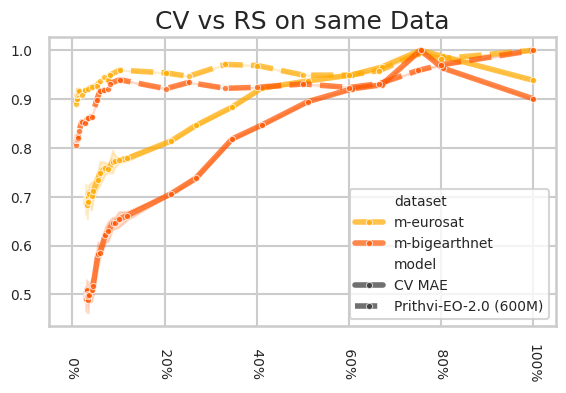

In [35]:
args_list = [(model, dataset, 'knn')
        for model in ['timm_mae_base', 'prithvi2_600'] 
        for dataset in ['m-eurosat', 'm-bigearthnet']]
dfs = []
for args in args_list:
    part_df = read_results(*args)
    dfs.append(part_df)
    
df = pd.concat(dfs)
df['dataset'] = df.dataset.apply(lambda ds: f"ImageNet-{int(ds.split('ImageNet')[-1])}" if 'ImageNet' in ds else ds)

DATASET_COLORS = {
    'CIFAR10':       sns.color_palette('winter', 10)[1],
    'ImageNet-10':   sns.color_palette('cool', 4)[0],
    'ImageNet-20':   sns.color_palette('cool', 4)[1],
    'ImageNet-50':   sns.color_palette('cool', 4)[2],
    'ImageNet-100':  sns.color_palette('cool', 4)[3],
    'm-bigearthnet': sns.color_palette('autumn', 2)[0],
    'm-eurosat':     sns.color_palette('autumn', 2)[1],
}

for mark_axis_legend in [True, False]:
    fig, ax = plt.subplots(figsize=(6, 4))
    metric_str = METRIC_STR[METRIC_ASSIGNMENT[dataset]]

    sns.lineplot(
        data=df,
        x='Exact Rel. Compute Requirement', y='Rel. Retention Rate',
        marker='.', 
        ax=ax, hue='dataset', style='model',
        palette=DATASET_COLORS,
        alpha=0.7,
        linewidth=4, errorbar=errorbar_setting
    )

    #ax.set_xscale('log')
    ax.xaxis.set_major_formatter(FuncFormatter(percent_formatter))
    ax.xaxis.minorticks_off()
    ax.legend(loc='lower right', fontsize=legend_fontsize)
    if mark_axis_legend:
        ax.set_xlabel('Rel. Compute Requirements')
        ax.set_ylabel('Rel. Retention Rate')
    else:
        ax.set_xlabel('')
        ax.set_ylabel('')
    ax.tick_params(axis='both', which='both', labelsize=10)
    ax.tick_params(axis='x', which='both', labelrotation=-90)
    ax.set_xlim(left=-0.05, right=1.05)
    plt.tight_layout()
    Path(f"{FIGURE_BASE}/cv_retention_vc_rs_retention_on_rs_data").resolve().mkdir(exist_ok=True, parents=True)
    plt.savefig(f"{FIGURE_BASE}/cv_retention_vc_rs_retention_on_rs_data/slimmability_by_cv_dataset_{original_model_name}{'' if mark_axis_legend else '_nolegend'}.pdf")
    plt.title(f"CV vs RS on same Data")  # only print title after saving
    plt.show()